# Measuring the Design Decisions of an Open-Source Post-Quantum HSM Chip: ML-KEM-512 NTT and Keccak from Python Golden Model to SKY130 Layout

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tandat08052007/sscs-ose-code-a-chip.github.io/blob/isscc27-hskem-pqc-sky130/ISSCC27/submitted_notebooks/HSKEM_PQC_SKY130/HSKEM_PQC_SKY130.ipynb)

| Name | Affiliation | IEEE Member | SSCS Member | Email |
|:---|:---|:---:|:---:|:---|
| Nguyen Tan Dat | University of Science, VNU-HCM (HCMUS), Faculty of Electronics and Telecommunications | No | No | nguyentandat08052007@gmail.com |

SPDX-License-Identifier: Apache-2.0

IEEE SSCS Open-Source Ecosystem *Code-a-Chip* travel grant, ISSCC 2027 · License: Apache-2.0 (`LICENSE`,
`NOTICE`) · Tools: Python, Yosys, Icarus Verilog, OpenROAD-flow-scripts, OpenSTA, KLayout, Magic, ngspice,
OpenRAM; SKY130

---

### Abstract

HSKEM is a post-quantum hardware security module (HSM), a co-processor that keeps keys in hardware and runs
ML-KEM (FIPS 203), NIST's post-quantum key-encapsulation mechanism (KEM) standard, for a host that is not trusted with the
keys. I designed it, brought
it up on a DE25-Nano FPGA board and implemented it twice as a chip in SKY130, SkyWater's open 130 nm process,
with the open-source OpenROAD place-and-route flow.
The first chip, **HSKEM-1**, made two choices that look sensible for an ASIC because they are meant to save
area. It keeps the coefficients of the number-theoretic transform (NTT), which speeds up ML-KEM's polynomial
multiplication, in a single-port SRAM rather than a larger dual-port store, and it computes the
Keccak-f[1600] permutation behind ML-KEM's hashes one row at a time (row-serialized) instead of one round per
clock. This notebook asks:

> **What did each decision cost in area, latency and energy, from synthesis to the whole system, and what
> does the design still leak?**

The measurements changed the design, and their main lesson is that a block's price depends on its
surroundings. On its own, the row-serialized Keccak saves only about 1 % of area after routing and is nine
times slower, yet it barely lengthened a decapsulation of HSKEM-1 (the operation that recovers a shared key
from a ciphertext, whose cycle count is this notebook's headline measure); once everything else was fast, it
would add a third. The single-port store, cheaper on its own, caused most of the cycles that HSKEM-1 added to
the FPGA design. The second chip, **HSKEM-2**, therefore packs two coefficients into each SRAM word,
runs two butterflies (the NTT's basic step) in parallel and streams data between its blocks, without removing
any security check (two checks now share one read, which Section 13 discusses). It needs 14.5 times fewer clock cycles per decapsulation and, by post-layout estimate,
almost thirteen times less energy. The FPGA board reproduces the cycle count of the RTL simulation to within two hand-over cycles, and
HSKEM-2's final layout meets timing at three process corners and passes layout-versus-schematic (LVS) and
SKY130's KLayout design-rule check (DRC), within the limits of Section 13. Neither chip has been fabricated.
Every number below is recomputed from the committed results, nearly all of them are also guarded by an
assertion (Appendix E.4), and the few development-log figures are marked as such.

**What is new here:**

* **A packed-pair, layer-fused NTT on one single-port, compiler-generated SRAM**: coefficient pairs in each
  memory word with a butterfly per half, as in [13], combined with layer fusion, as in microcontroller software
  [15], and measured on the routed layout (Section 7).
* **A complete HSM whose RTL and FPGA build decapsulate within 3 % of the cycle count of a compact KEM-only
  design** [13], while keeping every check of the HSM (Sections 8, 10, 13); in time, at 50 rather than 161 MHz,
  the board needs over three times theirs (Section 12).
* **One block decision priced in two systems**: the row-serialized Keccak adds 3.9 % to a decapsulation of
  HSKEM-1 and would add 36 % to the streamed system (Section 8).
* **An open SKY130 HSM core signed off at three corners**, with the SRAM macros' clock-to-output times measured
  in SPICE and the routed database published (Section 9).
* **Thirteen results that looked right and were not**, each with the check that exposed it (Section 12).

**Results at a glance:**

| Result | Value | Section |
|:---|:---|:---:|
| Decapsulation, HSKEM-2 vs HSKEM-1 | 6,856 vs 99,537 cycles (14.5× fewer) in RTL simulation of the streamed design (§8), within 3% of [13] in cycles with every check kept; 6,858 on the FPGA board in 100/100 runs; 6,875 in RTL simulation of the signed-off chip | §8–10, §12 |
| Energy per decapsulation, 25 MHz | 27.3 vs 344.1 µJ (12.6× less, post-layout estimate); clock network and register clock pins 71%, SRAM macros 24%, combinational logic 5% | §9 |
| HSKEM-2 layout (signed off) | 11.2 mm² die, 360,355 standard cells, 18 SRAM macros; setup and hold met at the slow, typical and fast corners with SPICE-measured macro clock-to-output and nominal parasitics, assuming that the drivers of the entropy, PUF and service-interface inputs share the core clock tree; 26.9 MHz at the slow corner | §9, App. C |
| HSKEM-2 sign-off | LVS: circuits match uniquely, with the SRAMs verified separately; DRC (KLayout deck): 0 markers once implant gaps inside the macros are closed; routed database published | §9, App. C |
| Correctness | 0 mismatches over 208,896 NTT coefficients and 404 Keccak permutations; 25/25 NIST ACVP key generations byte-exact on the complete RTL, and 25 encapsulation–decapsulation runs on ACVP seeds and messages equal to the golden model; reducer proven for all 2²⁴ inputs; of 10 planted mutants, 8 caught by the testbenches, 1 by the proof, 1 equivalent | §2–4, App. A |
| Forward NTT, HSKEM-1's engine → HSKEM-2's (routed) | 6,274 → 568 cycles, 0.50 → 0.14 µJ (estimate), total area 0.14 → 0.27 mm² | §6–7 |
| Row-serialized Keccak vs one round per clock | 1% less area, 9× slower and 5.5× the energy per permutation; adds 3.9% to a decapsulation of HSKEM-1, 36% to the streamed system | §6, §8 |
| FPGA board, FPGA configuration | 100/100 complete ML-KEM exchanges (both parties on the one board) and 100/100 runs of the HSM's security-rule tests pass | §10 |
| Side channel (simulated leakage test, TVLA) | HSKEM-2's NTT engine leaks unmasked (largest t-statistic 88.2 in the register model, 102.8 on the routed netlist), not with first-order masking (3.2 and 3.3; threshold 4.5) | §11 |

Terms in the table are explained in the sections it cites: NIST's ACVP vectors are the official test
vectors for ML-KEM; mutants are deliberately planted bugs; TVLA is a statistical test that flags power
consumption depending on secret data, with $|t| > 4.5$ meaning detectable leakage; first-order masking splits
a secret into random shares; and the PUF (physically unclonable function) derives a chip-unique key.

**How it is told.** Part I checks correctness, Part II prices HSKEM-1's decisions and follows the
measurements to HSKEM-2, and Part III takes the RTL to the board and asks what it leaks. For a quick
reading, start with the abstract, which introduces HSKEM-1 and HSKEM-2, then watch [the video](https://raw.githubusercontent.com/tandat08052007/sscs-ose-code-a-chip.github.io/isscc27-hskem-pqc-sky130/ISSCC27/submitted_notebooks/HSKEM_PQC_SKY130/figures/hskem2_tour.mp4) below and look at
the table above, the chip figure of Section 9, the lessons of Section 12 and the limits of Section 13.

In [1]:
from IPython.display import HTML, display
# streamed from GitHub, not embedded, so that the notebook stays small; zoom from scripts/render_zoom_frames.py, decapsulation from scripts/make_decaps_video.py, board from scripts/make_board_clip.py
VIDEO_URL = "https://raw.githubusercontent.com/tandat08052007/sscs-ose-code-a-chip.github.io/isscc27-hskem-pqc-sky130/ISSCC27/submitted_notebooks/HSKEM_PQC_SKY130/figures/hskem2_tour.mp4"
display(HTML(f'<video src="{VIDEO_URL}" width="860" controls muted playsinline></video>'
             f'<p>A zoom into the signed-off layout, one decapsulation from the RTL simulation, and the board. If the video does not play, <a href="{VIDEO_URL}" target="_blank">open it here</a>.</p>'))

## 0. Setup

The next cell runs locally or on Google Colab, where it fetches what the notebook needs; every step uses
open-source tools, except the Quartus-built FPGA bitstream of Section 10.

| Fetched in Colab | Why |
|:---|:---|
| this folder (sparse clone of the author's fork) | sources, committed results, figures |
| [YosysHQ OSS CAD Suite](https://github.com/YosysHQ/oss-cad-suite-build), about 700 MB | Yosys with `slang` and Icarus Verilog for Sections 3–7 |
| `kyber-py` (pip) | an independent NTT for Section 2 |
| one block GDS from the release, KLayout (pip) | the layout rendered in Appendix B.2 |

Place-and-route outlasts a Colab session, so its results are read from `results/asic/`; Appendix E gives
run times, tool versions and how to regenerate every result.

In [2]:
import os, sys, subprocess, pathlib, json, shutil, time
T_START = time.time()

IN_COLAB = "google.colab" in sys.modules or os.environ.get("CAC_EMULATE_COLAB") == "1"   # the latter: local rehearsal
# Where the submission folder lives when this notebook is opened stand-alone in Colab.
# Before the pull request is merged the files live on the author's fork/branch;
# afterwards REPO_URL = "https://github.com/sscs-ose/sscs-ose-code-a-chip.github.io", REPO_BRANCH = "main".
REPO_URL = "https://github.com/tandat08052007/sscs-ose-code-a-chip.github.io"
REPO_BRANCH = "isscc27-hskem-pqc-sky130"
UPSTREAM_URL = "https://github.com/sscs-ose/sscs-ose-code-a-chip.github.io"      # the submission lives here after the merge
SUBDIR = "ISSCC27/submitted_notebooks/HSKEM_PQC_SKY130"
OSS_CAD_TAG = "2026-09-28"
RUN_PNR = False          # True = rerun OpenROAD-flow-scripts (Linux + ORFS install required)

if pathlib.Path("golden/mlkem_ref.py").exists():
    ROOT = pathlib.Path.cwd()
else:
    if not pathlib.Path("cac").exists():
        for src_url, src_branch in ((REPO_URL, REPO_BRANCH), (UPSTREAM_URL, "main")):
            r = subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse", "--branch", src_branch, src_url, "cac"],
                               capture_output=True, text=True)
            if r.returncode == 0:
                print("source   ", src_url.split("github.com/")[1], "branch", src_branch)
                break
            shutil.rmtree("cac", ignore_errors=True)
            print(f"could not clone {src_url} branch {src_branch}: {r.stderr.strip()[-200:]}")
        else:
            raise RuntimeError("Neither the fork branch nor the upstream repository could be cloned; check the network and the URLs above.")
        subprocess.run(["git", "-C", "cac", "sparse-checkout", "set", SUBDIR], check=True)
    ROOT = pathlib.Path("cac", SUBDIR).resolve()
os.chdir(ROOT)

def have(tool): return shutil.which(tool) is not None

if not (have("yosys") and have("iverilog")):
    tgz = f"oss-cad-suite-linux-x64-{OSS_CAD_TAG.replace('-', '')}.tgz"
    url = f"https://github.com/YosysHQ/oss-cad-suite-build/releases/download/{OSS_CAD_TAG}/{tgz}"
    if not pathlib.Path("/content/oss-cad-suite").exists() and IN_COLAB:
        got = subprocess.run(["curl", "-fsSL", "-o", f"/content/{tgz}", url])
        if got.returncode:
            raise RuntimeError(f"Download of the OSS CAD Suite failed (curl exit status {got.returncode}): {url}")
        if subprocess.run(["tar", "xzf", f"/content/{tgz}", "-C", "/content"]).returncode:
            raise RuntimeError(f"The OSS CAD Suite archive /content/{tgz} could not be extracted; delete it and run the cell again.")
        os.remove(f"/content/{tgz}")
        print("OSS CAD Suite", OSS_CAD_TAG, "downloaded and unpacked")
    os.environ["PATH"] = "/content/oss-cad-suite/bin:" + os.environ["PATH"]
_pip = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", "kyber-py==1.2.0", "pytest"],
                      capture_output=True, text=True)
if _pip.returncode:
    print("pip install of kyber-py and pytest failed; Section 2's cross-check and Appendix A's tests will fail:\n", _pip.stderr[-800:])

for t, flag in (("yosys", "-V"), ("iverilog", "-V")):
    v = subprocess.run([t, flag], capture_output=True, text=True).stdout.splitlines()
    print(f"{t:9s}", v[0] if v else "not found")
print("python   ", sys.version.split()[0])
print("running  ", "in Colab" if IN_COLAB else "locally")

yosys     Yosys 0.9 (git sha1 1979e0b)
iverilog  Icarus Verilog version 11.0 (stable) ()
python    3.10.12
running   locally


In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, SVG, display, Markdown
sys.path.insert(0, str(ROOT / "scripts"))
import plotstyle as ps          # validated palette, recessive axes, thin marks
ps.apply()
import nbdisplay as nbd         # table alignment and the per-section run timer
nbd.install()
# readable names, and one fixed colour per design point (colour follows the entity)
LABEL = {"ntt_dp": "original NTT, dual-port store", "ntt_sp": "original NTT, single-port store",
         "keccak_r1": "Keccak, one round per clock", "keccak_s7": "Keccak, row-serialized",
         "ntt_opt_b1_w12": "iteration 1: 12-bit store", "ntt_opt_pipe_w12": "iteration 1: 12-bit store + pipeline",
         "ntt_macro": "original NTT, 16 × 256 macro (HSKEM-1)", "ntt_opt_pipe_macro": "iteration 1: pipeline, 16 × 256 macro",
         "ntt_packed": "iteration 2: packed pairs, 24 × 128 macro",
         "ntt_packed2": "iteration 3: two lanes, 24 × 128 macro (HSKEM-2)"}
COLOR = {"ntt_dp": ps.NTT_ALT, "ntt_sp": ps.NTT, "keccak_r1": ps.KECCAK_ALT,
         "keccak_s7": ps.KECCAK, "ntt_opt_b1_w12": ps.IT1_STEP, "ntt_opt_pipe_w12": ps.IT1,
         "ntt_macro": ps.NTT, "ntt_opt_pipe_macro": ps.IT1, "ntt_packed": ps.IT2,
         "ntt_packed2": ps.IT3}
nbd.VALUES.update(LABEL)        # tables show these names instead of the run identifiers
# readable names of the HSKEM blocks in the chip-level results (Appendix C)
BLOCK = {"g_qualification_puf_vault": "PUF root and key vault", "u_shared_mlkem_sponge": "Keccak sponge (shared)",
         "u_hsm_shell": "HSM policy shell", "u_security_hmac": "HMAC-SHA-256", "u_mlkem512_decaps_partial": "ML-KEM decapsulation",
         "u_c2_shake_drbg": "SHAKE DRBG", "u_mlkem512_kpke_partial": "ML-KEM K-PKE / matrix", "u_bridge": "SPI command bridge",
         "u_spi": "SPI front end", "(top-level registers)": "top-level registers", "u_mlkem512_encaps_partial": "ML-KEM encapsulation",
         "u_puf": "PUF interface", "u_shared_ntt": "NTT engine (shared)", "u_c3_pk_pair_sram": "public-key buffer"}
sys.path.insert(0, str(ROOT / "golden"))
import mlkem_ref as ref
import re
def total_area(run):
    # standard-cell and macro area of a routed run, from its final ORFS report
    j = json.loads(next((ROOT/"results/asic"/run/"logs").rglob("6_report.json")).read_text())
    return j["finish__design__instance__area__stdcell"], j.get("finish__design__instance__area__macros", 0.0)
def slew_violations(run, cells_only=False):
    # number of max-slew violations in the final report of a routed run (cells_only: without the SRAM
    # macro's own pins, which Appendix B.4 measures separately)
    rpt = next((ROOT/"results/asic"/run/"reports").rglob("6_finish.rpt")).read_text()
    sec = rpt.split("report_check_types -max_slew", 1)[1].split("=====", 1)[0]
    slew = sec.split("max slew", 1)[1] if "max slew" in sec else ""       # only the max-slew table
    slew = re.split(r"\nmax (?:capacitance|fanout)", slew)[0]
    return len([l for l in slew.splitlines() if "(VIOLATED)" in l and not (cells_only and "u_macro/" in l)])
def energy_spread(run):
    # energy of the committed input and of four further random inputs (seeds 1-4, results/gls_power/<run>_seed*)
    e = [next(v for k, v in json.loads((ROOT/"results/gls_power"/d/"summary.json").read_text()).items()
              if k.startswith("energy_per")) for d in [run] + [f"{run}_seed{i}" for i in (1, 2, 3, 4)]]
    return 100 * (max(e) - min(e)) / np.mean(e)
def sh(cmd, quiet=False):
    # run a shell command from the submission folder; quiet: print its output only if it fails
    r = subprocess.run(cmd, shell=True, cwd=ROOT, capture_output=True, text=True)
    if not quiet or r.returncode:
        print(r.stdout[-4000:], r.stderr[-2000:])
    r.check_returncode(); return r.stdout

### The method at a glance

The figure maps the method to the sections; the cell also checks every value of the first page's results
table.

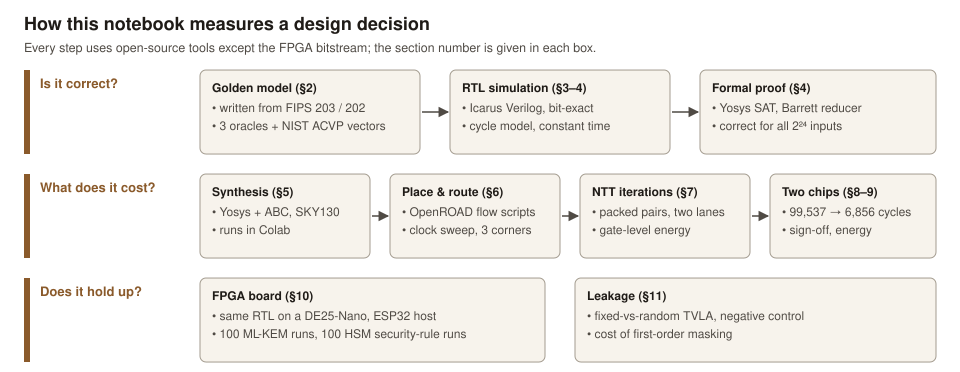

results table on the first page: all 9 rows agree with the committed results


In [4]:
import re
display(SVG(filename=str(ROOT/"figures/method_flow.svg")))
R_ = ROOT/"results"
sim_logs = " ".join((R_/"sim"/f"{n}.log").read_text() for n in ["ntt_dualport", "ntt_singleport", "keccak_round", "keccak_serial"])
n_err = sum(int(e) for e in re.findall(r"errors=(\d+)", sim_logs))
n_coef = sum(int(c) for c in re.findall(r"coeffs_checked=(\d+)", sim_logs))
n_kec = sum(int(v) for v in re.findall(r"KECCAK_RESULT serial=\d vectors=(\d+)", sim_logs))
assert n_err == 0 and set(re.findall(r"timing_variations=(\d+)", sim_logs)) == {"0"}
proofs = json.loads((R_/"formal/summary.json").read_text())["results"]
acvp_rtl = json.loads((R_/"acvp_rtl/keygen_asic.json").read_text())
assert all(json.loads((R_/f"acvp_rtl/keygen_{c}.json").read_text())["passed"] == 25 for c in ("fpga", "asic"))
dse =pd.read_csv(R_/"dse_metrics.csv").set_index(["variant", "clk_target_ns"])
o, n = dse.loc[("ntt_sp", 20.0)], dse.loc[("ntt_opt_pipe_w12", 20.0)]
gls = {r: json.loads((R_/"gls_power"/r/"summary.json").read_text()) for r in ["ntt_sp_20ns", "ntt_opt_b1_w12_20ns", "ntt_opt_pipe_w12_20ns"]}
e_uj = {r: g["energy_per_forward_ntt_nj"] / 1e3 for r, g in gls.items()}
e_macro = json.loads((R_/"gls_power/ntt_macro_20ns/summary.json").read_text())["energy_per_forward_ntt_nj"] / 1e3
pkd, mac0 = dse.loc[("ntt_packed", 20.0)], dse.loc[("ntt_macro", 20.0)]
e_pk = json.loads((R_/"gls_power/ntt_packed_20ns/summary.json").read_text())["energy_per_forward_ntt_nj"] / 1e3
a_m0, a_pk = (sum(total_area(r)) for r in ("ntt_macro_20ns", "ntt_packed_20ns"))
psy_ = json.loads((R_/"system_sim/packed_system.json").read_text())["steps"]
ssy_ = json.loads((R_/"system_sim/streamed_system.json").read_text())
fbd_ = pd.read_csv(R_/"fpga/revc_c3_repeat.csv")
kj = {v: json.loads((R_/"gls_power"/f"{v}_20ns"/"summary.json").read_text())["energy_per_permutation_nj"]
      for v in ["keccak_r1", "keccak_s7"]}
prof_ = {c: v["profile"] for c, v in json.loads((R_/"system_sim/decaps_profile.json").read_text())["configs"].items()}
c3 = pd.read_csv(R_/"fpga/c3_repeat.csv"); bank_ = pd.read_csv(R_/"fpga/bank_repeat.csv")
tg_ = {k: json.loads((R_/d/"tvla_summary.json").read_text()) for k, d in [("plain", "leakage_gls"), ("masked", "leakage_gls_masked")]}
tv = {k: json.loads((R_/d/"tvla_summary.json").read_text()) for k, d in [("plain", "leakage"), ("masked", "leakage_masked"),
                                                                           ("plain2", "leakage_packed2"), ("masked2", "leakage_masked_packed2")]}
feolc_ = json.loads((R_/"fullchip/rev_c/feol_drc.json").read_text())          # HSKEM-2 signed-off chip (release tag rev-c)
chip = json.loads((R_/"fullchip/rev_c/summary.json").read_text()); cm = chip["orfs_metrics"]
pw_ = json.loads((R_/"fullchip/rev_c/power.json").read_text())
e_ = {k: v * pw_["window_cycles"] * pw_["clock_ns"] * 1e-6 for k, v in pw_["power_mw"].items()}   # uJ per decapsulation
e_["sram"] = json.loads((R_/"fullchip/rev_c/sram_energy.json").read_text())["sram_energy_per_decaps_uj"]
e_tot = sum(e_.values())
def chip_energy_uj(d):
    # logic and SRAM energy per decapsulation of a chip-level result directory
    p = json.loads((d/"power.json").read_text())
    return p["logic_power_mw"] * p["window_cycles"] * p["clock_ns"] * 1e-6 + \
           json.loads((d/"sram_energy.json").read_text())["sram_energy_per_decaps_uj"]
e_first = chip_energy_uj(R_/"fullchip/first_chip")
h_ = ssy_["decaps_cycles"]["H"]
e_p2 = json.loads((R_/"gls_power/ntt_packed2_20ns/summary.json").read_text())["energy_per_forward_ntt_nj"] / 1e3
a_p2 = sum(total_area("ntt_packed2_20ns"))
st_b = json.loads((R_/"fullchip/rev_c/sta_corners.json").read_text())["runs"]
fx_b = json.loads((R_/"fullchip/rev_c/sta_corners.json").read_text())["fmax_search"]   # fmax by period bisection
cyc_b_ = int(re.search(r"U1 Decaps busy latency valid/implicit-rejection=(\d+)",
                       (R_/"fullchip/rev_c/tb_trustedge_spi_rev_c.log").read_text(errors="replace"))[1])
ed_ = json.loads((R_/"acvp_rtl/encdec_rev_c.json").read_text())
mu_g = json.loads((R_/"mutation/summary.json").read_text())
kr_, ks_ = dse.loc[("keccak_r1", 20.0)], dse.loc[("keccak_s7", 20.0)]
cfg_ = {k: int(v["decaps_cycles"]) for k, v in json.loads((R_/"system_sim/summary.json").read_text())["configs"].items()}
rows = [
    ("Decapsulation, HSKEM-2 vs HSKEM-1",
     f"{h_['sram_only']:,} vs {psy_['published']:,} cycles ({psy_['published'] / h_['sram_only']:.1f}× fewer) in RTL simulation "
     f"of the streamed design (§8), within {100 * (h_['sram_only'] / 6668 - 1):.0f}% of [13] in cycles with every check kept; "
     f"{int(fbd_.decaps_cycles.iloc[0]):,} on the FPGA board in {len(fbd_)}/{len(fbd_)} runs; {cyc_b_:,} in RTL simulation "
     "of the signed-off chip", "§8–10, §12"),
    ("Energy per decapsulation, 25 MHz",
     f"{e_tot:.1f} vs {e_first:.1f} µJ ({e_first / e_tot:.1f}× less, post-layout estimate); clock network and register clock pins "
     f"{(e_['clock'] + e_['sequential']) / e_tot:.0%}, SRAM macros {e_['sram'] / e_tot:.0%}, combinational logic "
     f"{e_['combinational'] / e_tot:.0%}", "§9"),
    ("HSKEM-2 layout (signed off)",
     f"{cm['finish__design__die__area'] / 1e6:.1f} mm² die, {cm['finish__design__instance__count__stdcell']:,} standard cells, "
     f"{cm['finish__design__instance__count__macros']} SRAM macros; setup and hold met at the slow, typical and fast corners "
     f"with SPICE-measured macro clock-to-output and nominal parasitics, assuming that the drivers of the entropy, "
     f"PUF and service-interface inputs share the core clock tree; {fx_b['ss']['fmax_mhz']:.1f} MHz at the slow corner",
     "§9, App. C"),
    ("HSKEM-2 sign-off",
     f"LVS: {chip['signoff']['primary_compare'].lower()}, with the SRAMs verified separately; DRC (KLayout deck): "
     f"{chip['signoff']['drc_markers'] + feolc_['after_implant_fix']['markers_total']} markers once implant gaps inside the "
     f"macros are closed; routed database published", "§9, App. C"),
    ("Correctness",
     f"{n_err} mismatches over {n_coef:,} NTT coefficients and {n_kec} Keccak permutations; {acvp_rtl['passed']}/{acvp_rtl['cases']} "
     f"NIST ACVP key generations byte-exact on the complete RTL, and {ed_['passed']} encapsulation–decapsulation runs on ACVP "
     f"seeds and messages equal to the golden model; reducer proven for all 2²⁴ inputs; of {mu_g['total']} planted mutants, "
     f"{mu_g['caught_by_simulation']} caught by the testbenches, {mu_g['caught'] - mu_g['caught_by_simulation']} by the "
     f"proof, {mu_g['equivalent']} equivalent", "§2–4, App. A"),
    ("Forward NTT, HSKEM-1's engine → HSKEM-2's (routed)",
     f"{int(mac0.cycles):,} → {int(dse.loc[('ntt_packed2', 20.0)].cycles)} cycles, {e_macro:.2f} → {e_p2:.2f} µJ (estimate), "
     f"total area {a_m0 / 1e6:.2f} → {a_p2 / 1e6:.2f} mm²", "§6–7"),
    ("Row-serialized Keccak vs one round per clock",
     f"{1 - ks_.cell_area_um2 / kr_.cell_area_um2:.0%} less area, {ks_.latency_us_at_fmax / kr_.latency_us_at_fmax:.0f}× slower and "
     f"{kj['keccak_s7'] / kj['keccak_r1']:.1f}× the energy per permutation; adds {cfg_['asic'] / cfg_['sram_only'] - 1:.1%} to a "
     f"decapsulation of HSKEM-1, {h_['asic'] / h_['sram_only'] - 1:.0%} to the streamed system", "§6, §8"),
    ("FPGA board, FPGA configuration",
     f"{int(c3.result_pass.sum())}/{len(c3)} complete ML-KEM exchanges (both parties on the one board) and "
     f"{int((bank_.filter(like='bank_') == 'PASS').all(axis=1).sum())}/{len(bank_)} runs of the HSM's security-rule "
     "tests pass", "§10"),
    ("Side channel (simulated leakage test, TVLA)",
     f"HSKEM-2's NTT engine leaks unmasked (largest t-statistic {tv['plain2']['max_abs_t']:.1f} in the register model, "
     f"{tg_['plain']['max_abs_t']:.1f} on the routed netlist), not with first-order masking "
     f"({tv['masked2']['max_abs_t']:.1f} and {tg_['masked']['max_abs_t']:.1f}; threshold 4.5)", "§11"),
]
GLANCE = [('Decapsulation, HSKEM-2 vs HSKEM-1', '6,856 vs 99,537 cycles (14.5× fewer) in RTL simulation of the streamed design (§8), within 3% of [13] in cycles with every check kept; 6,858 on the FPGA board in 100/100 runs; 6,875 in RTL simulation of the signed-off chip', '§8–10, §12'), ('Energy per decapsulation, 25 MHz', '27.3 vs 344.1 µJ (12.6× less, post-layout estimate); clock network and register clock pins 71%, SRAM macros 24%, combinational logic 5%', '§9'), ('HSKEM-2 layout (signed off)', '11.2 mm² die, 360,355 standard cells, 18 SRAM macros; setup and hold met at the slow, typical and fast corners with SPICE-measured macro clock-to-output and nominal parasitics, assuming that the drivers of the entropy, PUF and service-interface inputs share the core clock tree; 26.9 MHz at the slow corner', '§9, App. C'), ('HSKEM-2 sign-off', 'LVS: circuits match uniquely, with the SRAMs verified separately; DRC (KLayout deck): 0 markers once implant gaps inside the macros are closed; routed database published', '§9, App. C'), ('Correctness', '0 mismatches over 208,896 NTT coefficients and 404 Keccak permutations; 25/25 NIST ACVP key generations byte-exact on the complete RTL, and 25 encapsulation–decapsulation runs on ACVP seeds and messages equal to the golden model; reducer proven for all 2²⁴ inputs; of 10 planted mutants, 8 caught by the testbenches, 1 by the proof, 1 equivalent', '§2–4, App. A'), ("Forward NTT, HSKEM-1's engine → HSKEM-2's (routed)", '6,274 → 568 cycles, 0.50 → 0.14 µJ (estimate), total area 0.14 → 0.27 mm²', '§6–7'), ('Row-serialized Keccak vs one round per clock', '1% less area, 9× slower and 5.5× the energy per permutation; adds 3.9% to a decapsulation of HSKEM-1, 36% to the streamed system', '§6, §8'), ('FPGA board, FPGA configuration', "100/100 complete ML-KEM exchanges (both parties on the one board) and 100/100 runs of the HSM's security-rule tests pass", '§10'), ('Side channel (simulated leakage test, TVLA)', "HSKEM-2's NTT engine leaks unmasked (largest t-statistic 88.2 in the register model, 102.8 on the routed netlist), not with first-order masking (3.2 and 3.3; threshold 4.5)", '§11')]
assert rows == GLANCE, [(r, g) for r, g in zip(rows, GLANCE) if r != g]   # the table on the first page
# the results quoted in the abstract and above the figure (83/48 MHz is now quoted in Section 7)
assert tv["masked2"]["max_abs_t"] < 4.5 < tv["plain2"]["max_abs_t"]
assert tg_["masked"]["max_abs_t"] < 4.5 < tg_["plain"]["max_abs_t"]
assert chip["signoff"]["drc_markers"] == 0 and feolc_["after_implant_fix"]["markers_total"] == 0
mac0, mac1 = dse.loc[("ntt_macro", 20.0)], dse.loc[("ntt_opt_pipe_macro", 20.0)]
assert round(mac0.fmax_mhz) == 48 and round(mac1.fmax_mhz) == 83
assert 1.6 < n.fmax_mhz / o.fmax_mhz < 1.75 and 0.5 < n.at_product / o.at_product < 0.6
sysd = json.loads((R_/"system_sim/summary.json").read_text())
assert sysd["decomposition"]["keccak_serial_delta"] / int(sysd["configs"]["fpga"]["decaps_cycles"]) < 0.05
assert prof_["fpga"]["perm_busy"] / prof_["fpga"]["cycles"] < 0.01 and 0.45 < prof_["fpga"]["ntt_busy"] / prof_["fpga"]["cycles"] < 0.55
assert 8.5 < mac0.latency_us_at_fmax / pkd.latency_us_at_fmax < 9.5 and 0.28 < e_pk / e_macro < 0.38   # "nine times", "a third"
assert (psy_["published"], psy_["D"]) == (99537, 36110)
assert all(ssy_["checks"].values()) and ssy_["decaps_cycles"]["H"]["sram_only"] == 6856
assert fbd_.result_pass.all() and (fbd_.decaps_cycles == 6858).all()
assert 12.5 < e_first / e_tot < 13.4 and 26 < e_tot < 27.5                  # "thirteen times less", "about 27 µJ"
assert 14.4 < psy_["published"] / h_["sram_only"] < 14.6                     # "14.5 times fewer"
assert dse.loc[("ntt_packed2", 20.0)].cycles == 568 and pkd.cycles == 988
assert pw_["window_cycles"] + 1 == cyc_b_ == ssy_["decaps_cycles"]["H"]["sram_only"] + 19   # revision C: the final design + 19 cycles
assert ed_["passed"] == len(ed_["details"]) == 25 and all(d["c"] and d["K_enc"] and d["K_dec"] and d["K_rej"] for d in ed_["details"])
assert pw_["vcd_time_stretch"] == 4                                           # activity read at the chip's 40 ns clock
assert 0.03 < cfg_["asic"] / cfg_["sram_only"] - 1 < 0.04 and 0.33 < h_["asic"] / h_["sram_only"] - 1 < 0.37   # "about a third"
print(f"results table on the first page: all {len(rows)} rows agree with the committed results")

## 1. Context: where these blocks sit in HSKEM

HSKEM is a security co-processor that keeps every secret on chip while an ESP32 host issues commands over
SPI. It runs ML-KEM-512, the smallest of ML-KEM's three parameter sets, through key generation, encapsulation
and decapsulation, derives a device root key from a
ring-oscillator physically unclonable function (PUF) and wraps (encrypts and authenticates) keys under it; the
host keeps two wrapped copies in alternate slots of its flash, so that the newest valid one survives a power loss. I built it on the DE25-Nano board, where it occupies about 39,000 adaptive logic modules (ALMs) at 50 MHz, and ported its digital
core to SKY130 (block diagram after the notation table).

Open-source silicon roots of trust such as OpenTitan and Caliptra put a microcontroller in charge of the keys: OpenTitan runs ML-KEM on its OTBN big-number
coprocessor [16],
and Caliptra 2.1 can keep keys in a vault that firmware cannot read while its microcontroller sequences every
operation [17]. HSKEM is narrower: no processor is part of what must be trusted, and its shared secret reaches only a
hardware session service, which protects the host's messages and, as IPsec does [18], checks each message's
counter before its HMAC, a keyed hash that authenticates the message.

Two blocks carry most of ML-KEM's work, and they are the ones this notebook prices. Its arithmetic acts on
polynomials in $\mathbb{Z}_{3329}[X]/(X^{256}+1)$, that is, polynomials of degree below 256 whose coefficients
are integers modulo 3329 and whose products wrap around because $X^{256} = -1$; the NTT accelerates their
multiplication. Its hashing and sampling run on Keccak-f[1600] [2, 4], the permutation behind SHA-3 and its
variable-output-length variant SHAKE. The *same RTL* serves the FPGA and both
SKY130 chips. HSKEM-1 used single-port (1rw) macros from OpenRAM, the open-source SRAM compiler, throughout,
and the three implementations differ in the following choices:

| Block | FPGA | HSKEM-1, first integration | HSKEM-2, signed-off chip |
|:---|:---|:---|:---|
| NTT coefficient store | true dual-port RAM (one M20K block, the FPGA's 20-kbit block RAM) | single-port 16 × 256 OpenRAM macro, one coefficient per word | single-port 24 × 128 OpenRAM macro, two coefficients per word, two butterfly lanes (Section 7) |
| Keccak round | one full round per clock | row-serialized round (seven clocks), expected to save standard cells | one full round per clock (Section 8) |
| Datapath around the engines | original | original | streamed, every check kept (Section 8) |


**Notation.** The terms of ML-KEM [1] and SHA-3 [2] used below; others are defined where they first
appear.

| Term | Meaning |
|:---|:---|
| $q = 3329$ | the prime modulus of ML-KEM; every coefficient is an integer from 0 to $q-1$ |
| polynomial | 256 coefficients; products of two polynomials wrap around with a sign change, written $\bmod\,(X^{256}+1)$ |
| NTT | the number-theoretic transform, an FFT over the integers modulo $q$; ML-KEM's version stops at pairs of coefficients, so it turns a polynomial product into 128 products of coefficient pairs, written $\circ$ (the pointwise products of Section 8) |
| butterfly, layer, len | a transform has 7 layers of 128 butterflies; a butterfly combines two coefficients $a_j$ and $a_{j+\mathrm{len}}$ with a twiddle factor, a power of $\zeta = 17$, and the distance len halves from 128 to 2 from layer to layer; $\mathrm{BitRev}_7(i)$, which orders the twiddle factors, is the 7-bit index $i$ with its bits reversed |
| Barrett reduction, $M$ | computes $x \bmod q$ with a multiplication by the constant $M = \lfloor 2^{24}/q \rfloor = 5039$ and a subtraction instead of a division |
| Keccak-f[1600], sponge | the 1600-bit permutation behind SHA-3 and SHAKE; its state is 5 × 5 lanes of 64 bits, and a row is five lanes; the sponge absorbs input bytes into the state, runs the permutation and squeezes output bytes out; in ML-KEM it expands the public matrix, samples noise (small random polynomials) and hashes keys and ciphertexts |
| 16 × 256, 24 × 128 | SRAM macro sizes, bits per word × words: 4096 bits holding one coefficient per word, and 3072 bits holding two 12-bit coefficients per word |
| KeyGen, Encaps, Decaps | key generation; encapsulation, which turns the public (encapsulation) key ek into a ciphertext $c$ and a shared key $K$; decapsulation, which recovers $K$ from $c$ with the secret (decapsulation) key dk |
| $k$, $d$, $G$, $\|$ | $k = 2$ is the module rank of ML-KEM-512, the number of polynomials per vector (3 in ML-KEM-768); $d$ is the 32-byte key-generation seed; $G$ is SHA3-512, which turns $d\,\|\,k$ into the public seed $\rho$ and a noise seed; $\|$ means concatenation |
| $H$, $J$, $\rho$, $z$ | $H(\mathrm{ek})$ and $H(c)$ are SHA-3 hashes of the public key and the ciphertext; $J(z\,\|\,c)$ is the key returned for an invalid ciphertext, derived from a secret value $z$ and $c$; $\rho$ is the public seed from which the public matrix is generated |
| implicit rejection | decapsulation re-encrypts the recovered message and compares the result with $c$; if they differ, it returns $J(z\,\|\,c)$ instead of an error, so that a forged ciphertext reveals nothing, and both cases must take equally long |
| session, frame, binding | the session service protects the host's messages with the agreed key; a frame is one protected message with its counter and HMAC tag; binding ties a session to an agreed key; zeroize erases the keys |

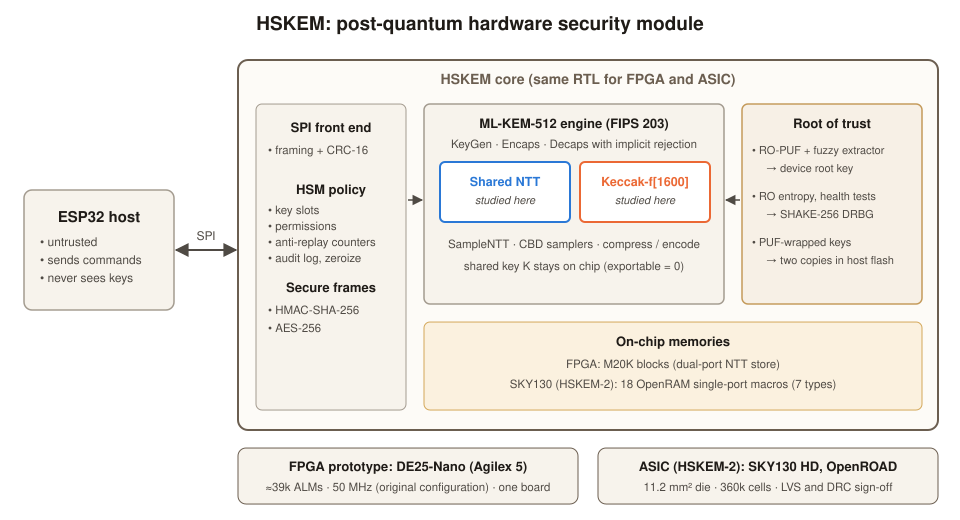

In [5]:
display(SVG(filename=str(ROOT/"figures/hskem_architecture.svg")))
assert f'{round(cm["finish__design__instance__count__stdcell"] / 1e3)}k cells' in (ROOT/"figures/hskem_architecture.svg").read_text(encoding="utf-8")   # the signed-off chip

# Part I — Is it correct?

A cost is only worth measuring for a design that computes the right result, so this part checks the RTL
against references that owe nothing to it.

## 2. An independent golden model

The model (`golden/mlkem_ref.py`) follows FIPS 203 and FIPS 202 alone [1, 2]; even its twiddle factors,
the powers $\zeta^{\mathrm{BitRev}_7(i)}$ modulo $q$, are recomputed from the standard rather than copied
from the RTL. Three oracles that share no code with it check it:

1. **Mathematics:** $\mathrm{NTT}^{-1}(\mathrm{NTT}(a) \circ \mathrm{NTT}(b))$ must equal the schoolbook (term-by-term) negacyclic product $a\cdot b \bmod (X^{256}+1)$, the product
with wrap-around and sign change.
2. **An independent implementation:** the NTT must agree with [`kyber-py`](https://github.com/GiacomoPope/kyber-py) [12].
3. **The Python standard library:** a SHA3-256 sponge built on my Keccak-f must reproduce `hashlib.sha3_256`.

In [6]:
chk_ = ref.self_check(trials=50)            # raises if any oracle disagrees
print("first twiddle factors ζ^BitRev7(i) mod q:", ref.ZETAS[:8], "| 128⁻¹ mod q =", ref.INV128)
print(f"oracles passed: {chk_['ntt_trials']} random products against the schoolbook product, "
      f"{chk_['kyber_py_crosscheck']} transforms against kyber-py, SHA3-256 at {chk_['sha3_lengths']} message lengths")

first twiddle factors ζ^BitRev7(i) mod q: [1, 1729, 2580, 3289, 2642, 630, 1897, 848] | 128⁻¹ mod q = 3303
oracles passed: 50 random products against the schoolbook product, 50 transforms against kyber-py, SHA3-256 at 6 message lengths


### From blocks to the whole KEM: NIST ACVP vectors

On top of these blocks, `golden/mlkem_full.py` implements the complete ML-KEM-512 scheme and is checked
against the official vectors of NIST's Automated Cryptographic Validation Protocol (ACVP) [3], stored with
their provenance in `golden/acvp/`: 25 key generations, 25 encapsulations and 10 decapsulations, some with
modified ciphertexts. Two negative controls show that the check can fail: a flipped input bit must change
the result, and a tampered ciphertext must decapsulate to the implicit-rejection key $J(z\,\|\,c)$.

In [7]:
import mlkem_full as kem
acvp = kem.acvp_check()
print("NIST ACVP ML-KEM-512:", acvp)
assert all(v.split("/")[0] == v.split("/")[1] for v in acvp.values())

x = bytes.fromhex
tv = json.loads((ROOT/"golden/acvp/mlkem512_keygen.json").read_text())[0]
d = bytearray(x(tv["d"])); d[0] ^= 1
assert kem.keygen_internal(bytes(d), x(tv["z"]))[0] != x(tv["ek"]), "negative control failed"
dv = [t for t in json.loads((ROOT/"golden/acvp/mlkem512_encapdecap.json").read_text())["decapsulation"]
      if t["reason"] == "valid decapsulation"][0]
c = bytearray(x(dv["c"])); c[10] ^= 1
k_rej = kem.decaps_internal(x(dv["dk"]), bytes(c))
assert k_rej != x(dv["k"]) and k_rej == kem.J(x(dv["dk"])[-32:] + bytes(c)), "implicit rejection failed"
print("negative controls: PASS (flipped d -> different ek; tampered c -> J(z||c))")

NIST ACVP ML-KEM-512: {'keyGen': '25/25', 'encapsulation': '25/25', 'decapsulation': '10/10'}
negative controls: PASS (flipped d -> different ek; tampered c -> J(z||c))


## 3. RTL architecture and an analytical cycle model

The original NTT engine (`rtl/kyber_ntt_engine.sv`, figure below) computes one butterfly at a time with a
single multiplier and a Barrett reducer [5]; its single-port variant needs two extra states, because both operands and both results take
turns on one SRAM port:

| State | Dual-port | Single-port |
|:---|:---|:---|
| FETCH | read $a_j$, $a_{j+len}$ | read $a_j$ |
| CAPTURE | latch both | latch $a_j$, read $a_{j+len}$ |
| CAPTURE_B | — | latch $a_{j+len}$ |
| REDUCE | $\zeta\cdot b$, Barrett reduction | same |
| EXEC | add / subtract mod $q$ | same |
| WRITE | write both | write $a_j$ |
| WRITE_B | — | write $a_{j+len}$ |

With 896 butterflies and one start and one completion cycle, a forward NTT should therefore take
$896 \times 5 + 2$ cycles with the dual-port store and $896 \times 7 + 2$ with the single-port one; the
inverse adds a scaling pass of $256 \times 5$ cycles. `rtl/keccak_f1600_iter.sv` needs $24 + 1$ cycles
per permutation with one round per clock, and $24\times 7 + 1$ when each round is split into seven phases
(θ, ρ, π, χ and ι are the five steps of a Keccak round): a θ-D phase (the five 64-bit values that θ XORs into the state, each built from two neighbouring column parities), a θ/ρ/π phase and five χ/ι phases, one per row of
the state; this ρ is a Keccak step, unrelated to the seed $\rho$.

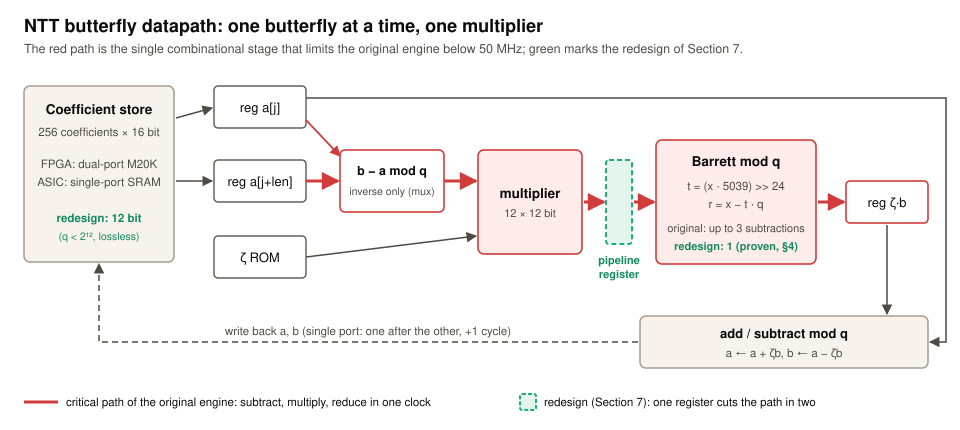

In [8]:
display(SVG(filename=str(ROOT/"figures/ntt_datapath.svg")))

In [9]:
model = {
    "ntt_dp": {"fwd": 896*5 + 2, "inv": 896*5 + 256*5 + 2},
    "ntt_sp": {"fwd": 896*7 + 2, "inv": 896*7 + 256*5 + 2},
    "keccak_r1": {"perm": 24*1 + 1},
    "keccak_s7": {"perm": 24*7 + 1},
}
model

{'ntt_dp': {'fwd': 4482, 'inv': 5762},
 'ntt_sp': {'fwd': 6274, 'inv': 7554},
 'keccak_r1': {'perm': 25},
 'keccak_s7': {'perm': 169}}

### Watching the controller work

`scripts/fsm_trace.sh` samples the controller's state at every clock edge of one forward transform: the
896 butterflies follow FIPS 203, Algorithm 9, the transform lasts exactly as long as the model predicts,
and the first butterflies in the figure show where the single-port variant spends its two extra cycles.

both controllers visit all 896 butterflies in FIPS 203 order; cycles per forward transform: {'ntt_dp': 4482, 'ntt_sp': 6274}


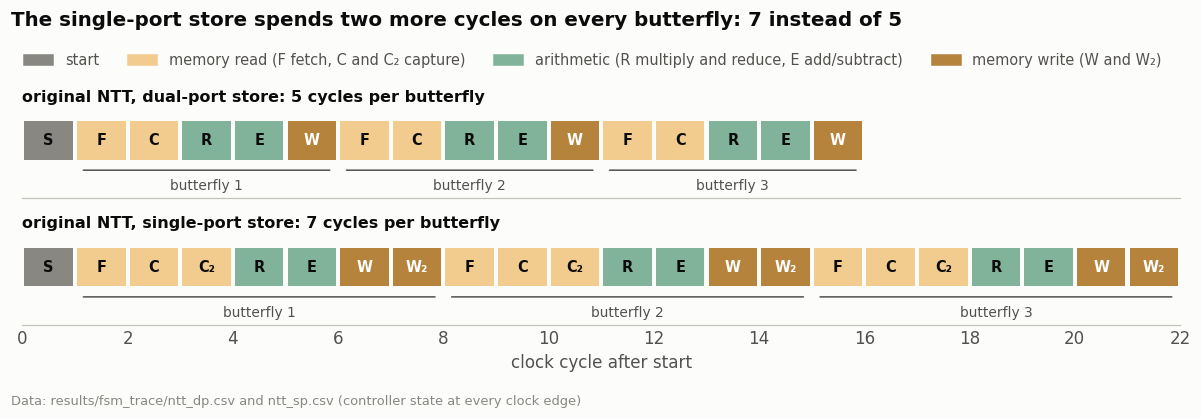

In [10]:
if IN_COLAB or not (ROOT/"results/fsm_trace/ntt_sp.csv").exists():
    sh("bash scripts/fsm_trace.sh 7000")
tr = {v: pd.read_csv(ROOT/"results/fsm_trace"/f"{v}.csv") for v in ["ntt_dp", "ntt_sp"]}
fips_order = [(L, j) for L in (128, 64, 32, 16, 8, 4, 2) for s in range(0, 256, 2 * L) for j in range(s, s + L)]
for v, d in tr.items():
    f = d[d.state == "FETCH"]
    assert list(zip(f.len, f.j)) == fips_order, f"{v}: butterfly order differs from FIPS 203"
    assert len(d) == model[v]["fwd"], f"{v}: trace length differs from the cycle model"
print("both controllers visit all 896 butterflies in FIPS 203 order; cycles per forward transform:",
      {v: len(d) for v, d in tr.items()})

KIND = {"IDLE": ("start", ps.OTHER), "FETCH": ("memory read", ps.MEM), "CAPTURE": ("memory read", ps.MEM),
        "CAPTURE_B": ("memory read", ps.MEM), "REDUCE": ("arithmetic", ps.LOGIC),
        "EXEC": ("arithmetic", ps.LOGIC), "WRITE": ("memory write", ps.MEM_W), "WRITE_B": ("memory write", ps.MEM_W)}
SHORT = {"IDLE": "S", "FETCH": "F", "CAPTURE": "C", "CAPTURE_B": "C₂", "REDUCE": "R", "EXEC": "E", "WRITE": "W", "WRITE_B": "W₂"}
fig, axes = plt.subplots(2, 1, figsize=(11, 2.9), sharex=True)
for ax, v in zip(axes, ["ntt_dp", "ntt_sp"]):
    per = 5 if v == "ntt_dp" else 7
    d = tr[v].iloc[: 1 + 3 * per]
    for c, s in zip(d.cycle, d.state):
        ax.barh(0, 0.92, left=c + 0.04, height=0.8, color=KIND[s][1])
        ax.text(c + 0.5, 0, SHORT[s], ha="center", va="center", fontsize=9.5, fontweight="bold",
                color=ps.INK if KIND[s][1] in (ps.MEM, ps.LOGIC, ps.OTHER) else "white")
    for b in range(3):
        ax.annotate("", (1 + b * per + 0.1, -0.62), (1 + (b + 1) * per - 0.1, -0.62),
                    arrowprops=dict(arrowstyle="-", color=ps.INK_2, lw=1))
        ax.text(1 + b * per + per / 2, -0.95, f"butterfly {b + 1}", ha="center", va="center", fontsize=9, color=ps.INK_2)
    ax.set_ylim(-1.2, 0.5); ax.set_yticks([]); ax.grid(False)
    ax.set_title(f"{LABEL[v]}: {per} cycles per butterfly", fontsize=10.5)
    ax.spines["left"].set_visible(False)
axes[-1].set_xlabel("clock cycle after start"); axes[-1].set_xlim(0, 1 + 3 * 7)
axes[-1].set_xticks(range(0, 23, 2))
from matplotlib.patches import Patch
fig.legend([Patch(color=c) for c in (ps.OTHER, ps.MEM, ps.LOGIC, ps.MEM_W)],
           ["start", "memory read (F fetch, C and C₂ capture)", "arithmetic (R multiply and reduce, E add/subtract)",
            "memory write (W and W₂)"], ncols=4, loc="lower left", bbox_to_anchor=(0.01, 0.97), frameon=False, fontsize=9.5)
fig.tight_layout()
fig.suptitle("The single-port store spends two more cycles on every butterfly: 7 instead of 5",
             x=0.01, ha="left", y=1.19, fontsize=13, fontweight="bold")
ps.source(fig, "results/fsm_trace/ntt_dp.csv and ntt_sp.csv (controller state at every clock edge)")
plt.show()

## 4. RTL against the golden model and the NIST vectors

Four testbenches (`scripts/run_sim.sh`) drive the RTL with golden-model vectors, corner cases first and then
random inputs; each compares every output exactly and flags any vector whose latency differs, which doubles as a
constant-time check: the latency must not depend on the data.

In [11]:
N = 60   # random vectors per block (the committed logs used 200)
# writes to results/sim_notebook so the committed 200-vector logs in results/sim stay untouched
out = sh(f"CAC_SIM_OUT=results/sim_notebook CAC_VEC_OUT=vectors_notebook bash scripts/run_sim.sh --ntt {N} --keccak {N} | grep -E 'RESULT|PASS|FAIL'", quiet=True)   # the table below summarizes the logs

In [12]:
import re
SIM_DIR = "results/sim_notebook"   # this run; results/sim holds the committed 200-vector run
def parse_sim():
    rows = {}
    for name, key in [("ntt_dualport","ntt_dp"),("ntt_singleport","ntt_sp"),("keccak_round","keccak_r1"),("keccak_serial","keccak_s7")]:
        log = (ROOT/SIM_DIR/f"{name}.log").read_text()
        d = {k: int(v) for k, v in re.findall(r"(\w+)=(\d+)", log.split("RESULT",1)[1].splitlines()[0])}
        d["pass"] = "PASS" in log
        rows[key] = d
    return pd.DataFrame(rows).T
sim = parse_sim()
sim["model_fwd_or_perm"] = [model[k].get("fwd", model[k].get("perm")) for k in sim.index]
sim["model_inv"] = [model[k].get("inv", np.nan) for k in sim.index]
sim["cycles_measured"] = [int(r.cycles_fwd) if pd.notna(r.get("cycles_fwd")) else int(r.cycles) for _, r in sim.iterrows()]
assert (sim["cycles_measured"] == sim["model_fwd_or_perm"]).all(), "analytical model disagrees with RTL"
assert (sim.loc[["ntt_dp","ntt_sp"], "cycles_inv"] == sim.loc[["ntt_dp","ntt_sp"], "model_inv"]).all()
assert (sim["timing_variations"] == 0).all() and sim["pass"].all()
print(f"committed logs (200 vectors per block): {n_err} mismatches over {n_coef:,} NTT coefficients and {n_kec} Keccak permutations")
sim

committed logs (200 vectors per block): 0 mismatches over 208,896 NTT coefficients and 404 Keccak permutations


,vectors,coefficients checked,errors,"cycles, forward NTT","cycles, inverse NTT",latency variations,pass,row-serialized,cycles,model: forward NTT / permutation,model: inverse NTT,cycles measured
"original NTT, dual-port store",64,32768,0,4482,5762,0,True,,,4482,5762,4482
"original NTT, single-port store",64,32768,0,6274,7554,0,True,,,6274,7554,6274
"Keccak, one round per clock",62,,0,,,0,True,0,25,25,,25
"Keccak, row-serialized",62,,0,,,0,True,1,169,169,,169


### What simulation can miss: a mutation test and a proof

Simulation covers only the vectors it is given, as a mutation test shows (Appendix A.5). Of ten deliberate
bugs planted one at a time in HSKEM-2's NTT engine, its modular reducer and the Keccak cores,
the unchanged testbenches catch eight, and one is argued to be equivalent. The remaining
one skips the final subtraction of $q$ when the remainder equals $q$ exactly. It changes the reducer's output
only for the 5,039 nonzero multiples of $q$ among its $2^{24}$ inputs, which no test vector exercises, so it
passes every test. The reducer's 24-bit input,
however, allows a proof for all $2^{24}$ inputs with the SAT solver of Yosys (`formal/prove_barrett.sh`), which either proves a logic property for every input
or returns a counterexample. Run on the mutant, the proof finds one. It also settles a design question: the RTL applies
up to three conditional subtractions of $q$, yet the reducer is proven correct with three, two and one, while
a negative control with none fails (table and figure below).

reducer variant,SAT result (Yosys)
"RTL reducer, three conditional subtractions",proven for all 2²⁴ inputs
two subtractions,proven for all 2²⁴ inputs
one subtraction,proven for all 2²⁴ inputs
negative control: no subtraction,"counterexample found, as it must be"


exhaustive check: pre-correction remainder in [0, 5713] < 2q; 6,012,719 inputs need exactly one subtraction, none need two
mutation test: 8 of 10 caught by the testbenches, 1 by the proof, 1 equivalent; control passes


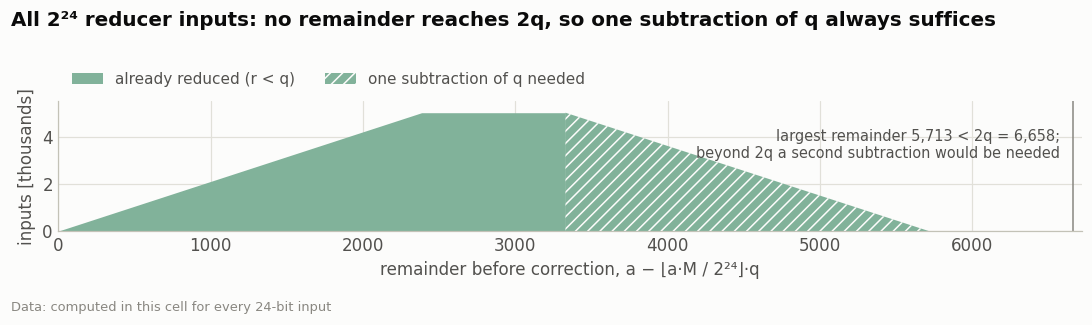

In [13]:
RUN_FORMAL = False   # True re-runs the four SAT proofs (about 15 minutes on one core)
if RUN_FORMAL:
    for impl, tag in [("../rtl/barrett_reduce.v", "barrett_proof"),
                      ("barrett_reduce_no_r3.v", "barrett_no_third_correction"),
                      ("barrett_reduce_one_correction.v", "barrett_one_correction"),
                      ("barrett_reduce_mutant_none.v", "barrett_negative_control_no_correction")]:
        sh(f"bash formal/prove_barrett.sh {impl} {tag}")
PROOF = {"barrett_proof": "RTL reducer, three conditional subtractions",
         "barrett_no_third_correction": "two subtractions",
         "barrett_one_correction": "one subtraction",
         "barrett_negative_control_no_correction": "negative control: no subtraction"}
proof_ = {}
for tag, name in PROOF.items():
    log = (ROOT/"results/formal"/f"{tag}.log").read_text()
    verdict = re.search(r"SAT proof finished - (.*)", log)[1]
    proof_[name] = ("proven for all 2²⁴ inputs" if "no model found" in verdict
                    else "counterexample found, as it must be" if "model found" in verdict else verdict)
assert list(proof_.values()).count("proven for all 2²⁴ inputs") == 3 and "counterexample" in proof_[PROOF["barrett_negative_control_no_correction"]]
nbd.show(pd.DataFrame({"SAT result (Yosys)": proof_}).rename_axis("reducer variant"), index=True)

# independent exhaustive cross-check of the same arithmetic
a = np.arange(1 << 24, dtype=np.int64)
r0 = a - ((a * 5039) >> 24) * 3329
assert r0.min() >= 0 and r0.max() < 2 * 3329
r1 = np.where(r0 >= 3329, r0 - 3329, r0)
assert (r1 == a % 3329).all() and not (r0 == a % 3329).all()
print(f"exhaustive check: pre-correction remainder in [{r0.min()}, {r0.max()}] < 2q; "
      f"{int((r0 >= 3329).sum()):,} inputs need exactly one subtraction, none need two")
# the mutation test of Appendix A.5: the boundary mutant of the reducer is reached only by multiples of q
mu_ = json.loads((ROOT/"results/mutation/summary.json").read_text())
bb_ = next(m for m in mu_["mutants"] if m["mutant"] == "barrett_bound")
assert (mu_["total"], mu_["caught_by_simulation"], mu_["caught"] - mu_["caught_by_simulation"], mu_["equivalent"]) == (10, 8, 1, 1)
assert mu_["control_passes"] and not bb_["caught_by_simulation"] and bb_["formal"]["caught"]
assert int((r0 == 3329).sum()) == 5039 == int(((a > 0) & (a % 3329 == 0)).sum())   # "the 5,039 nonzero multiples of q"
print(f"mutation test: {mu_['caught_by_simulation']} of {mu_['total']} caught by the testbenches, "
      f"{mu_['caught'] - mu_['caught_by_simulation']} by the proof, {mu_['equivalent']} equivalent; control passes")

# where the 2^24 pre-correction remainders fall
hist = np.bincount(r0, minlength=2 * 3329)
fig, ax = plt.subplots(figsize=(10, 2.6))
ax.fill_between(np.arange(3329), hist[:3329] / 1e3, step="mid", color=ps.LOGIC, lw=0, label="already reduced (r < q)")
ax.fill_between(np.arange(3329, 2 * 3329), hist[3329:2 * 3329] / 1e3, step="mid", color=ps.LOGIC, hatch="///", edgecolor=ps.SURFACE, lw=0,
                label="one subtraction of q needed")
ps.reference_line(ax, 2 * 3329, axis="x")
ax.annotate(f"largest remainder {r0.max():,} < 2q = {2 * 3329:,};\nbeyond 2q a second subtraction would be needed",
            (2 * 3329, hist.max() / 1e3 * 0.62), xytext=(-8, 0),
            textcoords="offset points", ha="right", fontsize=9.5, color=ps.INK_2)
ax.set_xlim(0, 2 * 3329 + 60); ax.set_ylim(0, hist.max() / 1e3 * 1.1)
ax.set_xlabel("remainder before correction, a − ⌊a·M / 2²⁴⌋·q"); ax.set_ylabel("inputs [thousands]")
ax.legend(ncols=2, loc="lower left", bbox_to_anchor=(0, 1.0))
fig.suptitle("All 2²⁴ reducer inputs: no remainder reaches 2q, so one subtraction of q always suffices",
             x=0.01, ha="left", y=1.0, fontsize=13, fontweight="bold")
ps.finish(fig); ps.source(fig, "computed in this cell for every 24-bit input"); plt.show()

### The complete co-processor against the NIST vectors

Because its SPI interface accepts a deterministic key-generation seed for testing, the complete RTL also
faces the NIST vectors. `scripts/acvp_rtl_keygen.py` runs all 25 key-generation cases in the FPGA and ASIC
configurations and compares the key memories byte for byte. The decapsulation key is compared in full
except for its embedded hash H(ek), whose input ek is compared instead. A negative control that hashes the
seed with $k = 3$ in $G(d\,\|\,k)$, as ML-KEM-768 would, must fail. Encapsulation and decapsulation cannot
be given an external key, so `scripts/acvp_rtl_encdec.py` drives HSKEM-2's RTL with the ACVP key-generation seed and encapsulation message of each case and compares
the ciphertext, both shared keys and the implicit-rejection key for a corrupted decoded coefficient with
the golden model.

In [14]:
RUN_ACVP_RTL = IN_COLAB   # about one minute per key-generation configuration (encapsulation: scripts/acvp_rtl_encdec.sh, ten minutes)
if RUN_ACVP_RTL:
    for cfg in ("fpga", "asic"):
        print(sh(f"python3 scripts/acvp_rtl_keygen.py {cfg}").strip().splitlines()[-1])
for cfg in ("fpga", "asic", "fpga_streamed", "asic_streamed"):     # the last two: the streamed system of Section 8
    r = json.loads((ROOT/f"results/acvp_rtl/keygen_{cfg}.json").read_text())
    diff = sum(c[k] for c in r["details"] for k in c if k.endswith("bytes_diff"))
    print(f"{cfg}: {r['passed']} of {r['cases']} ACVP keyGen cases byte-exact (ekPKE, dkPKE, z; {diff} differing bytes); "
          f"negative control k = 3: {r['negative_control']['ekpke_t_bytes_diff_vs_case_0']} of 768 bytes of t differ")
    assert r["passed"] == r["cases"] == 25 and diff == 0 and r["negative_control"]["ekpke_t_bytes_diff_vs_case_0"] > 0
ed = json.loads((ROOT/"results/acvp_rtl/encdec_rev_c.json").read_text())
print(f"HSKEM-2's RTL: {ed['passed']} of {len(ed['details'])} encapsulation-decapsulation runs on ACVP seeds and messages "
      f"equal to the golden model (ciphertext, both shared keys, implicit rejection)")
assert ed["passed"] == len(ed["details"]) == 25 and all(d["c"] and d["K_enc"] and d["K_dec"] and d["K_rej"] for d in ed["details"])

fpga: 25 of 25 ACVP keyGen cases byte-exact (ekPKE, dkPKE, z; 0 differing bytes); negative control k = 3: 766 of 768 bytes of t differ
asic: 25 of 25 ACVP keyGen cases byte-exact (ekPKE, dkPKE, z; 0 differing bytes); negative control k = 3: 766 of 768 bytes of t differ
fpga_streamed: 25 of 25 ACVP keyGen cases byte-exact (ekPKE, dkPKE, z; 0 differing bytes); negative control k = 3: 766 of 768 bytes of t differ
asic_streamed: 25 of 25 ACVP keyGen cases byte-exact (ekPKE, dkPKE, z; 0 differing bytes); negative control k = 3: 766 of 768 bytes of t differ
HSKEM-2's RTL: 25 of 25 encapsulation-decapsulation runs on ACVP seeds and messages equal to the golden model (ciphertext, both shared keys, implicit rejection)


# Part II — What does each decision cost?

HSKEM-1's two decisions are priced by synthesis, after place-and-route and across the whole system.
The figures of merit, at the typical corner (25 °C, 1.8 V) unless stated, are:

| Quantity | Definition |
|:---|:---|
| fmax | $1/(T - \mathrm{slack}_{reg\to reg})$ of the routed block at the typical corner (Appendix B.1 explains why register-to-register; B.5 adds the slow and fast corners of the flip-flop-store and Keccak blocks) |
| latency, area × time | cycles of one operation / fmax; standard-cell plus macro area × latency |
| energy per operation | $P \cdot N_\mathrm{cycles} \cdot T$ at the 20 ns clock, with $P$ from OpenSTA: gate-level activity of one operation on the extracted parasitics; an SRAM macro adds its access energies, simulated at 25 MHz and valid only there (Appendix C.4), so the energy of a macro-store block is an estimate |
| SRAM energy | $V_\mathrm{DD}\int i_\mathrm{DD}\,dt$ over each clock cycle of a transistor-level simulation of the macro |
| decapsulation | the first profiled decapsulation of the full-system testbench; its energy window starts at the second busy cycle; 25 MHz on the chip |

## 5. Synthesis: the second port costs a third more area, serializing Keccak saves none

Synthesis gives the first price: Yosys and its logic optimizer ABC [11] map each design point to `sky130_fd_sc_hd`
(`scripts/synth_sky130.sh`) and estimate its area and delay without wires or clock tree; the NTT store is built from flip-flops so that
both memory variants compete on equal terms, and both Keccak cores share one wrapper that moves the state in 64-bit lanes.

In [15]:
SWEEP_CLOCKS = "20"          # "10 20 40" reproduces the full sweep (~15 min)
if IN_COLAB or not list((ROOT/"results/synth").glob("*/summary.json")):
    sh(f"bash scripts/synth_sweep.sh 'ntt_dp ntt_sp keccak_r1 keccak_s7' '{SWEEP_CLOCKS}'")
syn = []
for p in sorted((ROOT/"results/synth").glob("*/summary.json")):
    v, t = re.match(r"(\w+?_\w+?)_(\d+)ns", p.parent.name).groups()
    syn.append({"variant": v, "clk_ns": int(t), **json.loads(p.read_text())})
syn = pd.DataFrame(syn).sort_values(["variant","clk_ns"]).reset_index(drop=True)
syn["cycles"] = syn.variant.map(sim["cycles_measured"])
nbd.show(syn[syn.variant.isin(["ntt_dp", "ntt_sp", "keccak_r1", "keccak_s7"])])     # Section 7 shows the iteration rows

design,clock target [ns],cell area [µm²],cells,ABC delay estimate [ns],cycles
"Keccak, one round per clock",10,201281.7952,23103,2.4111,25
"Keccak, one round per clock",20,201281.7952,23103,2.4111,25
"Keccak, one round per clock",40,201281.7952,23103,2.4111,25
"Keccak, row-serialized",10,203970.6240,23768,2.5073,169
"Keccak, row-serialized",20,203970.6240,23768,2.5073,169
"Keccak, row-serialized",40,203970.6240,23768,2.5073,169
"original NTT, dual-port store",10,238319.8176,27672,15.5569,4482
"original NTT, dual-port store",20,238039.5488,27672,18.3328,4482
"original NTT, dual-port store",40,238039.5488,27672,18.3328,4482
"original NTT, single-port store",10,181176.2624,13141,16.2116,6274


**Reading the synthesis table.** The dual-port NTT adds a second write port and read-multiplexer tree to
the same 4096 bits, which the figure shows as "other logic". The row-serialized Keccak computes χ/ι for one
row instead of five, but pays with a 320-bit θ-D register and a wider next-state selection, which leave it
about one percent larger.

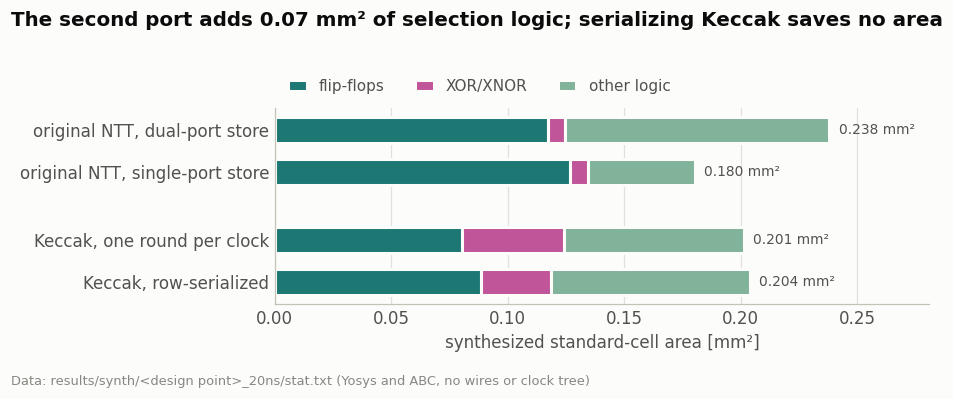

,flip-flops [mm²],XOR/XNOR [mm²],other logic [mm²]
"original NTT, dual-port store",0.1171,0.0074,0.1136
"original NTT, single-port store",0.1269,0.0078,0.0458
"Keccak, one round per clock",0.0803,0.0438,0.0773
"Keccak, row-serialized",0.0884,0.0301,0.0855


In [16]:
def cell_groups(variant, clk=20):
    st = (ROOT/"results/synth"/f"{variant}_{clk}ns"/"stat.txt").read_text()
    g = {"flip-flops": 0.0, "XOR/XNOR": 0.0, "other logic": 0.0}
    for n, area, cell in re.findall(r"^\s*(\d+)\s+([\d.E+-]+)\s+sky130_fd_sc_hd__(\w+)", st, re.M):
        k = "flip-flops" if cell.startswith(("df", "edf")) else "XOR/XNOR" if cell.startswith(("xor", "xnor")) else "other logic"
        g[k] += float(area)
    return g
grp = pd.DataFrame({v: cell_groups(v) for v in ["ntt_dp", "ntt_sp", "keccak_r1", "keccak_s7"]}).T / 1e6

fig, ax = plt.subplots(figsize=(8.6, 3.2))
rows = list(grp.index)[::-1]
ypos = {v: y for y, v in zip([0, 0.8, 2.1, 2.9], rows)}          # a gap separates the two families
left = np.zeros(len(rows))
for slot, part in enumerate(grp.columns):
    vals = grp.loc[rows, part].values
    ax.barh([ypos[v] for v in rows], vals, left=left, height=0.5, label=part, **ps.bar_kw(ps.CELL_CLASS[slot]))
    left += vals
for v, total in zip(rows, left):
    ax.annotate(f"{total:.3f} mm²", (total, ypos[v]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=ps.INK_2)
ax.set_yticks([ypos[v] for v in rows], [LABEL[v] for v in rows])
ax.set_xlabel("synthesized standard-cell area [mm²]")
ax.set_xlim(0, left.max() * 1.18); ax.grid(axis="y", visible=False)
ax.legend(ncols=3, loc="lower left", bbox_to_anchor=(0, 1.0), handlelength=1.2)
sel_ = grp.loc["ntt_dp", "other logic"] - grp.loc["ntt_sp", "other logic"]
assert 0.06 < sel_ < 0.075 and grp.loc["keccak_s7"].sum() > grp.loc["keccak_r1"].sum()
ps.finish(fig, title=f"The second port adds {sel_:.2f} mm² of selection logic; serializing Keccak saves no area")
ps.source(fig, "results/synth/<design point>_20ns/stat.txt (Yosys and ABC, no wires or clock tree)"); plt.show()
grp.rename(columns=lambda c: c + " [mm²]").round(4)

## 6. Place-and-route: the second port buys no area × time, the serialized Keccak loses its purpose

All design points went through OpenROAD-flow-scripts (ORFS) [8] for the SKY130 HD library [10] at a
common 20 ns target (Appendix B).

In [17]:
if RUN_PNR:
    sh("bash scripts/sweep.sh 'ntt_dp ntt_sp keccak_r1 keccak_s7' '20' 4")
sh("python3 scripts/collect_metrics.py > /dev/null")
pnr = pd.read_csv(ROOT/"results/dse_metrics.csv")
# the four architecture points at the common 20 ns target; Appendix B.1 lists every routed run
arch = ["ntt_dp", "ntt_sp", "keccak_r1", "keccak_s7"]
a20 = pnr[(pnr.clk_target_ns == 20) & pnr.variant.isin(arch)].set_index("variant").loc[arch]
pd.DataFrame({
    "cell area [mm²]": a20.cell_area_um2 / 1e6,
    "flip-flops": a20.flops.astype(int),
    "reg→reg fmax [MHz]": a20.fmax_mhz,
    "cycles per operation": a20.cycles.astype(int),
    "latency [µs]": a20.latency_us_at_fmax,
    "area × time [mm²·µs]": a20.at_product,
    "DRC / antenna": a20.drc_errors.astype(int).astype(str) + " / " + a20.antenna_violating_nets.astype(int).astype(str),
}).rename(index=LABEL).round(3)

design,cell area [mm²],flip-flops,reg→reg fmax [MHz],cycles per operation,latency [µs],area × time [mm²·µs],DRC / antenna
"original NTT, dual-port store",0.288,4277,47.483,4482,94.391,27.157,0 / 0
"original NTT, single-port store",0.216,4267,49.751,6274,126.107,27.225,0 / 0
"Keccak, one round per clock",0.234,3207,181.159,25,0.138,0.032,0 / 0
"Keccak, row-serialized",0.231,3534,130.208,169,1.298,0.300,0 / 0


The dual-port NTT is about a third larger and a little slower. In the figure below both NTT stores lie on one
dashed curve of equal area × time: the second port buys a shorter
transform and nothing more. After routing, row-serializing Keccak saves about one percent of area but needs seven times as many cycles at a clock about 30 % lower, so each permutation
takes nine times longer. Both NTT blocks stay below 50 MHz at any target, because their
subtract–multiply–reduce path is one combinational stage (table in Appendix B.3).

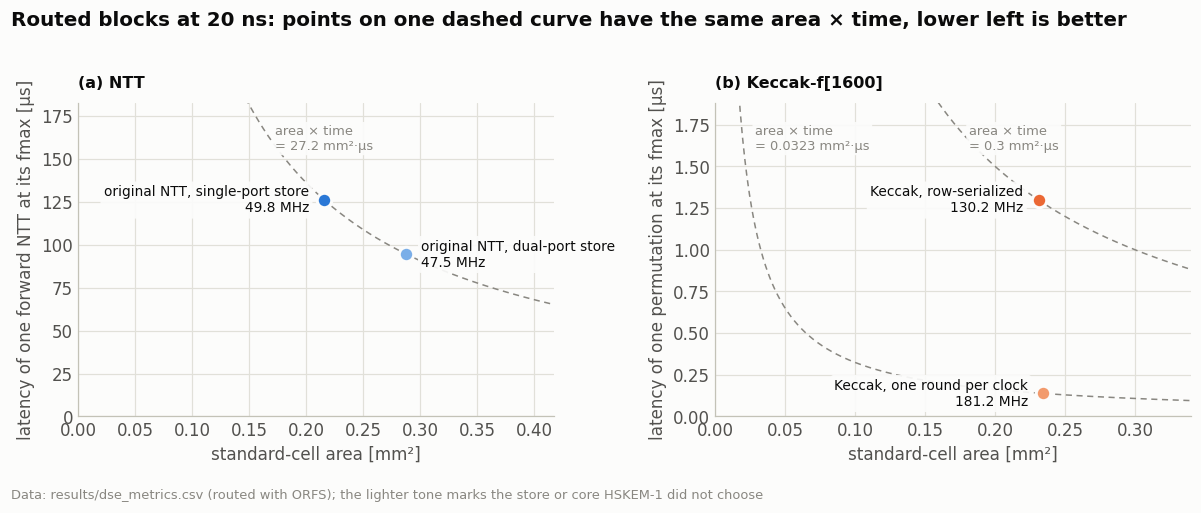

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
P20 = pnr[pnr.clk_target_ns == 20].set_index("variant")
SIDE = {"ntt_dp": 1, "ntt_sp": -1}         # label side of each point (1: right, -1: left)
for ax, tag, pts, curves, op in [
        (axes[0], "(a) NTT", ["ntt_dp", "ntt_sp"], ["ntt_sp"], "one forward NTT"),
        (axes[1], "(b) Keccak-f[1600]", ["keccak_r1", "keccak_s7"], ["keccak_r1", "keccak_s7"], "one permutation")]:
    a, t = P20.cell_area_um2[pts] / 1e6, P20.latency_us_at_fmax[pts]
    xmax, ymax = a.max() * 1.45, t.max() * 1.45
    xs = np.linspace(xmax * 0.03, xmax, 400)
    for v in curves:                       # every point on one dashed curve has the same area x time
        at = a[v] * t[v]
        ax.plot(xs, at / xs, color=ps.MUTED, lw=1, ls=(0, (4, 3)), zorder=1)
        ax.annotate(f"area × time\n= {at:.3g} mm²·µs", (at / (0.93 * ymax), 0.93 * ymax), xytext=(9, 0),
                    textcoords="offset points", ha="left", va="top", fontsize=8.5, color=ps.MUTED, zorder=2,
                    bbox=dict(boxstyle="round,pad=0.2", fc=ps.SURFACE, ec="none", alpha=0.92))
    for v in pts:
        ax.scatter(a[v], t[v], **{**ps.marker_kw(COLOR[v]), "zorder": 4})
        r = SIDE.get(v, -1)
        ax.annotate(f"{LABEL[v]}\n{P20.fmax_mhz[v]:.1f} MHz", (a[v], t[v]), xytext=(10 * r, 0), textcoords="offset points",
                    ha="left" if r > 0 else "right", va="center", fontsize=9, color=ps.INK, zorder=5,
                    bbox=dict(boxstyle="round,pad=0.25", fc=ps.SURFACE, ec="none", alpha=0.92))
    ax.set_xlim(0, xmax); ax.set_ylim(0, ymax)
    ax.set_xlabel("standard-cell area [mm²]"); ax.set_ylabel(f"latency of {op} at its fmax [µs]")
    ax.set_title(tag, loc="left", fontsize=10.5)
ps.finish(fig, title="Routed blocks at 20 ns: points on one dashed curve have the same area × time, lower left is better")
ps.source(fig, "results/dse_metrics.csv (routed with ORFS); the lighter tone marks the store or core HSKEM-1 did not choose")
ps.save_pdf(fig, "area_latency"); plt.show()

### HSKEM-1's store: an OpenRAM macro

On HSKEM-1 the store is the single-port OpenRAM macro `sky130_sram_1rw_16x256_wpr8`, so the single-port
engine was also routed with it, at an unchanged cycle count. OpenRAM's power view of the macro is not
physical, so its energy is priced with transistor-level access energies (Appendix C.4).

In [19]:
mc = pnr[(pnr.clk_target_ns == 20) & pnr.variant.isin(["ntt_sp", "ntt_macro"])].set_index("variant").loc[["ntt_sp", "ntt_macro"]]
areas = {v: total_area(f"{v}_20ns") for v in mc.index}
store = pd.DataFrame({
    "standard cells [mm²]": [areas[v][0] / 1e6 for v in mc.index],
    "SRAM macro [mm²]": [areas[v][1] / 1e6 for v in mc.index],
    "total [mm²]": [sum(areas[v]) / 1e6 for v in mc.index],
    "die [mm²]": (mc.die_area_um2 / 1e6).values,
    "flip-flops": mc.flops.astype(int).values,
    "fmax [MHz]": mc.fmax_mhz.values,
    "area × time [mm²·µs]": [sum(areas[v]) / 1e6 * mc.loc[v, "latency_us_at_fmax"] for v in mc.index],
    "DRC / antenna": (mc.drc_errors.astype(int).astype(str) + " / " + mc.antenna_violating_nets.astype(int).astype(str)).values,
    "max-slew violations": [slew_violations(f"{v}_20ns") for v in mc.index],
}, index=["flip-flop store", "OpenRAM macro store"])
gpm = {v: json.loads((ROOT/"results/gls_power"/f"{v}_20ns"/"summary.json").read_text()) for v in mc.index}
store["energy / forward NTT [µJ]"] = [gpm[v]["energy_per_forward_ntt_nj"] / 1e3 for v in mc.index]
store["of which the SRAM macro [µJ]"] = [gpm[v].get("macro_energy_nj", float("nan")) / 1e3 for v in mc.index]
display(store.round(3).fillna("–"))
blk_ntt = pd.read_csv(ROOT/"results/fullchip/first_chip/blocks.csv").set_index("block").loc["u_shared_ntt", "flops"]
print(f"flip-flops of the macro-store block: {int(mc.loc['ntt_macro', 'flops'])}; of the NTT engine on HSKEM-1: {int(blk_ntt)}")
# guards for the statements made in the text below
assert (mc.drc_errors == 0).all() and (mc.antenna_violating_nets == 0).all()
assert 0.6 < store["total [mm²]"].iloc[1] / store["total [mm²]"].iloc[0] < 0.7     # "about a third less"
assert store["standard cells [mm²]"].iloc[1] < 0.2 * store["standard cells [mm²]"].iloc[0]
# the macro is smaller than the flip-flops and multiplexers it replaces
assert store["SRAM macro [mm²]"].iloc[1] < store["standard cells [mm²]"].iloc[0] - store["standard cells [mm²]"].iloc[1]
assert abs(mc.fmax_mhz.iloc[1] / mc.fmax_mhz.iloc[0] - 1) < 0.05                 # guards the fmax column
assert abs(int(mc.loc["ntt_macro", "flops"]) - int(blk_ntt)) <= 2
assert store["max-slew violations"].iloc[0] == 0 < store["max-slew violations"].iloc[1]
assert all(gpm[v]["gls_pass"] for v in mc.index) and gpm["ntt_macro"]["cycles_fwd"] == gpm["ntt_sp"]["cycles_fwd"]
e_ratio_m = store["energy / forward NTT [µJ]"].iloc[1] / store["energy / forward NTT [µJ]"].iloc[0]
assert 0.15 < e_ratio_m < 0.25                                                   # "about a fifth"
assert 0.6 < gpm["ntt_macro"]["macro_energy_nj"] / gpm["ntt_macro"]["energy_per_forward_ntt_nj"] < 0.8  # "most of it"

,standard cells [mm²],SRAM macro [mm²],total [mm²],die [mm²],flip-flops,fmax [MHz],area × time [mm²·µs],DRC / antenna,max-slew violations,energy / forward NTT [µJ],of which the SRAM macro [µJ]
flip-flop store,0.216,0.000,0.216,0.416,4267,49.751,27.225,0 / 0,0,2.479,–
OpenRAM macro store,0.039,0.103,0.141,0.293,155,48.077,18.465,0 / 0,2,0.504,0.372


flip-flops of the macro-store block: 155; of the NTT engine on HSKEM-1: 154


With the macro, the standard cells shrink to under a fifth, and even counting the macro the block needs
about a third less area. A forward transform costs about a fifth of the energy, most of it in the macro,
because 4096 flip-flops no longer receive the clock in every cycle. HSKEM-1 thus traded two extra cycles
per butterfly for a much smaller, more frugal store, and this block is where Section 7 starts.

### Energy per Keccak permutation

Both routed Keccak netlists are simulated against the golden model, and OpenSTA prices the activity of
one permutation with the extracted parasitics (`scripts/run_gls_power_keccak.sh`).

In [20]:
ke = {v: json.loads((ROOT/"results/gls_power"/f"{v}_20ns"/"summary.json").read_text()) for v in ["keccak_r1", "keccak_s7"]}
ke = pd.DataFrame(ke).T
assert ke.gls_pass.all(), "a routed Keccak netlist failed gate-level simulation"
assert (ke.cycles_perm.astype(int) == [model["keccak_r1"]["perm"], model["keccak_s7"]["perm"]]).all()
kgrp = {}
for v in ke.index:
    kgrp[v] = {g: float(s) / 100 for g, s in re.findall(r"^(Sequential|Combinational|Clock)\s.*?([\d.]+)%\s*$",
               (ROOT/"results/gls_power"/f"{v}_20ns"/"power.log").read_text(), re.M)}
tab = pd.DataFrame({
    "cycles / permutation": ke.cycles_perm.astype(int),
    "power [mW]": ke.total_power_w.astype(float) * 1e3,
    "energy / permutation [nJ]": ke.energy_per_permutation_nj.astype(float),
    "clock tree + flip-flops [% of power]": [100 * (kgrp[v]["Clock"] + kgrp[v]["Sequential"]) for v in ke.index],
    "energy spread, 5 inputs [%]": [energy_spread(f"{v}_20ns") for v in ke.index],
}).rename(index=LABEL)
assert (tab["energy spread, 5 inputs [%]"] < 0.5).all(), "the energy now depends noticeably on the input (table column)"
e_ratio = ke.loc["keccak_s7", "energy_per_permutation_nj"] / ke.loc["keccak_r1", "energy_per_permutation_nj"]
p_ratio = ke.loc["keccak_s7", "total_power_w"] / ke.loc["keccak_r1", "total_power_w"]
print(f"row-serialized / one round per clock: power x{p_ratio:.2f}, energy per permutation x{e_ratio:.1f}")
assert 5 < e_ratio < 6 and 0.75 < p_ratio < 0.9     # stated in the text below
assert kgrp["keccak_s7"]["Clock"] + kgrp["keccak_s7"]["Sequential"] > 0.65
tab.round(2)

row-serialized / one round per clock: power x0.82, energy per permutation x5.5


,cycles / permutation,power [mW],energy / permutation [nJ],clock tree + flip-flops [% of power],"energy spread, 5 inputs [%]"
"Keccak, one round per clock",25,29.10,14.55,58.5,0.41
"Keccak, row-serialized",169,23.78,80.39,69.2,0.24


Both routed blocks compute the permutation bit-exactly. Row-serialization lowers the power per cycle by
less than a fifth but needs almost seven times as many cycles, so a permutation costs about 5.5 times more
energy: the clock tree and the 1600-bit state draw two thirds of the power whether a round is computed or
not. Serializing the round thus saves almost no area and costs both time and energy.

## 7. Closing the loop: three measured iterations of the NTT

Each iteration answers a measurement: the first shortens the critical path that place-and-route exposed, the
second packs two coefficients into each memory word to remove the macro accesses that dominate a transform's
energy, and the third, the engine of HSKEM-2, gives each half of that word its own butterfly unit.

The first iteration rests on three observations: the proof of Section 4 makes two of the reducer's three
subtractions redundant, the critical path runs through the multiplier and the reducer, and the FPGA
synthesis already drops four always-zero coefficient bits (Appendix D.1). `rtl/kyber_ntt_engine_opt.sv`
implements all three behind parameters and, with all three disabled, is cycle-identical to the original:

| Parameter | Effect |
|:---|:---|
| `BARRETT_1C` | single-subtraction Barrett reducer (`rtl/barrett_reduce_1c.v`), proven equivalent |
| `PIPE_MUL` | a register between the multiplier and the reducer; one extra cycle per butterfly |
| `COEFF_W = 12` | a 12-bit coefficient store, lossless because $q < 2^{12}$ |

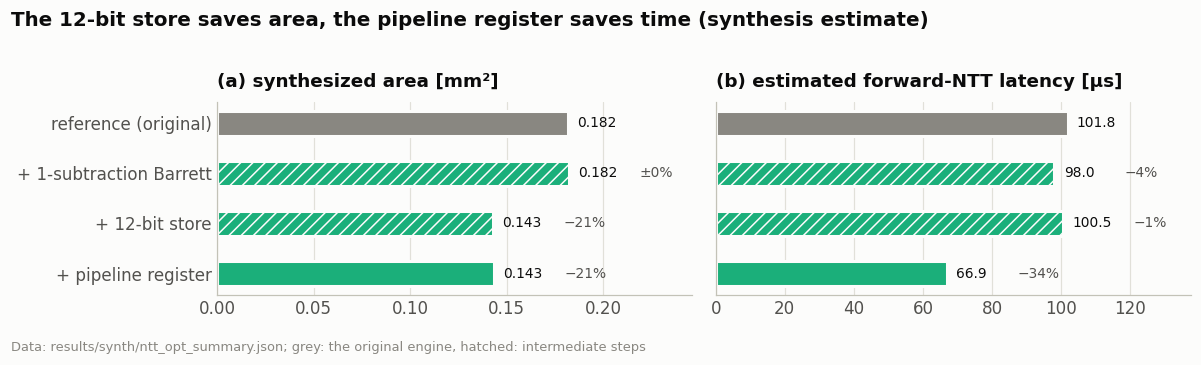

,simulation errors,latency variations,"cycles, forward NTT","cycles, inverse NTT",cell area [µm²],ABC delay estimate [ns],estimated forward latency [µs],area vs reference,delay vs reference,latency vs reference
"iteration 1: reference (original, single-port)",0,0,6274,7554,181904.4608,16.2298,101.83,+0.0%,+0.0%,+0.0%
iteration 1: 1-subtraction Barrett,0,0,6274,7554,182372.4096,15.6251,98.03,+0.3%,-3.7%,-3.7%
iteration 1: 12-bit store,0,0,6274,7554,142878.2816,16.0129,100.47,-21.5%,-1.3%,-1.3%
iteration 1: 12-bit store + pipeline,0,0,7170,8706,143372.5056,9.3280,66.88,-21.2%,-42.5%,-34.3%


In [21]:
if IN_COLAB:
    sh("bash scripts/run_sim_opt.sh")
    sh("bash scripts/synth_sweep.sh 'ntt_opt_ref ntt_opt_b1 ntt_opt_b1_w12 ntt_opt_pipe_w12' '10'")
opt = json.loads((ROOT/"results/synth/ntt_opt_summary.json").read_text())["variants"]
opt = pd.DataFrame(opt).T[["sim_errors", "timing_variations", "cycles_fwd", "cycles_inv",
                           "cell_area_um2", "abc_comb_delay_ns", "est_fwd_latency_us"]]
assert (opt.sim_errors == 0).all() and (opt.timing_variations == 0).all()
assert opt.loc["ntt_opt_ref", "cycles_fwd"] == sim.loc["ntt_sp", "cycles_measured"]
ref0 = opt.loc["ntt_opt_ref"]          # the reference variant (not the golden-model module ref)
opt["area_vs_ref"] = (opt.cell_area_um2 / ref0.cell_area_um2 - 1).map("{:+.1%}".format)
opt["delay_vs_ref"] = (opt.abc_comb_delay_ns / ref0.abc_comb_delay_ns - 1).map("{:+.1%}".format)
opt["latency_vs_ref"] = (opt.est_fwd_latency_us / ref0.est_fwd_latency_us - 1).map("{:+.1%}".format)

names = {"ntt_opt_ref": "reference (original)", "ntt_opt_b1": "+ 1-subtraction Barrett",
         "ntt_opt_b1_w12": "+ 12-bit store", "ntt_opt_pipe_w12": "+ pipeline register"}
order = list(names)[::-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 2.9), sharey=True)
for ax, col, unit, title in [(axes[0], "cell_area_um2", 1e6, "(a) synthesized area [mm²]"),
                             (axes[1], "est_fwd_latency_us", 1, "(b) estimated forward-NTT latency [µs]")]:
    vals = opt.loc[order, col].astype(float) / unit
    for y, v in enumerate(order):        # grey: the original; hatched: steps towards iteration 1
        ax.barh(y, vals.iloc[y], height=0.5, color=ps.MUTED if v == "ntt_opt_ref" else ps.IT1,
                hatch=None if v in ("ntt_opt_ref", "ntt_opt_pipe_w12") else "///", edgecolor=ps.SURFACE, linewidth=2)
    for y, (v, x) in enumerate(zip(order, vals)):
        rel = x / (float(opt.loc["ntt_opt_ref", col]) / unit) - 1
        ax.annotate(f"{x:.3f}" if unit != 1 else f"{x:.1f}", (x, y), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=9, color=ps.INK)
        if v != "ntt_opt_ref":
            txt = "±0%" if abs(rel) < 0.005 else f"{rel:+.0%}".replace("-", "−")
            ax.annotate(txt, (x, y), xytext=(46, 0), textcoords="offset points",
                        va="center", fontsize=9, color=ps.INK_2)
    ax.set_title(title); ax.grid(axis="y", visible=False); ax.set_xlim(0, vals.max() * 1.35)
axes[0].set_yticks(range(len(order)), [names[v] for v in order])
ps.finish(fig, title="The 12-bit store saves area, the pipeline register saves time (synthesis estimate)")
ps.source(fig, "results/synth/ntt_opt_summary.json; grey: the original engine, hatched: intermediate steps"); plt.show()
opt

Synthesis sorts the three ideas: the single subtraction barely changes the delay, because the long path
runs through the reducer's two multiplications, while the 12-bit store removes about a fifth of the area
and the pipeline register nearly halves the delay (−34 % in latency), so only the 12-bit variants were routed.

In [22]:
it = pnr[(pnr.clk_target_ns == 20) & pnr.variant.isin(["ntt_sp", "ntt_opt_b1_w12", "ntt_opt_pipe_w12"])]
it = it.set_index("variant").loc[["ntt_sp", "ntt_opt_b1_w12", "ntt_opt_pipe_w12"]]
base_it = it.loc["ntt_sp"]
tab = pd.DataFrame({
    "cell area [mm²]": it.cell_area_um2 / 1e6,
    "flip-flops": it.flops.astype(int),
    "fmax [MHz]": it.fmax_mhz,
    "cycles / forward NTT": it.cycles.astype(int),
    "latency [µs]": it.latency_us_at_fmax,
    "area × time [mm²·µs]": it.at_product,
    "DRC / antenna": it.drc_errors.astype(int).astype(str) + " / " + it.antenna_violating_nets.astype(int).astype(str),
}).rename(index={"ntt_sp": "original (single-port)", "ntt_opt_b1_w12": "+ 1-subtraction Barrett, 12-bit store",
                 "ntt_opt_pipe_w12": "+ pipeline register"})
assert (it.drc_errors == 0).all() and (it.antenna_violating_nets == 0).all()
assert it.loc["ntt_opt_pipe_w12", "latency_us_at_fmax"] < 0.75 * base_it.latency_us_at_fmax
assert it.loc["ntt_opt_b1_w12", "cell_area_um2"] < 0.8 * base_it.cell_area_um2
assert it.loc["ntt_opt_b1_w12", "fmax_mhz"] >= 50 > base_it.fmax_mhz
assert base_it.flops - it.loc["ntt_opt_b1_w12", "flops"] == 1028                  # "removes 1,028 flip-flops"
assert base_it.flops - it.loc["ntt_opt_b1_w12", "flops"] == 1024 + 4    # stated in the text below
tab.round(3)

design,cell area [mm²],flip-flops,fmax [MHz],cycles / forward NTT,latency [µs],area × time [mm²·µs],DRC / antenna
original (single-port),0.216,4267,49.751,6274,126.107,27.225,0 / 0
"+ 1-subtraction Barrett, 12-bit store",0.168,3239,52.274,6274,120.022,20.125,0 / 0
+ pipeline register,0.170,3265,82.508,7170,86.900,14.754,0 / 0


Place-and-route confirms the estimates. The 12-bit store removes 1,028 flip-flops, and the lighter layout
just closes the 50 MHz target that the original missed by 0.1 ns. The pipeline register lifts the frequency
by about two thirds, which more than repays its extra cycle and almost halves the area–time product. Both
netlists pass gate-level simulation, and the 12-bit store saves about a fifth of the energy (Appendix B.6).

### The first iteration with HSKEM-1's store: faster, not cheaper

Routed with HSKEM-1's macro as its store (`rtl/sram_macro_16x256_opt.sv`), the pipelined iteration shows
whether the benefit carries over to the chip.

In [23]:
om = pnr[pnr.variant.isin(["ntt_macro", "ntt_opt_pipe_macro"])].copy()
om["design"] = om.variant.map(LABEL) + ", " + om.clk_target_ns.map("{:g} ns".format)
om["total area [mm²]"] = [sum(total_area(f"{v}_{c:g}ns")) / 1e6 for v, c in zip(om.variant, om.clk_target_ns)]
om["area × time, total [mm²·µs]"] = om["total area [mm²]"] * om.latency_us_at_fmax
gpo = {f"{v}_{c:g}ns": ROOT/"results/gls_power"/f"{v}_{c:g}ns"/"summary.json" for v, c in zip(om.variant, om.clk_target_ns)}
gpo = {r: json.loads(f.read_text()) for r, f in gpo.items() if f.exists()}     # measured at 20 ns
om["energy / forward NTT [µJ]"] = [gpo[r]["energy_per_forward_ntt_nj"] / 1e3 if r in gpo else float("nan")
                                   for r in (f"{v}_{c:g}ns" for v, c in zip(om.variant, om.clk_target_ns))]
omt = om.set_index("design")[["cell_area_um2", "total area [mm²]", "flops", "fmax_mhz", "cycles",
                               "latency_us_at_fmax", "area × time, total [mm²·µs]", "energy / forward NTT [µJ]",
                               "drc_errors", "antenna_violating_nets"]]
display(omt.round(3).fillna("–"))       # energy: measured at 20 ns only
a0 = om[(om.variant == "ntt_macro") & (om.clk_target_ns == 20)].iloc[0]
a1 = om[(om.variant == "ntt_opt_pipe_macro") & (om.clk_target_ns == 20)].iloc[0]
a2 = om[(om.variant == "ntt_opt_pipe_macro") & (om.clk_target_ns == 12)].iloc[0]
print(f"pipelined iteration vs original, both with the macro at 20 ns: fmax {a0.fmax_mhz:.1f} -> {a1.fmax_mhz:.1f} MHz, "
      f"latency {a0.latency_us_at_fmax:.0f} -> {a1.latency_us_at_fmax:.0f} us, standard cells {a1.cell_area_um2 / a0.cell_area_um2 - 1:+.0%}")
# guards for the statements made in the text below
assert (om.drc_errors == 0).all() and (om.antenna_violating_nets == 0).all()
assert 1.6 < a1.fmax_mhz / a0.fmax_mhz < 1.8 and 0.8 < a1.cell_area_um2 / a0.cell_area_um2 < 0.9
assert a1.latency_us_at_fmax < 0.75 * a0.latency_us_at_fmax and a2.fmax_mhz > 1e3 / 12
ps_ = json.loads((ROOT/"results/asic/macro_pin_slew.json").read_text())["runs"]
assert ps_["ntt_opt_pipe_macro_20ns"]["pins_over_limit"] == 0 and slew_violations("ntt_opt_pipe_macro_20ns") == 0
assert ps_["ntt_opt_pipe_macro_12ns"]["pins_over_limit"] == 2 and ps_["ntt_opt_pipe_macro_12ns"]["max_ns"] <= 0.045
assert 86.5 < a2.fmax_mhz < 88
assert round(a0.fmax_mhz) == 48 and round(a1.fmax_mhz) == 83                         # "83 instead of 48 MHz"
e_m0, e_m1 = (gpo[r]["energy_per_forward_ntt_nj"] for r in ("ntt_macro_20ns", "ntt_opt_pipe_macro_20ns"))
assert gpo["ntt_opt_pipe_macro_20ns"]["gls_pass"] and 1.08 < e_m1 / e_m0 < 1.2           # "about a seventh more"
assert abs(e_m1 / e_m0 - a1.cycles / a0.cycles) < 0.03                              # tracks the extra cycles

design,cell area [µm²],total area [mm²],flip-flops,reg→reg fmax [MHz],cycles,latency at fmax [µs],"area × time, total [mm²·µs]",energy / forward NTT [µJ],DRC errors,antenna violations
"original NTT, 16 × 256 macro (HSKEM-1), 20 ns",38804.7,0.141,155,48.077,6274,130.499,18.465,0.504,0,0
"iteration 1: pipeline, 16 × 256 macro, 12 ns",33079.2,0.136,181,87.489,7170,81.953,11.127,–,0,0
"iteration 1: pipeline, 16 × 256 macro, 20 ns",32835.2,0.136,181,82.850,7170,86.542,11.728,0.574,0,0


pipelined iteration vs original, both with the macro at 20 ns: fmax 48.1 -> 82.9 MHz, latency 130 -> 87 us, standard cells -15%


The speed carries over: with the same macro the pipelined iteration clocks at 83 instead of 48 MHz and finishes a forward transform in about two thirds of the time with a sixth
less standard-cell area. The energy does not, because the macro keeps its width and only the extra cycle
remains: a transform costs about a seventh more.

### A second iteration: two coefficients per SRAM word, nine times faster for a third of the energy

Both macro-store engines enable (select) the macro in every cycle, 6,274 times per transform in the original, and
these accesses make up three quarters of a transform's energy: the store needs fewer accesses, not a
faster datapath. Two properties of ML-KEM allow this without a second port. Its NTT stops at butterflies
of distance two, so coefficients $a_{2w}$ and $a_{2w+1}$ are never combined with each other, and twelve
bits per coefficient suffice. One word of the 24 × 128 OpenRAM macro, a type HSKEM-1 already uses, can
therefore hold the pair, and in every layer a coefficient's butterfly partner sits in the same half, low or high,
of another word (figure below, panel a; every butterfly's pair: Appendix A.2).

The engine also fuses layers. Each pass loads a group of up to eight words into one of two register banks,
applies two or three layers there and writes the group back while the other bank fills, so three passes
cover the seven layers (panels b–d). One pipelined butterfly serves both directions, and the inverse folds
its scaling by $128^{-1}$ into its last layer.

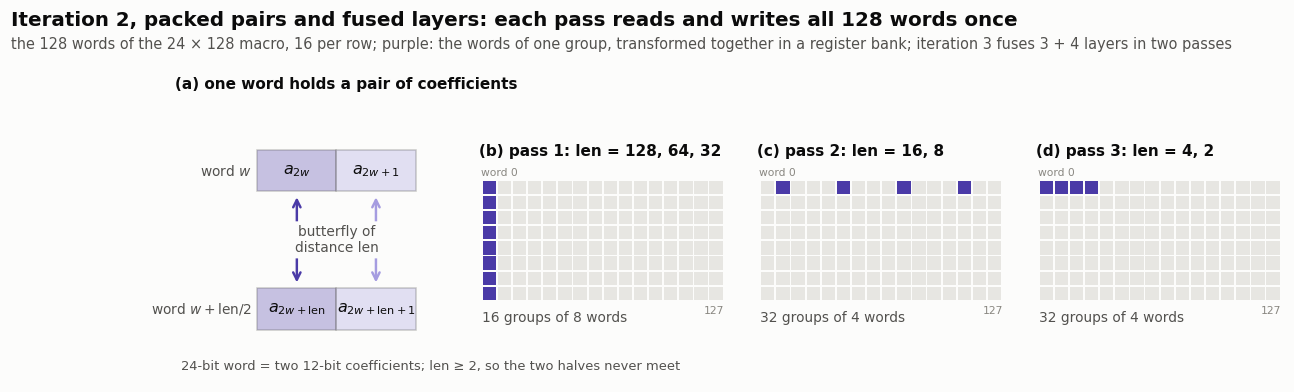

In [24]:
from matplotlib.patches import Rectangle, FancyArrowPatch
BLUE, LIGHT = ps.IT2, "#e7e6e2"
fig = plt.figure(figsize=(13, 3.7))
gs_ = fig.add_gridspec(1, 4, width_ratios=[1.1, 1, 1, 1], wspace=0.12)
ax = fig.add_subplot(gs_[0]); ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off")
ax.set_title("(a) one word holds a pair of coefficients", loc="left", fontsize=10)
for y, lab, lo, hi in [(7.6, "word $w$", "$a_{2w}$", "$a_{2w+1}$"), (2.6, "word $w + \\mathrm{len}/2$", "$a_{2w+\\mathrm{len}}$", "$a_{2w+\\mathrm{len}+1}$")]:
    for k, (txt, x) in enumerate(((lo, 3.0), (hi, 5.9))):
        ax.add_patch(Rectangle((x, y - 0.75), 2.9, 1.5, facecolor=BLUE if k == 0 else ps.IT2_LIGHT, alpha=0.3,
                               edgecolor=ps.INK_2, linewidth=1))
        ax.text(x + 1.45, y, txt, ha="center", va="center", fontsize=10.5, color=ps.INK)
    ax.text(2.8, y, lab, ha="right", va="center", fontsize=9, color=ps.INK_2)
for x, c in ((4.45, BLUE), (7.35, ps.IT2_LIGHT)):
    ax.add_patch(FancyArrowPatch((x, 6.75), (x, 3.45), arrowstyle="<->", mutation_scale=12, color=c, linewidth=1.6))
ax.text(5.9, 5.1, "butterfly of\ndistance len", ha="center", va="center", fontsize=9, color=ps.INK_2,
        bbox=dict(boxstyle="round,pad=0.25", facecolor=ps.SURFACE, edgecolor="none"))
ax.text(0.2, 0.4, "24-bit word = two 12-bit coefficients; len ≥ 2, so the two halves never meet",
        fontsize=8.5, color=ps.INK_2)
PASSES = [("(b) pass 1: len = 128, 64, 32", lambda w: w % 16, 0, "16 groups of 8 words"),
          ("(c) pass 2: len = 16, 8", lambda w: (w // 16) * 4 + w % 4, 1, "32 groups of 4 words"),
          ("(d) pass 3: len = 4, 2", lambda w: w // 4, 0, "32 groups of 4 words")]
for i, (title, group, w0, note) in enumerate(PASSES):
    ax = fig.add_subplot(gs_[i + 1])
    ax.set_xlim(-0.2, 16.2); ax.set_ylim(8.9, -0.6); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, loc="left", fontsize=10)
    for w in range(128):
        r, c = divmod(w, 16)
        ax.add_patch(Rectangle((c + 0.06, r + 0.06), 0.88, 0.88, edgecolor="none",
                               facecolor=BLUE if group(w) == group(w0) else LIGHT))
    ax.text(0, 8.65, note, fontsize=9, color=ps.INK_2, va="top")
    ax.text(-0.05, -0.15, "word 0", fontsize=7, color=ps.MUTED, va="bottom")
    ax.text(16.05, 8.35, "127", fontsize=7, color=ps.MUTED, ha="right", va="top")
    # each pass's groups partition the 128 words: every word is read and written once per pass
    sizes = pd.Series([group(w) for w in range(128)]).value_counts()
    assert sizes.nunique() == 1 and sizes.iloc[0] * len(sizes) == 128
import warnings
with warnings.catch_warnings():        # equal-aspect panels: tight_layout cannot fit them exactly
    warnings.simplefilter("ignore", UserWarning)
    ps.finish(fig, title="Iteration 2, packed pairs and fused layers: each pass reads and writes all 128 words once",
              subtitle="the 128 words of the 24 × 128 macro, 16 per row; purple: the words of one group, "
                       "transformed together in a register bank; iteration 3 fuses 3 + 4 layers in two passes")
fig.subplots_adjust(top=0.79)
ps.save_pdf(fig, "packed_ntt_schedule"); plt.show()

Both ideas have prior art. FPGA accelerators for Kyber, the scheme standardized as ML-KEM, store coefficient
pairs in one memory word and run a butterfly unit on each half [13], and microcontroller software merges NTT
layers [15]. To our knowledge, neither [13] nor [14] combines the two on one single-port,
compiler-generated SRAM. Concurrent work schedules a conflict-free NTT on single-port RAMs for ML-DSA [19], NIST's post-quantum
signature standard. `rtl/kyber_ntt_engine_packed.sv` keeps the original ports, and
`golden/packed_ntt_model.py` reproduces its schedule cycle by cycle.

In [25]:
if IN_COLAB:
    sh("bash scripts/run_sim_packed.sh")
PK = ["ntt_macro", "ntt_opt_pipe_macro", "ntt_packed"]
pk = pnr[(pnr.clk_target_ns == 20) & pnr.variant.isin(PK)].set_index("variant").loc[PK]
gpk = {v: json.loads((ROOT/"results/gls_power"/f"{v}_20ns"/"summary.json").read_text()) for v in PK}
acc_ = {v: sum(gpk[v]["macro_accesses"][k] for k in ("writes", "reads_new_address", "reads_same_address")) for v in PK}
ar_ = {v: total_area(f"{v}_20ns") for v in PK}
feol_ = json.loads((ROOT/"results/asic/feol_blocks.json").read_text())["layouts"]
ptab = pd.DataFrame({
    "standard cells [mm²]": [ar_[v][0] / 1e6 for v in PK],
    "SRAM macro [mm²]": [ar_[v][1] / 1e6 for v in PK],
    "fmax [MHz]": pk.fmax_mhz.values,
    "cycles, forward / inverse NTT": [f"{int(a):,} / {int(b):,}" for a, b in zip(pk.cycles, pk.cycles_inv)],
    "forward-NTT latency [µs]": pk.latency_us_at_fmax.values,
    "macro accesses per forward NTT": [acc_[v] for v in PK],
    "energy per forward NTT [µJ]": [gpk[v]["energy_per_forward_ntt_nj"] / 1e3 for v in PK],
    "DRC / antenna / front-end-of-line (FEOL)": [f"{int(pk.drc_errors[v])} / {int(pk.antenna_violating_nets[v])} / "
                             f"{feol_[v + '_20ns']['feol_markers']}" for v in PK],
}, index=[LABEL[v] for v in PK])
ptab.insert(2, "total area [mm²]", ptab["standard cells [mm²]"] + ptab["SRAM macro [mm²]"])
ptab["area × time, total [mm²·µs]"] = ptab["total area [mm²]"] * ptab["forward-NTT latency [µs]"]
sp_log = {x: (ROOT/"results/sim_packed"/f"packed_x{x}.log").read_text() for x in (0, 1)}
display(ptab.round(3))
# guards for the statements made in the text below
o_, n_ = ptab.iloc[0], ptab.iloc[2]
assert all("errors=0" in l and "timing_variations=0" in l for l in sp_log.values())
assert re.search(r"cycles_fwd=988 cycles_inv=1116", sp_log[1]) and int(pk.cycles["ntt_packed"]) == 988
assert gpk["ntt_packed"]["gls_pass"] and 768 <= acc_["ntt_packed"] < 800 and acc_["ntt_macro"] == 6274
assert acc_["ntt_packed"] - gpk["ntt_packed"]["macro_accesses"]["reads_same_address"] == 768   # "768 scheduled accesses"
assert gpk["ntt_packed"]["logic_energy_per_forward_ntt_nj"] > gpk["ntt_packed"]["macro_energy_nj"]   # "most of what remains"
assert all(0.73 < gpk[v]["macro_energy_nj"] / gpk[v]["energy_per_forward_ntt_nj"] < 0.75 for v in PK[:2])
assert ptab["DRC / antenna / front-end-of-line (FEOL)"].eq("0 / 0 / 0").all() and slew_violations("ntt_packed_20ns", cells_only=True) == 0
assert o_["forward-NTT latency [µs]"] / n_["forward-NTT latency [µs]"] > 8
assert ptab.iloc[1]["forward-NTT latency [µs]"] / n_["forward-NTT latency [µs]"] > 5
assert 0.28 < n_["energy per forward NTT [µJ]"] / o_["energy per forward NTT [µJ]"] < 0.38      # "about a third"
assert 1.35 < n_["total area [mm²]"] / o_["total area [mm²]"] < 1.55
assert o_["area × time, total [mm²·µs]"] / n_["area × time, total [mm²·µs]"] > 5

,standard cells [mm²],SRAM macro [mm²],total area [mm²],fmax [MHz],"cycles, forward / inverse NTT",forward-NTT latency [µs],macro accesses per forward NTT,energy per forward NTT [µJ],DRC / antenna / front-end-of-line (FEOL),"area × time, total [mm²·µs]"
"original NTT, 16 × 256 macro (HSKEM-1)",0.039,0.103,0.141,48.077,"6,274 / 7,554",130.499,6274,0.504,0 / 0 / 0,18.465
"iteration 1: pipeline, 16 × 256 macro",0.033,0.103,0.136,82.850,"7,170 / 8,706",86.542,7170,0.574,0 / 0 / 0,11.728
"iteration 2: packed pairs, 24 × 128 macro",0.076,0.132,0.208,68.399,"988 / 1,116",14.445,769,0.161,0 / 0 / 0,2.999


The pairing pays off in every figure of merit except area: a forward transform takes 988 instead of 6,274
cycles and, at its higher clock, finishes nine times sooner than the original macro-store engine and six
times sooner than the pipelined one. It needs about a third of the energy, because the macro is selected only 769
times; most of the rest clocks the two register banks. The price is a block almost half
larger, with a quarter more macro and twice the standard cells, while the area–time product falls sixfold.
The routed netlist is bit-exact, with data-independent latency and a clean layout.

### A third iteration: two butterflies per word, 568 instead of 988 cycles

Because the two coefficients in a word never meet in a butterfly, the third iteration processes them at
once, each half of the word in its own butterfly unit as in [13], and fuses the layers as three plus four, so that
two passes cover a transform. Its extra stream ports, through which the datapath of Section 8 feeds and drains the engine directly,
are idle here and checked by `tb/tb_ntt_stream.sv`.

In [26]:
if IN_COLAB:
    sh("CAC_PACKED2=1 bash scripts/run_sim_packed.sh")
P2 = ["ntt_packed", "ntt_packed2"]
pk2 = pnr[(pnr.clk_target_ns == 20) & pnr.variant.isin(P2)].set_index("variant").loc[P2]
g2 = {v: json.loads((ROOT/"results/gls_power"/f"{v}_20ns"/"summary.json").read_text()) for v in P2}
a2 = {v: total_area(f"{v}_20ns") for v in P2}
acc2 = {v: sum(g2[v]["macro_accesses"][k] for k in ("writes", "reads_new_address", "reads_same_address")) for v in P2}
ptab2 = pd.DataFrame({
    "standard cells [mm²]": [a2[v][0] / 1e6 for v in P2],
    "total area [mm²]": [sum(a2[v]) / 1e6 for v in P2],
    "fmax [MHz]": pk2.fmax_mhz.values,
    "cycles, forward / inverse NTT": [f"{int(a):,} / {int(b):,}" for a, b in zip(pk2.cycles, pk2.cycles_inv)],
    "forward-NTT latency [µs]": pk2.latency_us_at_fmax.values,
    "macro accesses per forward NTT": [acc2[v] for v in P2],
    "energy per forward NTT [µJ]": [g2[v]["energy_per_forward_ntt_nj"] / 1e3 for v in P2],
    "DRC / antenna / front-end-of-line (FEOL)": [f"{int(pk2.drc_errors[v])} / {int(pk2.antenna_violating_nets[v])} / "
                             f"{feol_[v + '_20ns']['feol_markers']}" for v in P2],
}, index=[LABEL[v] for v in P2])
ptab2["area × time, total [mm²·µs]"] = ptab2["total area [mm²]"] * ptab2["forward-NTT latency [µs]"]
sp2 = {x: (ROOT/"results/sim_packed"/f"packed2{x}.log").read_text() for x in ("_x1", "_stream_x1")}
display(ptab2.round(3))
# guards for the statements made in the text below
q1, q2 = ptab2.iloc[0], ptab2.iloc[1]
assert all("errors=0" in l and "timing_variations=0" in l for l in sp2.values())
assert re.search(r"cycles_fwd=568 cycles_inv=569", sp2["_x1"])
assert g2["ntt_packed2"]["gls_pass"] and acc2["ntt_packed2"] == 513
assert 1.45 < q1["forward-NTT latency [µs]"] / q2["forward-NTT latency [µs]"] < 1.6       # "half again as fast"
assert 0.85 < q2["energy per forward NTT [µJ]"] / q1["energy per forward NTT [µJ]"] < 0.9  # "about an eighth less"
assert 1.75 < q2["standard cells [mm²]"] / q1["standard cells [mm²]"] < 1.9               # "almost twice"
assert 1.25 < q2["total area [mm²]"] / q1["total area [mm²]"] < 1.35                     # "by almost a third"
assert 0.82 < q2["area × time, total [mm²·µs]"] / q1["area × time, total [mm²·µs]"] < 0.88  # "falls by about 15 %"
assert ptab2["DRC / antenna / front-end-of-line (FEOL)"].eq("0 / 0 / 0").all()

,standard cells [mm²],total area [mm²],fmax [MHz],"cycles, forward / inverse NTT",forward-NTT latency [µs],macro accesses per forward NTT,energy per forward NTT [µJ],DRC / antenna / front-end-of-line (FEOL),"area × time, total [mm²·µs]"
"iteration 2: packed pairs, 24 × 128 macro",0.076,0.208,68.399,"988 / 1,116",14.445,769,0.161,0 / 0 / 0,2.999
"iteration 3: two lanes, 24 × 128 macro (HSKEM-2)",0.137,0.269,59.844,568 / 569,9.491,513,0.141,0 / 0 / 0,2.557


Two lanes finish a transform in 568 instead of 988 cycles, although the larger datapath lowers the clock
from 68 to 60 MHz, and with 513 instead of 769 macro accesses a transform costs about an eighth less
energy. The second butterfly and larger banks almost double the standard cells, but the macro stays the
same, so the block grows by almost a third and its area–time product still falls by about 15 %. This
bit-exact engine, on a clean layout, is the NTT that HSKEM-2 carries.

In [27]:
# tb/tb_ntt_access_count.sv counts the enabled clock edges of the macro during each transform
acc_n = json.loads((ROOT/"results/ntt_access_count/summary.json").read_text())["measured"]
assert all(acc_n[d]["sram_word_reads"] == acc_n[d]["sram_word_writes"] == 256 for d in ("forward", "inverse"))
assert acc_n["forward"]["cycles"] == 568 and acc_n["inverse"]["cycles"] == 569
print("measured per transform:", acc_n["forward"]["sram_word_reads"], "word reads and", acc_n["forward"]["sram_word_writes"],
      "word writes; one pass per layer would need", 7 * 128, "of each")

measured per transform: 256 word reads and 256 word writes; one pass per layer would need 896 of each


Counting the macro's enabled clock edges confirms the two passes (output above).

### What the iterations buy

The figure sets each original engine (grey) beside its iterations; Appendix B.1 plots the NTT
layouts against each other.

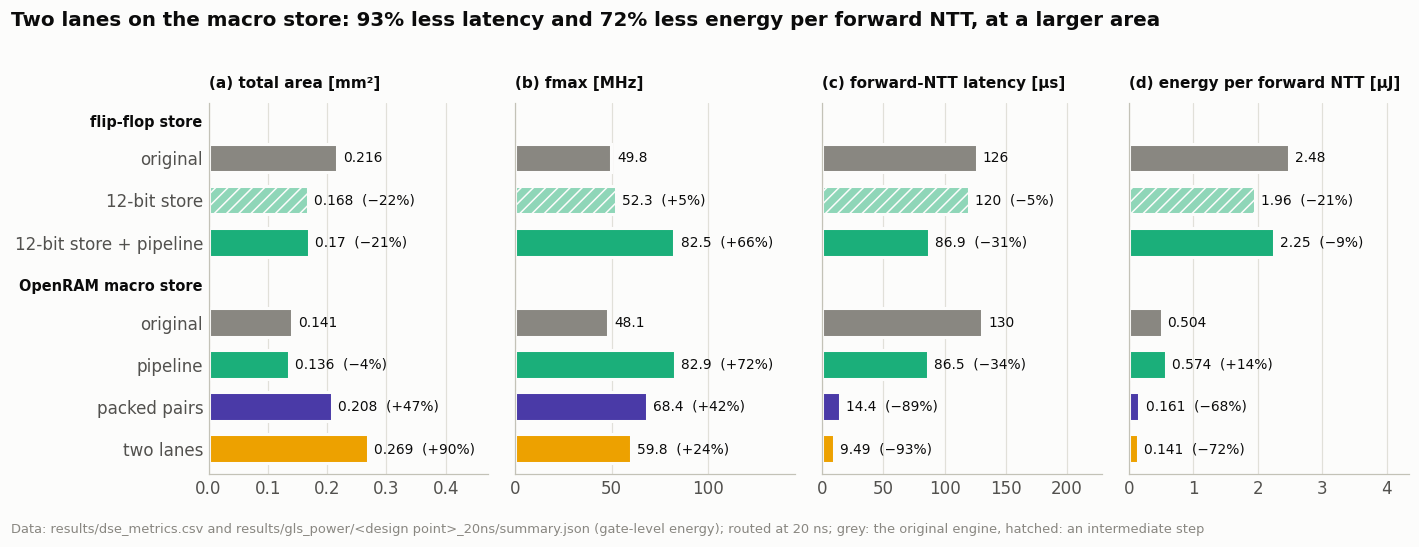

In [28]:
GROUPS = [("flip-flop store", ["ntt_sp", "ntt_opt_b1_w12", "ntt_opt_pipe_w12"]),
          ("OpenRAM macro store", ["ntt_macro", "ntt_opt_pipe_macro", "ntt_packed", "ntt_packed2"])]
NAMES = {"ntt_sp": "original", "ntt_opt_b1_w12": "12-bit store", "ntt_opt_pipe_w12": "12-bit store + pipeline",
         "ntt_macro": "original", "ntt_opt_pipe_macro": "pipeline", "ntt_packed": "packed pairs",
         "ntt_packed2": "two lanes"}
P20 = pnr[pnr.clk_target_ns == 20].set_index("variant")
def _energy_uj(v):
    return json.loads((ROOT/"results/gls_power"/f"{v}_20ns"/"summary.json").read_text())["energy_per_forward_ntt_nj"] / 1e3
METRICS = [("total area [mm²]", lambda v: sum(total_area(f"{v}_20ns")) / 1e6),
           ("fmax [MHz]", lambda v: P20.fmax_mhz[v]),
           ("forward-NTT latency [µs]", lambda v: P20.latency_us_at_fmax[v]),
           ("energy per forward NTT [µJ]", _energy_uj)]
rows = [(g, v, vs[0]) for g, vs in GROUPS for v in vs]
ypos = [0, 1, 2, 3.9, 4.9, 5.9, 6.9]
fig, axes = plt.subplots(1, 4, figsize=(13, 4.5), sharey=True)
for ax, tag, (name, f) in zip(axes, "abcd", METRICS):
    vals = [f(v) for _, v, _ in rows]
    for y, (g, v, ref_v), x in zip(ypos, rows, vals):
        ax.barh(y, x, height=0.68, hatch="///" if v == "ntt_opt_b1_w12" else None,
                **ps.bar_kw(ps.MUTED if v == ref_v else COLOR[v]))
        txt = f"{x:.3g}" + ("" if v == ref_v else f"  ({x / f(ref_v) - 1:+.0%})".replace("-", "−"))
        ax.annotate(txt, (x, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=ps.INK)
    ax.set_title(f"({tag}) {name}", loc="left", fontsize=10)
    ax.set_xlim(0, max(vals) * 1.75); ax.grid(axis="y", visible=False)
axes[0].set_yticks(ypos, [NAMES[v] for _, v, _ in rows]); axes[0].set_ylim(7.5, -1.3)
for g, y in ((GROUPS[0][0], -0.85), (GROUPS[1][0], 3.05)):
    axes[0].annotate(g, (0, y), xycoords=("axes fraction", "data"), xytext=(-4, 0), textcoords="offset points",
                     ha="right", va="center", fontsize=9.5, fontweight="bold", color=ps.INK)
lat_ = P20.latency_us_at_fmax["ntt_packed2"] / P20.latency_us_at_fmax["ntt_macro"]
en_ = _energy_uj("ntt_packed2") / _energy_uj("ntt_macro")
ps.finish(fig, title=f"Two lanes on the macro store: {1 - lat_:.0%} less latency and {1 - en_:.0%} less energy per "
                     "forward NTT, at a larger area")
ps.source(fig, "results/dse_metrics.csv and results/gls_power/<design point>_20ns/summary.json (gate-level energy); "
              "routed at 20 ns; grey: the original engine, hatched: an intermediate step")
ps.save_pdf(fig, "redesign_effect"); plt.show()

A faster engine, however, shortens a decapsulation only while the rest of the co-processor keeps it busy,
which Section 8 measures.

## 8. The whole co-processor: from 99,537 to 6,856 cycles per decapsulation

On the chip, the blocks above share one digital core with the SPI front end, the HSM policy logic,
SHA-256/HMAC, AES-256, the PUF services and 18 OpenRAM [9] SRAM macros. This section prices HSKEM-1's two
decisions on that core and follows its profile to the design of HSKEM-2.

### HSKEM-1's decisions at system level: the single port costs most

A block nine times slower matters little if the system rarely waits for it. The full-system testbench
drives the co-processor over SPI as the ESP32 host does and measures the busy interval of a decapsulation
in four configurations: the FPGA one, each ASIC decision alone, and both together, which is HSKEM-1. A
cycle model inside the testbench, its cycle oracle, predicts each count from the loop counts of the
configuration, and every build is checked against it; the build with only the row-serialized Keccak, which the
oracle does not cover, must equal the FPGA count plus 144 cycles per permutation. The FPGA count also reproduces
an earlier ModelSim run.

,decapsulation cycles,Keccak permutations,shared-secret fingerprints,testbench result,decapsulation at 50 MHz [ms],change vs FPGA configuration
FPGA configuration,81457,26,27033e5e,all checks pass,1.6291,0
row-serialized Keccak only,85201,26,27033e5e,all checks pass except the cycle oracle (see below),1.7040,3744
single-port store only,95793,26,27033e5e,all checks pass,1.9159,14336
HSKEM-1 configuration (both choices),99537,26,27033e5e,all checks pass,1.9907,18080


published RTL copy (hskem_rtl/): ALL PASS, decapsulation 81,457 cycles
single-port store: +14336 cycles = 8 transforms x 896 butterflies x 2
row-serialized Keccak: +3744 cycles = 26 permutations x 144
the two effects add exactly: True
row-serialized Keccak only: the testbench's built-in cycle oracle knows only the FPGA and ASIC configurations, so its 7 failing lines are cycle-count comparisons; every digest and shared key matches, and each measured count equals the FPGA count plus 144 cycles per Keccak permutation


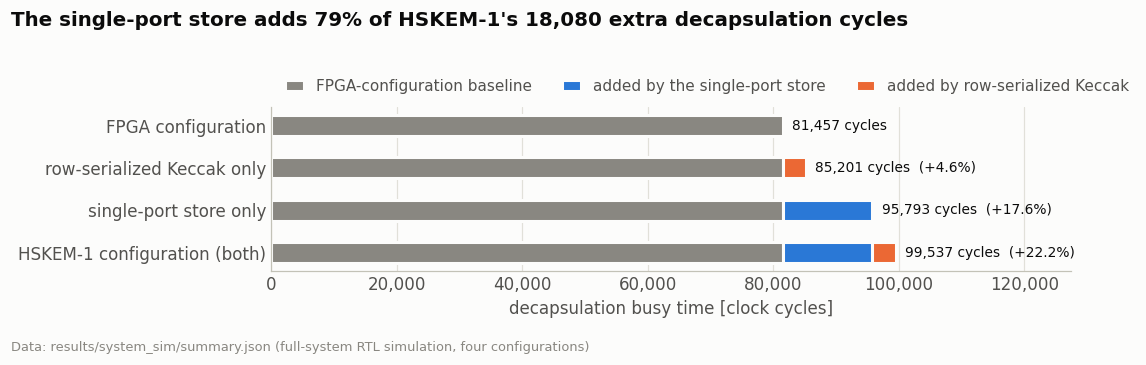

In [29]:
ss_ = json.loads((ROOT/"results/system_sim/summary.json").read_text())
cfg = pd.DataFrame(ss_["configs"]).T[["decaps_cycles", "decaps_keccak_permutations", "shared_secret_fingerprints", "tb_result"]]
cfg["decaps_ms_at_50MHz"] = cfg.decaps_cycles.astype(float) / 50e6 * 1e3
cfg["delta_vs_fpga"] = cfg.decaps_cycles.astype(int) - int(cfg.loc["fpga", "decaps_cycles"])
show_cfg = cfg.copy()
show_cfg["shared_secret_fingerprints"] = show_cfg.shared_secret_fingerprints.map(lambda f: ", ".join(f))
show_cfg["tb_result"] = show_cfg.tb_result.map(lambda r: "all checks pass" if r.startswith("ALL PASS")
                                               else "all checks pass except the cycle oracle (see below)")
display(show_cfg)
dec = ss_["decomposition"]
assert dec["additive"] and dec["keccak_serial_delta"] == dec["keccak_serial_model"] \
       and dec["single_port_sram_delta"] == dec["single_port_sram_model"]
assert cfg.shared_secret_fingerprints.map(tuple).nunique() == 1, "configurations disagree on the shared key"
pc = ss_["published_copy_check"]
assert pc["tb_result"].startswith("ALL PASS") and pc["decaps_cycles"] == int(cfg.loc["fpga", "decaps_cycles"])
print(f"published RTL copy (hskem_rtl/): {pc['tb_result'][:8]}, decapsulation {pc['decaps_cycles']:,} cycles")
print(f"single-port store: +{dec['single_port_sram_delta']} cycles = 8 transforms x 896 butterflies x 2")
print(f"row-serialized Keccak: +{dec['keccak_serial_delta']} cycles = 26 permutations x 144")
print("the two effects add exactly:", dec["additive"])
assert dec["both_delta"] == 18080 and 0.78 < dec["single_port_sram_delta"] / dec["both_delta"] < 0.81   # "four fifths of 18,080"
assert "cycle-count equality checks only" in ss_["note_keccak_only"]
print("row-serialized Keccak only: the testbench's built-in cycle oracle knows only the FPGA and ASIC configurations, "
      "so its 7 failing lines are cycle-count comparisons; every digest and shared key matches, and each measured count "
      "equals the FPGA count plus 144 cycles per Keccak permutation")

base = int(cfg.loc["fpga", "decaps_cycles"])
rows = [("FPGA configuration", 0, 0), ("row-serialized Keccak only", 0, dec["keccak_serial_delta"]),
        ("single-port store only", dec["single_port_sram_delta"], 0),
        ("HSKEM-1 configuration (both)", dec["single_port_sram_delta"], dec["keccak_serial_delta"])][::-1]
fig, ax = plt.subplots(figsize=(10, 2.9))
for y, (name, ntt_extra, kec_extra) in enumerate(rows):
    ax.barh(y, base, height=0.5, label="FPGA-configuration baseline" if y == 0 else None, **ps.bar_kw(ps.MUTED))
    if ntt_extra:
        ax.barh(y, ntt_extra, left=base, height=0.5, label="added by the single-port store" if y == 0 else None, **ps.bar_kw(ps.SERIES[0]))
    if kec_extra:
        ax.barh(y, kec_extra, left=base + ntt_extra, height=0.5, label="added by row-serialized Keccak" if y == 0 else None, **ps.bar_kw(ps.SERIES[1]))
    total = base + ntt_extra + kec_extra
    ax.annotate(f"{total:,} cycles" + (f"  (+{total / base - 1:.1%})" if total > base else ""),
                (total, y), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=ps.INK)
ax.set_yticks(range(len(rows)), [r[0] for r in rows]); ax.grid(axis="y", visible=False)
ax.set_xlim(0, (base + dec["both_delta"]) * 1.28); ax.set_xlabel("decapsulation busy time [clock cycles]")
ps.thousands(ax)
ax.legend(ncols=3, loc="lower left", bbox_to_anchor=(0, 1.0), handlelength=1.2)
ps.finish(fig, title=f"The single-port store adds {dec['single_port_sram_delta'] / dec['both_delta']:.0%} of HSKEM-1's "
                     f"{dec['both_delta']:,} extra decapsulation cycles")
ps.source(fig, "results/system_sim/summary.json (full-system RTL simulation, four configurations)"); plt.show()

As the figure shows, the single-port store accounts for four fifths of the 18,080 cycles that HSKEM-1 adds to the
FPGA configuration, and the row-serialized Keccak for the rest, 3.9 % on top of the store alone. The identical fingerprints, short hashes of the shared key, show the same shared
secret in every configuration, and valid and implicitly rejected ciphertexts take equally long, so the
timing does not reveal which arrived. To see where the remaining cycles go, a monitor (`tb/decaps_profiler.sv`) records in every cycle whether
the NTT engine, the Keccak sponge and the permutation inside it are busy, leaving RTL and testbench untouched.

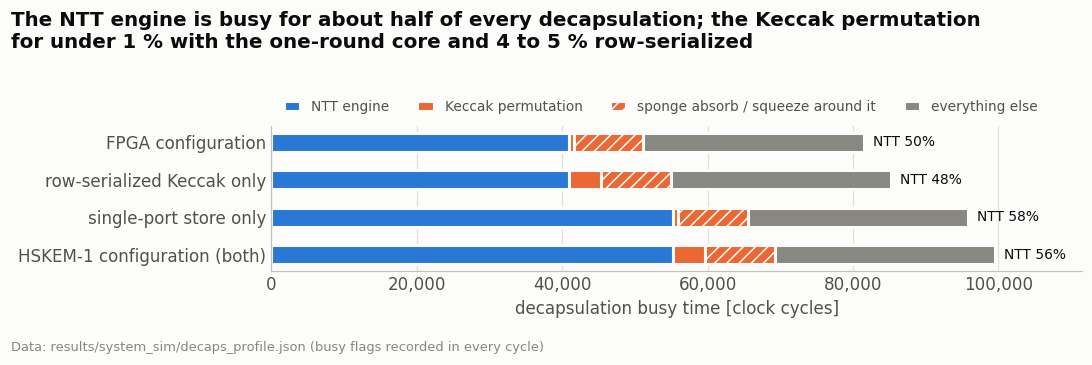

,NTT engine,Keccak permutation,sponge absorb / squeeze around it,everything else
FPGA configuration,0.503,0.008,0.118,0.372
row-serialized Keccak only,0.481,0.051,0.112,0.356
single-port store only,0.577,0.007,0.100,0.316
HSKEM-1 configuration (both),0.556,0.044,0.096,0.304


In [30]:
# True re-runs the profiled full-system simulation of the FPGA and ASIC configurations with Icarus
# Verilog (about six minutes, both in parallel; works in Colab); the two single-decision
# configurations are then read from the committed logs
RUN_SYSTEM_SIM = False
if RUN_SYSTEM_SIM:
    sh("for c in fpga asic; do CAC_PROFILE=1 CAC_SIM_TAG=_prof bash scripts/run_system_sim.sh $c & done; wait")
    sh("python3 scripts/collect_profile.py")
prof = json.loads((ROOT/"results/system_sim/decaps_profile.json").read_text())["configs"]
pf = pd.DataFrame({c: v["profile"] for c, v in prof.items()}).T
# the profile must reproduce the testbench's own latency and the decomposition above
assert (pf.cycles == cfg.loc[pf.index, "decaps_cycles"].astype(int)).all()
assert pf.ntt_and_sponge.eq(0).all(), "NTT and sponge were expected never to overlap"
assert pf.other.nunique() == 1 and pf.sponge_io.nunique() == 1, "the ASIC choices changed unrelated work"
assert pf.loc["sram_only", "ntt_busy"] - pf.loc["fpga", "ntt_busy"] == dec["single_port_sram_delta"]
assert pf.loc["keccak_only", "perm_busy"] - pf.loc["fpga", "perm_busy"] == dec["keccak_serial_delta"]
assert (pf.ntt_starts == 8).all() and (pf.ntt_inverse_starts == 4).all() and (pf.perm_starts == 26).all()
fp = pf.loc["fpga"]   # guards for the statements made in the text below
assert 0.45 < fp.ntt_busy / fp.cycles < 0.55 and fp.perm_busy / fp.cycles < 0.01
assert 15 < fp.sponge_busy / fp.perm_busy < 17.5 and 0.33 < fp.other / fp.cycles < 0.40

parts = [("ntt_busy", "NTT engine", ps.SERIES[0]), ("perm_busy", "Keccak permutation", ps.SERIES[1]),
         ("sponge_io", "sponge absorb / squeeze around it", ps.KECCAK), ("other", "everything else", ps.MUTED)]
names = {"fpga": "FPGA configuration", "keccak_only": "row-serialized Keccak only",
         "sram_only": "single-port store only", "asic": "HSKEM-1 configuration (both)"}
order = ["asic", "sram_only", "keccak_only", "fpga"]
fig, ax = plt.subplots(figsize=(10, 2.9))
for y, c in enumerate(order):
    left = 0
    for col, lab, colour in parts:
        ax.barh(y, pf.loc[c, col], left=left, height=0.5, label=lab if y == 0 else None,
                hatch="///" if col == "sponge_io" else None, **ps.bar_kw(colour))
        left += pf.loc[c, col]
    ax.annotate(f"NTT {pf.loc[c, 'ntt_busy'] / pf.loc[c, 'cycles']:.0%}", (left, y), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color=ps.INK)
ax.set_yticks(range(len(order)), [names[c] for c in order]); ax.grid(axis="y", visible=False)
ax.set_xlim(0, pf.cycles.max() * 1.12); ax.set_xlabel("decapsulation busy time [clock cycles]"); ps.thousands(ax)
ax.legend(ncols=4, loc="lower left", bbox_to_anchor=(0, 1.0), handlelength=1.2, fontsize=9)
ps.finish(fig, title="The NTT engine is busy for about half of every decapsulation; the Keccak permutation\n"
                     "for under 1 % with the one-round core and 4 to 5 % row-serialized")
ps.source(fig, "results/system_sim/decaps_profile.json (busy flags recorded in every cycle)"); plt.show()
share = pf[[p[0] for p in parts]].div(pf.cycles, axis=0)
share.columns = [p[1] for p in parts]
share.rename(index=names).round(3)

The profile confirms the decomposition to the cycle, and each decision changes only its own share. In the
FPGA configuration the NTT is busy for half of the decapsulation and the permutation for under one percent.
The sponge around the permutation, which moves one byte per handshake, is busy about sixteen times longer,
and more than a third of the cycles go to the rest of the datapath. A faster NTT or a wider sponge
interface, not a faster permutation, was therefore the promising target.

### Steps A to D: a decapsulation 2.8 times faster

The profile names the NTT as the place where a faster engine pays. `scripts/make_packed_system.py` builds
the complete co-processor from the untouched published RTL (Appendix E.3) and applies four steps, A to D, each a
compile-time switch (a Verilog define) that removes no check and changes no output:

* **A** installs the packed engine of Section 7;
* **B** restores the one-round Keccak, faster and only 1.4 % larger (Section 6), because the permutation's
  share grows once the NTT is short;
* **C** runs the three hashes that depend only on the inputs, H(ek), H(c) and J(z‖c), on a second
  controller while the ciphertext is being decrypted;
* **D** drops a redundant wait state from ten loops that read one element at a time.

Every build passes the original full-system testbench, including the shared keys, the implicit rejection
and the equal latency of valid and rejected ciphertexts.

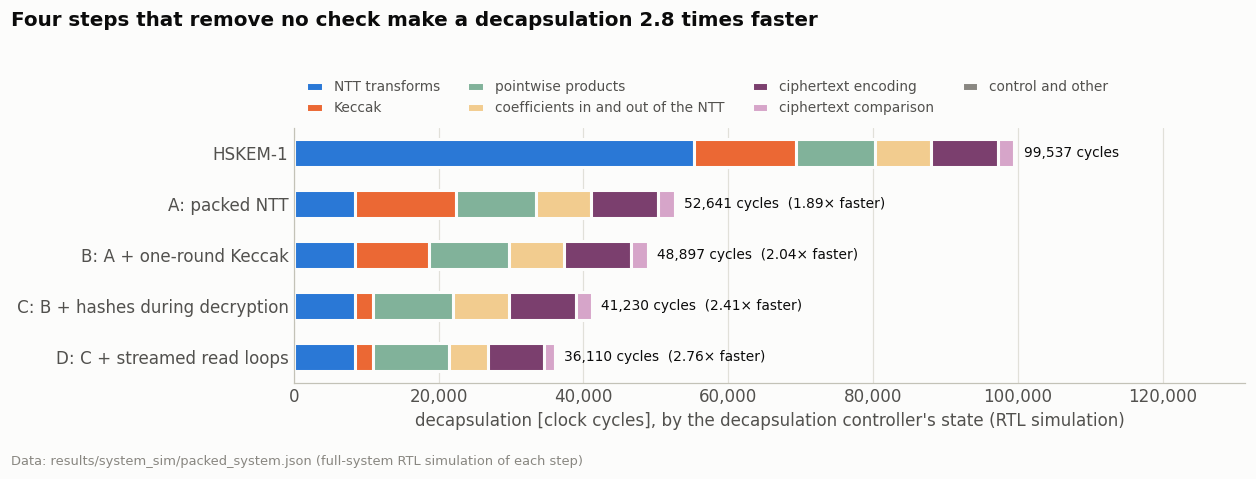

,NTT transforms,Keccak,pointwise products,coefficients in and out of the NTT,ciphertext encoding,ciphertext comparison,control and other,total
HSKEM-1,55320,13996,11011,7680,9220,2304,6,99537
A: packed NTT,8424,13996,11011,7680,9220,2304,6,52641
B: A + one-round Keccak,8424,10252,11011,7680,9220,2304,6,48897
C: B + hashes during decryption,8424,2585,11011,7680,9220,2304,6,41230
D: C + streamed read loops,8424,2585,10499,5376,7684,1536,6,36110


In [31]:
# True re-runs the eight builds (about fifteen minutes in parallel; works in Colab)
RUN_PACKED_SYSTEM = False
if RUN_PACKED_SYSTEM:
    sh("bash scripts/run_packed_system.sh")
psys = json.loads((ROOT/"results/system_sim/packed_system.json").read_text())
cs = psys["configs"]
STEPS = [("asic_sysR", "HSKEM-1"), ("asic_sysA", "A: packed NTT"),
         ("sram_only_sysB", "B: A + one-round Keccak"), ("sram_only_sysBC", "C: B + hashes during decryption"),
         ("sram_only_sysBCD", "D: C + streamed read loops")]
# every build passes the full-system testbench; valid and rejected ciphertexts take equally long
assert all(v["tb_result"].startswith("ALL PASS") for v in cs.values())
assert all(v["profiled_intervals_used"] >= 2 for v in cs.values())
assert all(v["packed_contract_check"]["violations"] == 0 for t, v in cs.items() if t != "asic_sysR")
assert all(psys["model_checks"].values()), psys["model_checks"]     # each step as the cycle model predicts
cyc_ = {t: cs[t]["decaps_cycles_valid_and_rejected"] for t, _ in STEPS}
assert cyc_["asic_sysR"] == int(cfg.loc["asic", "decaps_cycles"])     # without the defines: the published chip
ph_ = cs["sram_only_sysB"]["phases"]
assert ph_["hashes_h_ek_h_c_j"] < ph_["decryption"]                  # so the overlap hides the hashes entirely
GCOL = {"NTT transforms": ps.NTT, "Keccak": ps.KECCAK, "pointwise products": ps.LOGIC,
        "coefficients in and out of the NTT": ps.MEM, "ciphertext encoding": ps.CODEC,
        "ciphertext comparison": ps.CODEC_CMP, "control and other": ps.OTHER}
GHATCH = {}
fig, ax = plt.subplots(figsize=(11.5, 3.9))
for y, (t, name) in enumerate(STEPS[::-1]):
    left = 0
    for g, col in GCOL.items():
        ax.barh(y, cs[t]["groups"][g], left=left, height=0.55, label=g if y == 0 else None, hatch=GHATCH.get(g),
                **ps.bar_kw(col))
        left += cs[t]["groups"][g]
    note = "" if t == "asic_sysR" else f"  ({cyc_['asic_sysR'] / cyc_[t]:.2f}× faster)"
    ax.annotate(f"{cyc_[t]:,} cycles{note}", (left, y), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=ps.INK)
ax.set_yticks(range(len(STEPS)), [n for _, n in STEPS[::-1]]); ax.grid(axis="y", visible=False)
ax.set_xlim(0, cyc_["asic_sysR"] * 1.32); ps.thousands(ax)
ax.set_xlabel("decapsulation [clock cycles], by the decapsulation controller's state (RTL simulation)")
ax.legend(ncols=4, loc="lower left", bbox_to_anchor=(0, 1.0), handlelength=1.2, fontsize=9)
ps.finish(fig, title=f"Four steps that remove no check make a decapsulation {cyc_['asic_sysR'] / cyc_['sram_only_sysBCD']:.1f} times faster")
ps.source(fig, "results/system_sim/packed_system.json (full-system RTL simulation of each step)")
ps.save_pdf(fig, "decaps_redesign"); plt.show()
gtab = pd.DataFrame({name: cs[t]["groups"] for t, name in STEPS}).T
gtab["total"] = gtab.sum(axis=1)
gD = cs["sram_only_sysBCD"]["groups"]           # guards for the shares stated in the text below
assert 0.21 < gD["NTT transforms"] / cyc_["sram_only_sysBCD"] < 0.25
assert 0.6 < (gD["pointwise products"] + gD["ciphertext encoding"] + gD["coefficients in and out of the NTT"]) / cyc_["sram_only_sysBCD"] < 0.72
assert abs(int(cfg.loc["fpga", "decaps_cycles"]) / cyc_["sram_only_sysBCD"] - 2.3) < 0.05
assert cs["sram_only_sysBCD"]["phases"]["decryption"] == 7959 > cs["sram_only_sysB"]["phases"]["hashes_h_ek_h_c_j"]
gtab

Each step matches its cycle model to the cycle (Appendix A.3 derives every saving), and together the four
steps shorten a decapsulation from 99,537 to 36,110 cycles, 2.8 times fewer than HSKEM-1 and 2.3 times
fewer than the FPGA configuration. The NTT now takes under a quarter of
what remains; the pointwise products, the ciphertext encoding and the engine's transfers, still one
coefficient every few cycles, take two thirds and are the next targets.

### Milestones E to H: the datapath catches up with the engine

The profile's next targets define four milestones, E to H, which group twenty-six further changes, each again
a compile-time switch. Each milestone removes the bottleneck that the previous profile exposed (Appendix A.4
lists every change):

* **E** adds a Karatsuba multiplier, which forms each product of two coefficient pairs with three
  coefficient multiplications instead of four (besides the one by a constant), and brings every loop to one element per cycle;
* **F** installs the two-lane engine of Section 7 and moves data in pairs;
* **G** pipelines the checks and the matrix–vector product;
* **H** streams products and sampled noise straight into the transforms.

Every milestone again passes the full-system testbench and matches its cycle model, with the FPGA store
and with the single-port SRAM, which take identical counts, and with either Keccak core.

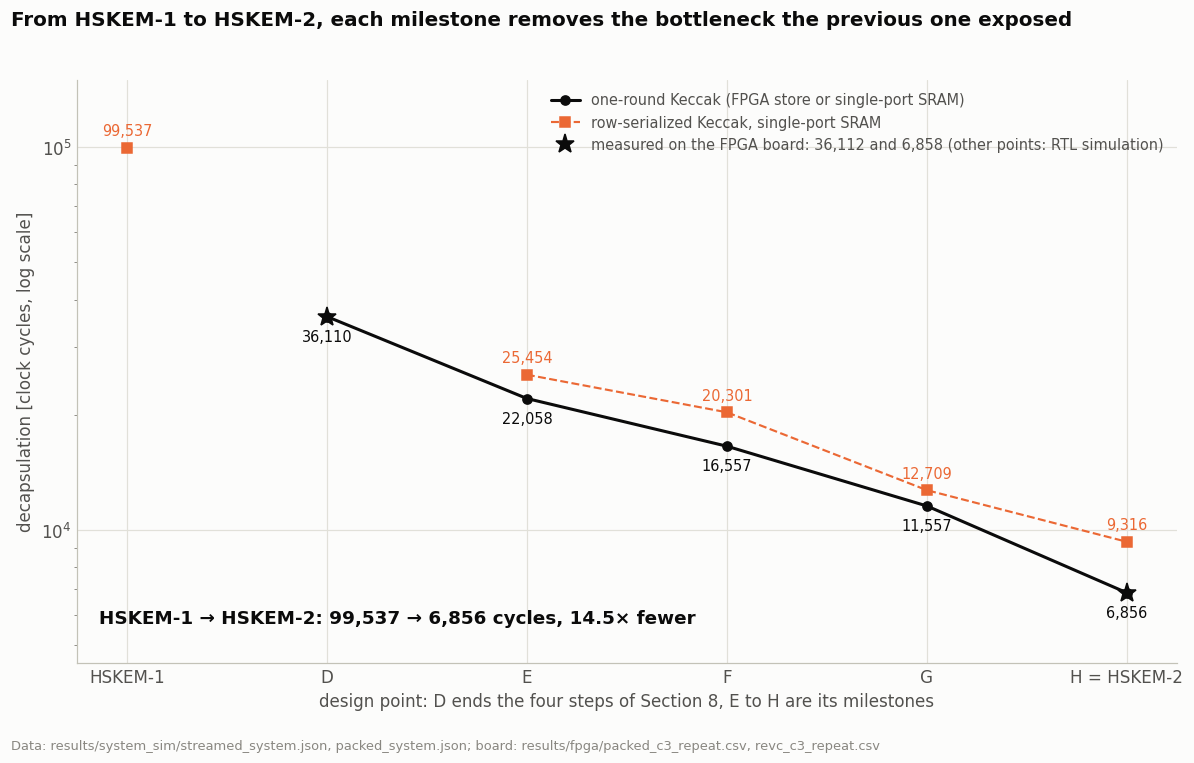

,"decapsulation, one-round Keccak","decapsulation, row-serialized Keccak",runtime encryption,NTT busy [%],sponge busy [%]
E,22058,25454,15462,38.1,35.6
F,16557,20301,11078,27.4,39.9
G,11557,12709,7116,39.3,36.8
H,6856,9316,4601,66.8,65.4


In [32]:
# True re-runs the twelve builds (about a quarter of an hour on twelve cores, longer in Colab; works there too)
RUN_STREAMED_SYSTEM = False
if RUN_STREAMED_SYSTEM:
    sh("bash scripts/run_streamed_system.sh")
ssys = json.loads((ROOT/"results/system_sim/streamed_system.json").read_text())
sc = ssys["configs"]
assert all(ssys["checks"].values()), ssys["checks"]
MS = ["E", "F", "G", "H"]
dc = {m: ssys["decaps_cycles"][m] for m in MS}
STAIR = [("HSKEM-1", cyc_["asic_sysR"], cyc_["asic_sysR"]), ("D", cyc_["sram_only_sysBCD"], None)] + \
        [(m, dc[m]["sram_only"], dc[m]["asic"]) for m in MS]
pbd_ = pd.read_csv(ROOT/"results/fpga/packed_c3_repeat.csv")
fbd_ = pd.read_csv(ROOT/"results/fpga/revc_c3_repeat.csv")
fig, ax = plt.subplots(figsize=(11, 6.4))
xs = list(range(len(STAIR)))
ax.plot(xs[1:], [s[1] for s in STAIR[1:]], marker="o", lw=2, color=ps.INK,
        label="one-round Keccak (FPGA store or single-port SRAM)")
ax.plot(xs[2:], [s[2] for s in STAIR[2:]], marker="s", lw=1.4, ls="--", color=ps.KECCAK,
        label="row-serialized Keccak, single-port SRAM")
ax.plot([0], [STAIR[0][2]], marker="s", ls="none", color=ps.KECCAK)
ax.plot([1, len(STAIR) - 1], [int(pbd_.decaps_cycles.iloc[0]), int(fbd_.decaps_cycles.iloc[0])], marker="*", ms=13,
        ls="none", color=ps.INK, label=f"measured on the FPGA board: {int(pbd_.decaps_cycles.iloc[0]):,} and "
                                        f"{int(fbd_.decaps_cycles.iloc[0]):,} (other points: RTL simulation)")
gain_ = STAIR[0][1] / STAIR[-1][1]
ax.text(0.02, 0.06, f"HSKEM-1 → HSKEM-2: {STAIR[0][1]:,} → {STAIR[-1][1]:,} cycles, {gain_:.1f}× fewer",
        transform=ax.transAxes, ha="left", va="bottom", fontsize=12, fontweight="bold", color=ps.INK)
for x, (name, a, b) in zip(xs, STAIR):
    if x > 0:
        ax.annotate(f"{a:,}", (x, a), xytext=(0, -16), textcoords="offset points", ha="center", fontsize=9.5,
                    color=ps.INK)
    if b is not None:
        ax.annotate(f"{b:,}", (x, b), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9.5,
                    color=ps.KECCAK)
ax.set_yscale("log"); ax.set_xticks(xs, [s[0] if s[0] != "H" else "H = HSKEM-2" for s in STAIR])
ax.set_xlabel("design point: D ends the four steps of Section 8, E to H are its milestones")
ax.set_ylabel("decapsulation [clock cycles, log scale]"); ax.set_ylim(4500, 150000)
ax.legend(loc="upper right", fontsize=9.5)
ps.finish(fig, title="From HSKEM-1 to HSKEM-2, each milestone removes the bottleneck the previous one exposed")
ps.source(fig, "results/system_sim/streamed_system.json, packed_system.json; board: results/fpga/packed_c3_repeat.csv, revc_c3_repeat.csv")
ps.save_pdf(fig, "decaps_streamed"); plt.show()
mtab = pd.DataFrame({m: {"decapsulation, one-round Keccak": dc[m]["sram_only"],
                         "decapsulation, row-serialized Keccak": dc[m]["asic"],
                         "runtime encryption": sc[f"sram_only_str{m}"]["runtime_encrypt_cycles"],
                         "NTT busy [%]": round(100 * sc[f"sram_only_str{m}"]["profile"]["ntt_busy"] / dc[m]["sram_only"], 1),
                         "sponge busy [%]": round(100 * sc[f"sram_only_str{m}"]["profile"]["sponge_busy"] / dc[m]["sram_only"], 1)}
                     for m in MS}).T
# guards for the statements made in the text below
assert [dc[m]["sram_only"] for m in MS] == [22058, 16557, 11557, 6856]
assert [dc[m]["asic"] for m in MS] == [25454, 20301, 12709, 9316]
assert abs(cyc_["sram_only_sysBCD"] / dc["H"]["sram_only"] - 5.27) < 0.01
assert abs(cyc_["asic_sysR"] / dc["H"]["asic"] - 10.7) < 0.05
assert abs(cyc_["asic_sysR"] / dc["H"]["sram_only"] - 14.5) < 0.05
mtab

The milestones take a decapsulation from 36,110 to 6,856 cycles, 5.3 times fewer than step D and 14.5
times fewer than HSKEM-1. Milestone H, the streamed system, with the one-round core that step B restored, is what HSKEM-2
implements.

In [33]:
ab = json.loads((ROOT/"results/ablation/summary.json").read_text())      # scripts/ablation_leave_one_out.sh
ok = {k: v["decaps_cycles"] for k, v in ab.items() if v["status"] == "pass" and v["tb_all_pass"]}
assert ok["full"] == 6856 and ok["step_B"] == 9316 and ok["step_H"] == 11557
assert [ok[f"def_{d}"] for d in ("FAST_READ", "SEG_CHECK", "PRF_TO_NTT", "STREAM_DEC_INV")] == [7495, 7500, 7130, 7098]
assert (min(ok[f"def_{d}"] for d in ("FAST_READ", "SEG_CHECK", "PRF_TO_NTT", "STREAM_DEC_INV")) - 6856,
        max(ok[f"def_{d}"] for d in ("FAST_READ", "SEG_CHECK", "PRF_TO_NTT", "STREAM_DEC_INV")) - 6856) == (242, 644)   # "+242 to +644 cycles"
assert not any(k in ok for k in ("step_A", "step_C", "step_D", "step_E", "step_F", "step_G"))
print("steps that can be removed alone and still pass the testbench:", sorted(k for k in ok if k.startswith("step")))

steps that can be removed alone and still pass the testbench: ['step_B', 'step_H']


Removing one step at a time from the finished design (`scripts/ablation_leave_one_out.sh`) works for only two,
because the others build on earlier ones: without step B a decapsulation takes 9,316 cycles, without milestone H
11,557. Of the single changes within E to H, four can be removed alone and still pass (+242 to +644 cycles);
the rest fail to compile or fail the testbench, so the savings are cumulative, not additive.

### What now limits a decapsulation: the shared engines

At step D the shared NTT and Keccak sponge waited for the datapath most of the time; the profile of the
streamed system shows the reverse.

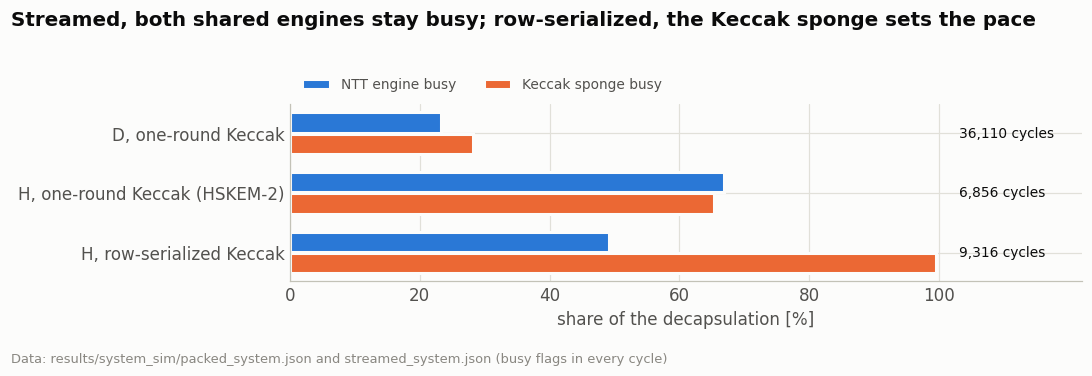

the row-serialized Keccak lengthens a decapsulation by 3.9% in the original design and by 35.9% in the streamed system


In [34]:
pD, pH, pHa = cs["sram_only_sysBCD"]["profile"], sc["sram_only_strH"]["profile"], sc["asic_strH"]["profile"]
UT = [("D, one-round Keccak", pD), ("H, one-round Keccak (HSKEM-2)", pH), ("H, row-serialized Keccak", pHa)]
fig, ax = plt.subplots(figsize=(10, 3.0))
for k, (name, p) in enumerate(UT):
    ax.barh(k - 0.18, 100 * p["ntt_busy"] / p["cycles"], height=0.34, label="NTT engine busy" if k == 0 else None,
            **ps.bar_kw(ps.SERIES[0]))
    ax.barh(k + 0.18, 100 * p["sponge_busy"] / p["cycles"], height=0.34, label="Keccak sponge busy" if k == 0 else None,
            **ps.bar_kw(ps.SERIES[1]))
    ax.annotate(f"{p['cycles']:,} cycles", (103, k), va="center", fontsize=9, color=ps.INK)
ax.set_yticks(range(len(UT)), [n for n, _ in UT]); ax.invert_yaxis(); ax.set_xlim(0, 122)
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel("share of the decapsulation [%]")
ax.legend(ncols=2, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9)
ps.finish(fig, title="Streamed, both shared engines stay busy; row-serialized, the Keccak sponge sets the pace")
ps.source(fig, "results/system_sim/packed_system.json and streamed_system.json (busy flags in every cycle)")
ps.save_pdf(fig, "decaps_utilization"); plt.show()
serial_then = int(cfg.loc["asic", "decaps_cycles"]) / int(cfg.loc["sram_only", "decaps_cycles"])
serial_now = dc["H"]["asic"] / dc["H"]["sram_only"]
print(f"the row-serialized Keccak lengthens a decapsulation by {serial_then - 1:.1%} in the original design "
      f"and by {serial_now - 1:.1%} in the streamed system")
# guards for the statements made in the text below
assert 0.66 < pH["ntt_busy"] / pH["cycles"] < 0.68 and 0.65 < pH["sponge_busy"] / pH["cycles"] < 0.66
assert pHa["sponge_busy"] / pHa["cycles"] > 0.995
assert 0.035 < serial_then - 1 < 0.045 and 0.35 < serial_now - 1 < 0.37
assert pD["ntt_busy"] / pD["cycles"] < 0.3
assert abs(4 * 568 + 4 * 569 - 4550) < 10 and dse.loc[("ntt_packed2", 20.0)].cycles == 568   # "the eight transforms alone take about 4,550 cycles"

The NTT engine is now busy for two thirds of a decapsulation and the sponge for almost as long, and the
eight transforms alone take about 4,550 cycles: the shared engines, not the datapath, set the pace. With
the row-serialized Keccak the sponge is busy in more than 99.5 % of all cycles: the core that added only
3.9 % to a decapsulation of HSKEM-1 (on top of the single-port store) would now add 36 %. What a decision costs depends on everything around it, which is why HSKEM-2
returns to the one-round core. The timeline below shows the same change cycle by cycle: on a common scale the engines
of HSKEM-1 run one after the other with long gaps, while those of HSKEM-2 overlap.

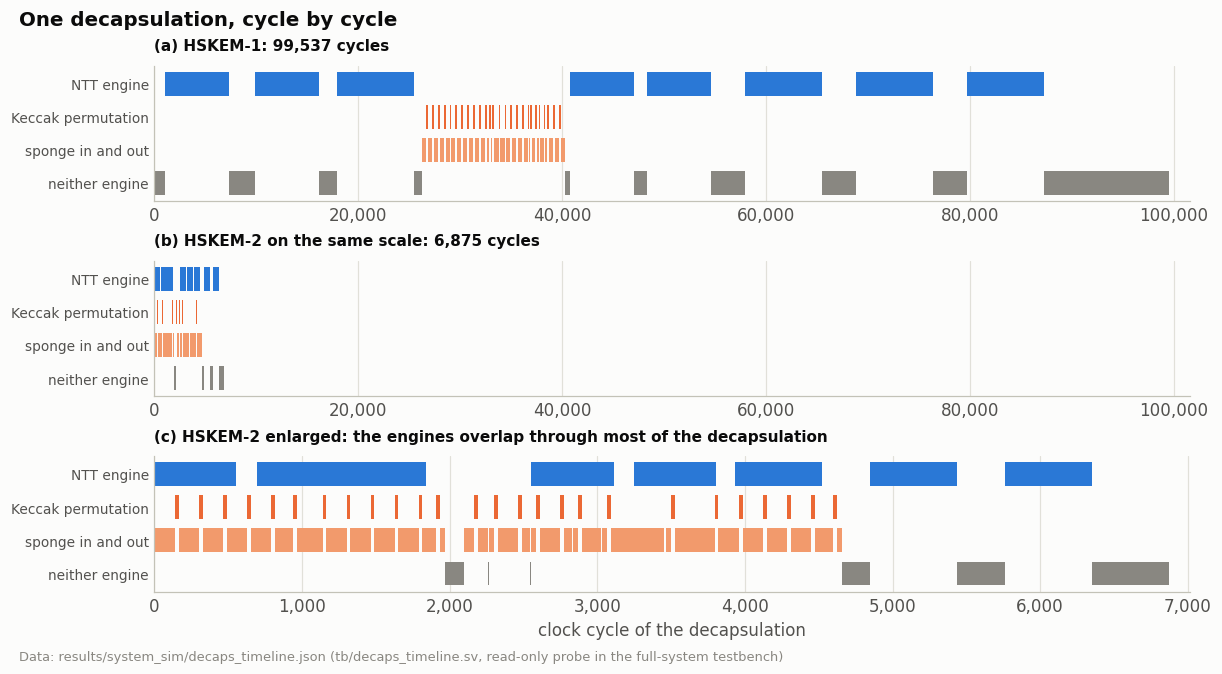

In [35]:
tl = json.loads((ROOT/"results/system_sim/decaps_timeline.json").read_text())
LANES = [("NTT engine", lambda r: r["ntt"], ps.NTT),
         ("Keccak permutation", lambda r: r["perm"], ps.KECCAK), ("sponge in and out", lambda r: r["sponge"] and not r["perm"], ps.KECCAK_ALT),
         ("neither engine", lambda r: not r["ntt"] and not r["sponge"], ps.OTHER)]
def lanes(ax, seg, end):
    for k, (name, on, c) in enumerate(LANES):
        spans = [(r["t"], (seg[i + 1]["t"] if i + 1 < len(seg) else end) - r["t"]) for i, r in enumerate(seg) if on(r)]
        ax.broken_barh(spans, (k - 0.36, 0.72), facecolor=c, edgecolor="none")
    ax.set_yticks(range(len(LANES)), [n for n, _, _ in LANES], fontsize=9); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
h1_, h2_ = tl["hskem1"], tl["hskem2"]
fig, axs = plt.subplots(3, 1, figsize=(11, 5.8), layout="constrained")
lanes(axs[0], h1_["segments"], h1_["cycles"]); axs[0].set_xlim(0, h1_["cycles"] * 1.02)
axs[0].set_title(f"(a) HSKEM-1: {h1_['cycles']:,} cycles", fontsize=10)
lanes(axs[1], h2_["segments"], h2_["cycles"]); axs[1].set_xlim(0, h1_["cycles"] * 1.02)
axs[1].set_title(f"(b) HSKEM-2 on the same scale: {h2_['cycles']:,} cycles", fontsize=10)
lanes(axs[2], h2_["segments"], h2_["cycles"]); axs[2].set_xlim(0, h2_["cycles"] * 1.02)
axs[2].set_title("(c) HSKEM-2 enlarged: the engines overlap through most of the decapsulation", fontsize=10)
for a_ in axs:
    ps.thousands(a_)
axs[2].set_xlabel("clock cycle of the decapsulation")
fig.suptitle("One decapsulation, cycle by cycle", x=0.01, ha="left", fontsize=13, fontweight="bold")
ps.source(fig, "results/system_sim/decaps_timeline.json (tb/decaps_timeline.sv, read-only probe in the full-system testbench)", y=-0.01)
ps.save_pdf(fig, "decaps_timeline"); plt.show()
assert h1_["cycles"] == psy_["published"] and h2_["cycles"] == 6875

## 9. HSKEM-2: the final design as a signed-off chip

HSKEM-2 builds the streamed system of Section 8, with its two-lane NTT and one-round Keccak, as a chip whose
core holds 18 OpenRAM macros of seven types. Its first layout met timing only at the typical corner. At the slow corner, multiplier
paths between flip-flops limited it to 13.9 MHz, and the paths that start at a macro failed as well,
because the macros deliver their read data only half a clock cycle after the clock edge, which leaves the
logic behind them the other half of the cycle.

The second layout therefore adds fourteen changes to the chip's RTL, each behind a compile-time switch that
only the chip uses and each registering such a read or shortening the logic behind it (Appendix C).
Together with the session-security changes described in Section 13 (Key custody), which cost no cycle, they
add 19 cycles per decapsulation and 3 % more flip-flops than the first layout and leave the shared keys
unchanged. This second layout, the signed-off chip, needs 17 % more standard-cell area than HSKEM-1
and meets setup and hold at the slow, typical and fast corners with the macros' clock-to-output times measured in
SPICE, which OpenRAM's views understate tenfold at the slow corner. Within the limits of Section 13 it passes LVS
and the KLayout DRC deck of SKY130, and its routed database is published (layout by cell class below; by block,
Appendix C.5).

The first figure shows what was built: the two shared engines, the three controllers, where each of the 18 macros sits
and which buses join them. The second opens one butterfly down to its operators.

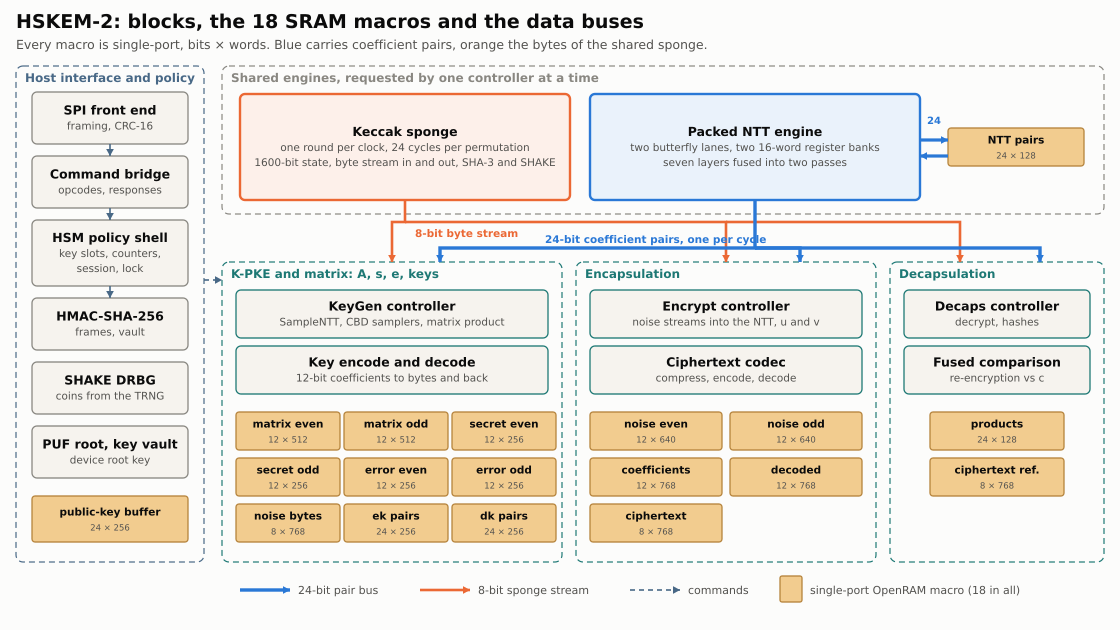

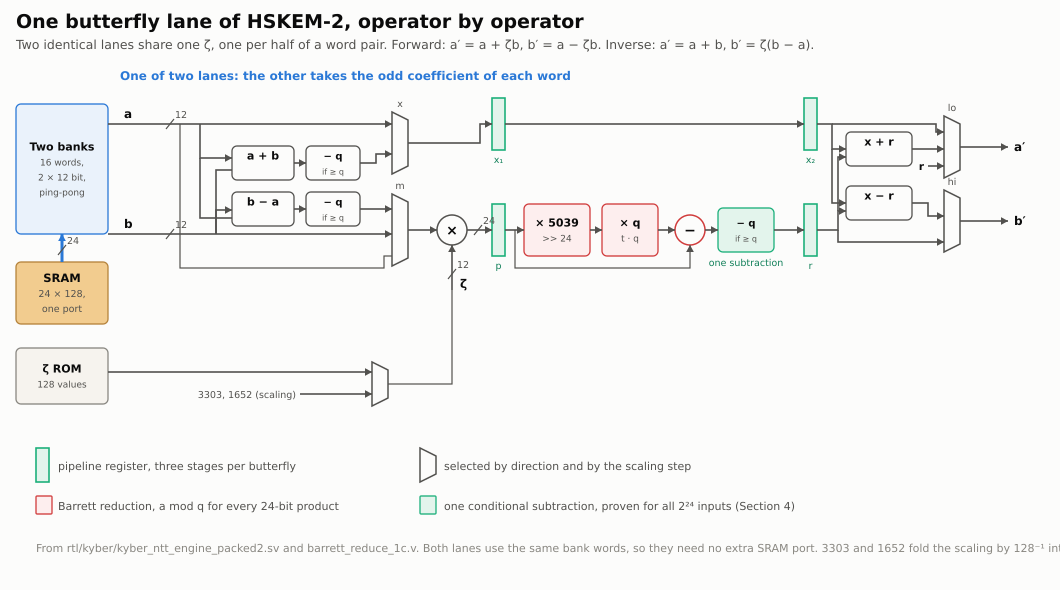

In [36]:
display(SVG(filename=str(ROOT/"figures/hskem2_datapath.svg")))
display(SVG(filename=str(ROOT/"figures/hskem2_butterfly.svg")))
assert (ROOT/"figures/hskem2_datapath.svg").read_text(encoding="utf-8").count('fill="#f2cc8f"') == 19   # 18 macros and the legend swatch

die area [mm²]                                                                      11.2314
std cells                                                                            360355
std-cell area [mm²]                                                                 2.37184
SRAM macros                                                                              18
SRAM area [mm²]                                                                     2.19064
flip-flops                                                                            30565
clock target [ns]                                                                      40.0
setup WNS, slow / typical / fast [ns]                               1.395 / 10.095 / 13.863
hold WNS, slow / typical / fast [ns]                                  0.541 / 0.254 / 0.094
fmax, slow / typical / fast [MHz]                                        26.9 / 50.5 / 81.5
router DRC / antenna violations                                                 

claim boundary: pre-silicon top-level integration LVS with 7 SRAM abstractions and independent transistor-level LVS for each SRAM; 6 multi-finger standard cells compared as black boxes after a switch-level truth-table proof of each


routed core,HSKEM-1,"HSKEM-2, first layout","HSKEM-2, signed off"
standard-cell area [mm²],2.03,2.38,2.37
standard cells,320615,361801,360355
flip-flops,28460,29774,30565
SRAM macro area [mm²],2.16,2.19,2.19
timing closed at the corners,typical (OpenRAM clock-to-output),typical (OpenRAM clock-to-output),"slow, typical, fast (SPICE clock-to-output)"
typical-corner fmax [MHz],"37.8 (flow estimate, OpenRAM view)","27.8 (flow estimate, OpenRAM view)","50.5 (period search, SPICE)"
decapsulation [cycles],99537,6856,6875
decapsulation at 25 MHz [µs],3981.5,274.2,275.0


HSKEM-2 signed off: 11.2 mm² die, 26.9 MHz at the slow corner (period search, Appendix C.1)


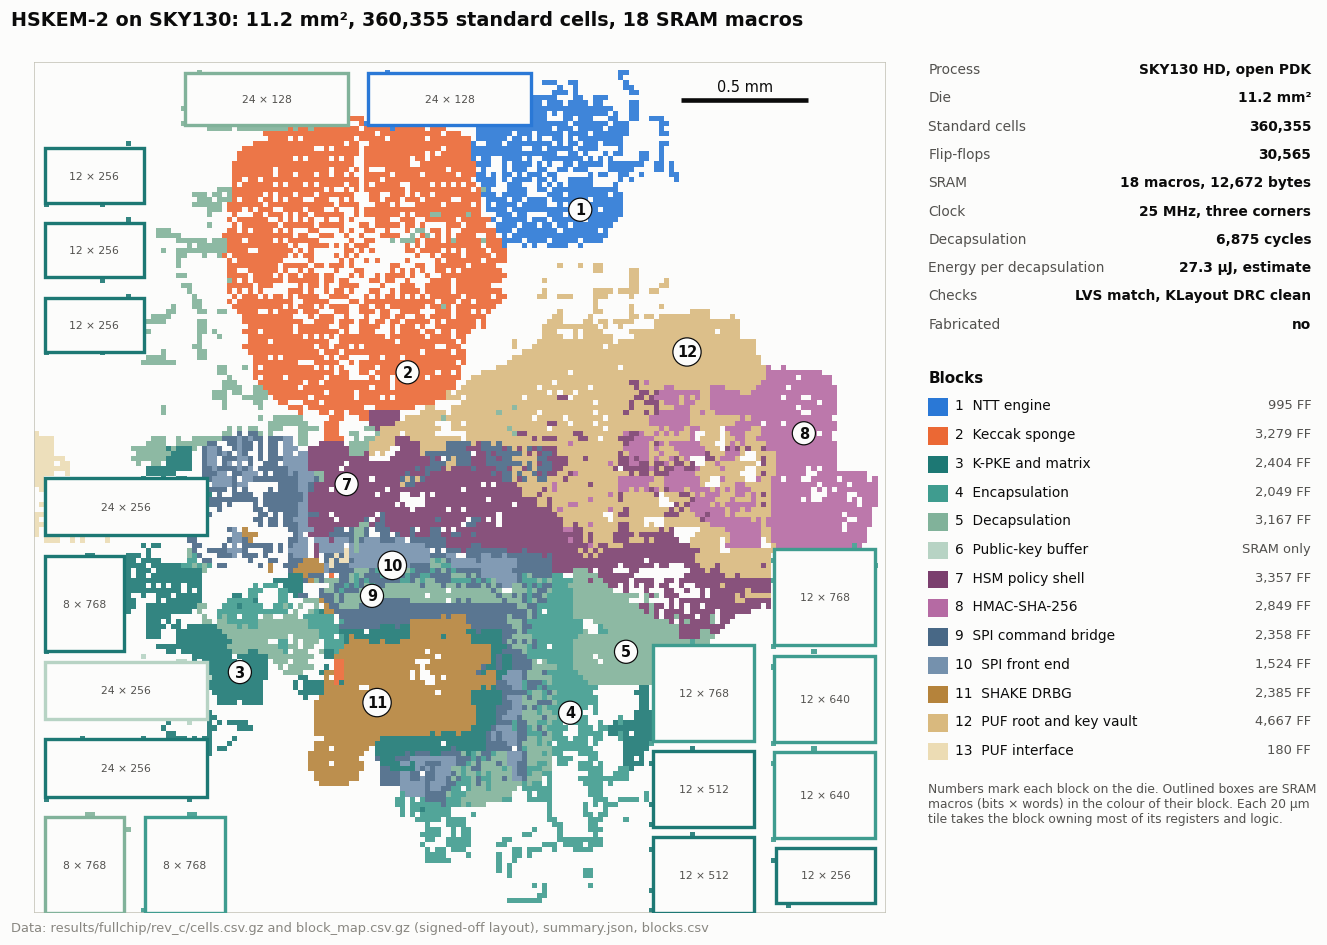

In [37]:
R9 = ROOT/"results/fullchip/rev_c"                    # HSKEM-2 revision C, the signed-off chip
fc = json.loads((R9/"summary.json").read_text()); sta9 = json.loads((R9/"sta_corners.json").read_text())
feol = json.loads((R9/"feol_drc.json").read_text())
m, s = fc["orfs_metrics"], fc["signoff"]
ss9, tt9, ff9 = (sta9["runs"][f"{c}_spice_soc"] for c in ("ss", "tt", "ff"))
display(pd.Series({
    "die area [mm²]": m["finish__design__die__area"]/1e6,
    "std cells": m["finish__design__instance__count__stdcell"],
    "std-cell area [mm²]": m["finish__design__instance__area__stdcell"]/1e6,
    "SRAM macros": m["finish__design__instance__count__macros"],
    "SRAM area [mm²]": m["finish__design__instance__area__macros"]/1e6,
    "flip-flops": m["finish__design__instance__count__class:sequential_cell"],
    "clock target [ns]": fc["clock_target_ns"],
    "setup WNS, slow / typical / fast [ns]": f'{ss9["setup_wns"]:.3f} / {tt9["setup_wns"]:.3f} / {ff9["setup_wns"]:.3f}',
    "hold WNS, slow / typical / fast [ns]": f'{ss9["hold_wns"]:.3f} / {tt9["hold_wns"]:.3f} / {ff9["hold_wns"]:.3f}',
    "fmax, slow / typical / fast [MHz]": " / ".join(f'{sta9["fmax_search"][c]["fmax_mhz"]:.1f}' for c in ("ss", "tt", "ff")),
    "router DRC / antenna violations": f'{s["router_drc_violations"]} / {s["antenna_violations"]}',
    "LVS (primary / repeat)": f'{s["primary_compare"]} / {s["repeat_compare"]}',
    "LVS negative control detected": s["negative_control_detected"],
    "DRC markers, BEOL + off-grid rules": s["drc_markers"],
    "DRC markers, FEOL rules (Appendix C.3)": feol["after_implant_fix"]["markers_total"],
}, name="HSKEM-2, signed-off layout"))
print("claim boundary:", s["claim_boundary"])
# HSKEM-1, HSKEM-2 revision A and revision C from their routed databases (ORFS final reports)
fc0 = json.loads((ROOT/"results/fullchip/first_chip/summary.json").read_text()); m0 = fc0["orfs_metrics"]
fcA = json.loads((ROOT/"results/fullchip/summary.json").read_text()); mA = fcA["orfs_metrics"]
chip_sim = (R9/"tb_trustedge_spi_rev_c.log").read_text(errors="replace")
cyc_b = int(re.search(r"U1 Decaps busy latency valid/implicit-rejection=(\d+) cycles", chip_sim)[1])
cyc_chip = {"HSKEM-1": psy_["published"], "HSKEM-2, first layout": ssy_["decaps_cycles"]["H"]["sram_only"], "HSKEM-2, signed off": cyc_b}
closed = {"HSKEM-1": "typical (OpenRAM clock-to-output)", "HSKEM-2, first layout": "typical (OpenRAM clock-to-output)",
          "HSKEM-2, signed off": "slow, typical, fast (SPICE clock-to-output)"}
fmx_ = {"HSKEM-1": f'{m0["finish__timing__fmax"] / 1e6:.1f} (flow estimate, OpenRAM view)',
        "HSKEM-2, first layout": f'{mA["finish__timing__fmax"] / 1e6:.1f} (flow estimate, OpenRAM view)',
        "HSKEM-2, signed off": f'{sta9["fmax_search"]["tt"]["fmax_mhz"]:.1f} (period search, SPICE)'}
chips_ = pd.DataFrame({k: [round(mm["finish__design__instance__area__stdcell"] / 1e6, 2), mm["finish__design__instance__count__stdcell"],
                           mm["finish__design__instance__count__class:sequential_cell"],
                           round(mm["finish__design__instance__area__macros"] / 1e6, 2), closed[k], fmx_[k],
                           cyc_chip[k], round(cyc_chip[k] * fc["clock_target_ns"] / 1e3, 1)]
                       for k, mm in (("HSKEM-1", m0), ("HSKEM-2, first layout", mA), ("HSKEM-2, signed off", m))},
                      index=["standard-cell area [mm²]", "standard cells", "flip-flops", "SRAM macro area [mm²]",
                             "timing closed at the corners", "typical-corner fmax [MHz]", "decapsulation [cycles]",
                             "decapsulation at 25 MHz [µs]"])
nbd.show(chips_.rename_axis("routed core"), index=True)
print(f"HSKEM-2 signed off: {m['finish__design__die__area'] / 1e6:.1f} mm² die, "
      f"{sta9['fmax_search']['ss']['fmax_mhz']:.1f} MHz at the slow corner (period search, Appendix C.1)")
assert fc0["clock_target_ns"] == fcA["clock_target_ns"] == fc["clock_target_ns"] == 40.0
assert 0.165 < m["finish__design__instance__area__stdcell"] / m0["finish__design__instance__area__stdcell"] - 1 < 0.175   # "17 % more"
assert cyc_b - cyc_chip["HSKEM-2, first layout"] == 19                                                     # "19 cycles"
assert 0.025 < m["finish__design__instance__count__class:sequential_cell"] / mA["finish__design__instance__count__class:sequential_cell"] - 1 < 0.035   # "3 % more flip-flops"
assert round(m0["finish__timing__fmax"] / 1e6, 1) == 37.8 and round(mA["finish__timing__fmax"] / 1e6, 1) == 27.8
rat_ = [sta9["macro_clk_to_dout_ns"]["ss"][k] / sta9["macro_clk_to_dout_view_ns"]["ss"][k] for k in sta9["macro_clk_to_dout_ns"]["ss"]]
assert 9.5 < min(rat_) and max(rat_) < 12.5                                                          # "tenfold at the slow corner"
assert round(100 * (cyc_b / 6668 - 1), 1) == 3.1 and 6856 / 6668 - 1 < 0.03                         # the comparison table of Section 12: 6,875 on the chip vs 6,668 [13]
assert round(json.loads((ROOT/"results/fullchip/sta_corners.json").read_text())["corners"]["ss_100C_1v60"]["ff2ff_fmax_mhz"], 1) == 13.9   # revision A
mbA = json.loads((ROOT/"results/fullchip/sta_macro_bound.json").read_text())["macro_arc_scale"]["x1"]
assert abs(mbA["ff2ff_setup_slack_ns"] - mbA["setup_wns"]) < 0.01 and mbA["setup_wns"] < mbA["macro_paths_slack_ns"]["from_macro_setup"] < 0   # flip-flop paths set it; macro paths fail too
assert min(ss9["setup_wns"], ss9["hold_wns"], tt9["setup_wns"], tt9["hold_wns"], ff9["setup_wns"], ff9["hold_wns"]) > 0
assert ss9["setup_violating_endpoints"] == ss9["hold_violating_endpoints"] == 0 and sta9["provisional_views"] == 0
assert (s["router_drc_violations"], s["antenna_violations"], s["drc_markers"]) == (0, 0, 0)
assert s["primary_compare"] == s["repeat_compare"] == "Circuits match uniquely" and s["negative_control_detected"]
# the abstract and Section 13 quote these figures
assert m["finish__design__instance__count__macros"] == 18 and s["sram_masters"] == 7
assert round(m["finish__design__instance__count__class:sequential_cell"], -2) == 30600                # "30,600 registers"
# revision C's RTL (published sources + the (chip) defines) in the full-system testbench: same keys as milestone H
h_sim = (ROOT/"results/system_sim/tb_trustedge_spi_sram_only_strH.log").read_text(errors="replace")
assert "TB_TRUSTEDGE_SPI_RESULT: ALL PASS" in chip_sim
assert set(re.findall(r"\bk=([0-9a-f]+)", chip_sim)) == set(re.findall(r"\bk=([0-9a-f]+)", h_sim))   # same shared keys
import placement_map as pm
from matplotlib.patches import Patch
fig = plt.figure(figsize=(12, 8.6))
ax = fig.add_axes([0.01, 0.02, 0.68, 0.9])
owners = pm.draw_blocks(ax, R9/"cells.csv.gz", R9/"block_map.csv.gz")
blk9 = pd.read_csv(R9/"blocks.csv")
assert owners == {r.block: r.sram_macros for r in blk9.itertuples() if r.sram_macros}    # macros agree with the netlist count
ps.scale_bar(ax, 500, "0.5 mm", frac=(0.76, 0.955))
sram_bytes = int(blk9.sram_bits.sum()) // 8
rows9 = [("Process", "SKY130 HD, open PDK"), ("Die", f"{m['finish__design__die__area'] / 1e6:.1f} mm²"),
         ("Standard cells", f"{m['finish__design__instance__count__stdcell']:,.0f}"),
         ("Flip-flops", f"{m['finish__design__instance__count__class:sequential_cell']:,.0f}"),
         ("SRAM", f"18 macros, {sram_bytes:,} bytes"), ("Clock", f"{1e3 / fc['clock_target_ns']:.0f} MHz, three corners"),
         ("Decapsulation", f"{cyc_b:,} cycles"), ("Energy per decapsulation", f"{e_tot:.1f} µJ, estimate"),
         ("Checks", "LVS match, KLayout DRC clean"), ("Fabricated", "no")]
tb = fig.add_axes([0.705, 0.04, 0.29, 0.88]); tb.axis("off"); tb.set_xlim(0, 1); tb.set_ylim(0, 1)
for i, (k_, v_) in enumerate(rows9):
    y_ = 1 - i * 0.034
    tb.text(0, y_, k_, fontsize=9, color=ps.INK_2, va="top")
    tb.text(1, y_, v_, fontsize=9, color=ps.INK, fontweight="bold", va="top", ha="right")
y_ = 1 - len(rows9) * 0.034 - 0.03
tb.text(0, y_, "Blocks", fontsize=10, fontweight="bold", va="top")
flops_ = dict(zip(blk9.block, blk9.flops))
for i, (b_, (name_, col_)) in enumerate(pm.BLOCK_STYLE.items()):
    y2_ = y_ - 0.034 - i * 0.0345
    tb.add_patch(plt.Rectangle((0, y2_ - 0.021), 0.05, 0.021, color=col_, ec="none"))
    tb.text(0.07, y2_, f"{i + 1}  {name_}", fontsize=9, color=ps.INK, va="top")
    tb.text(1, y2_, f"{flops_.get(b_, 0):,} FF" if flops_.get(b_, 0) else "SRAM only", fontsize=8.5, color=ps.INK_2, va="top", ha="right")
tb.text(0, y_ - 0.034 - len(pm.BLOCK_STYLE) * 0.0345 - 0.012, "Numbers mark each block on the die. Outlined boxes are SRAM\nmacros (bits × words) "
        "in the colour of their block. Each 20 µm\ntile takes the block owning most of its registers and logic.",
        fontsize=8, color=ps.INK_2, va="top")
fig.suptitle(f"HSKEM-2 on SKY130: {m['finish__design__die__area'] / 1e6:.1f} mm², "
             f"{m['finish__design__instance__count__stdcell']:,.0f} standard cells, 18 SRAM macros",
             x=0.01, ha="left", y=0.975, fontsize=12.5, fontweight="bold")
ps.source(fig, "results/fullchip/rev_c/cells.csv.gz and block_map.csv.gz (signed-off layout), summary.json, blocks.csv", y=0.012)
plt.show()

### Energy: almost thirteen times less per decapsulation

Both chips are priced alike. A shadow copy of the routed netlist takes its combinational cells from the layout
and the values of its flip-flops from the RTL simulation, and replays the profiled decapsulation on the
extracted parasitics (`scripts/fullchip_power.sh`); OpenSTA adds the clock network, and the SRAM macros are priced from their
transistor-level energies and access counts (Appendix C.4).

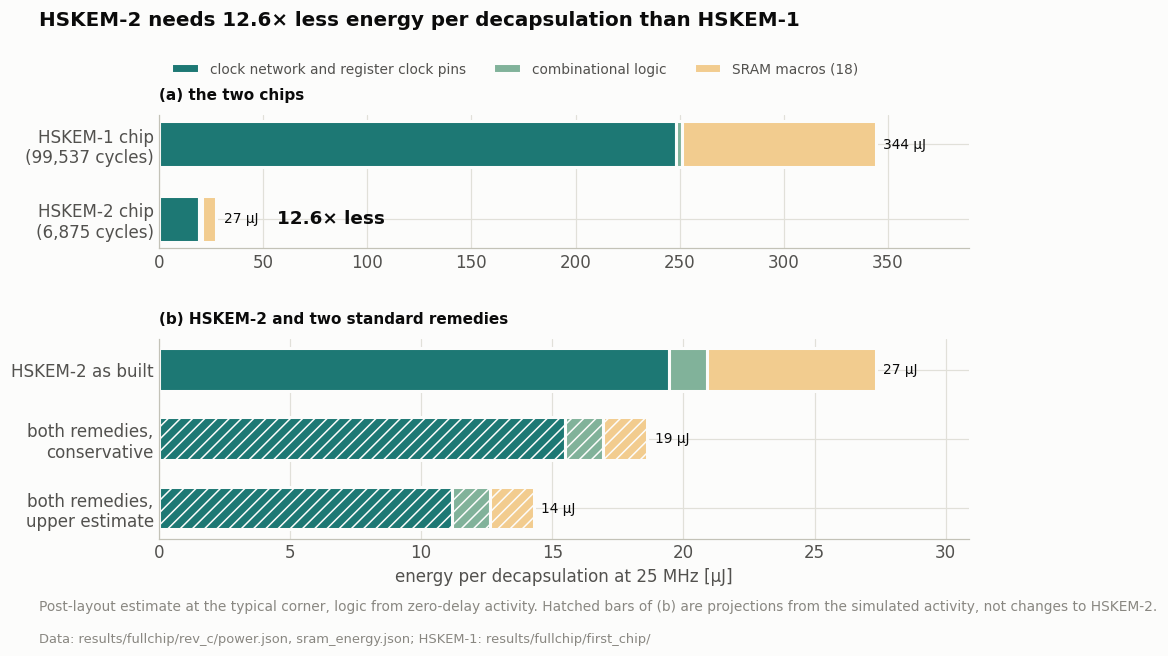

decapsulation: energy window of 6874 cycles (from the second busy cycle) at 40 ns; logic 76.0 mW, 726,672 pins annotated from the shadow, 128,288 left to OpenSTA's propagated defaults; SRAM accesses 122,468 as built, 22,109 useful; 17 of 18 macros with the chip select tied active


"per decapsulation, 25 MHz",HSKEM-1,HSKEM-2
decapsulation [cycles],99537.0,6875.0
logic [µJ],251.3,20.9
SRAM macros [µJ],92.8,6.4
total [µJ],344.1,27.3
mean power [mW],86.4,99.4


share of the decapsulation energy: clock network and register clock pins 71%, SRAM macros 24%, combinational logic 5%
remedies: gate the clock of the 5 blocks idle during a decapsulation (PUF root and key vault, PUF interface, HSM policy shell, HMAC, SHAKE DRBG; 13,438 flip-flops) and drive every chip select from the block's own requests, as HSKEM-2 does only for the NTT store; across all 18 macros this removes 74% of the SRAM energy; gating the clocks of the idle blocks saves 14.4 mW (conservative) to 30.1 mW (upper estimate) of the 68.1 mW in clock and registers, and both remedies together save 32 to 48 % of the energy of a decapsulation


In [38]:
pw = json.loads((R9/"power.json").read_text())                 # revision C
se = json.loads((R9/"sram_energy.json").read_text())
cg = json.loads((R9/"clock_gating_whatif.json").read_text())
sa = json.loads((R9/"sram_accesses.json").read_text())
t_dec = pw["window_cycles"] * pw["clock_ns"] * 1e-9                      # seconds
e = {k: v * 1e-3 * t_dec * 1e6 for k, v in pw["power_mw"].items()}         # uJ per decapsulation
sram = se["sram_energy_per_decaps_uj"]
gate = se["sram_energy_with_chip_select_gating_uj"]
saved_lo = cg["saved_by_gating_idle_blocks_mw"] * 1e-3 * t_dec * 1e6
saved_hi = cg["saved_upper_estimate_mw"] * 1e-3 * t_dec * 1e6
logic = sum(e.values())
# HSKEM-1, measured with the same method (original engines, 99,536-cycle window)
pw0 = json.loads((ROOT/"results/fullchip/first_chip/power.json").read_text())
se0 = json.loads((ROOT/"results/fullchip/first_chip/sram_energy.json").read_text())
t0 = pw0["window_cycles"] * pw0["clock_ns"] * 1e-9
e0 = {k: v * 1e-3 * t0 * 1e6 for k, v in pw0["power_mw"].items()}
logic0, sram0 = sum(e0.values()), se0["sram_energy_per_decaps_uj"]
seg = ["clock network and register clock pins", "combinational logic", "SRAM macros (18)"]
COL = [ps.REG, ps.LOGIC, ps.MEM]
chips = {"HSKEM-1 chip\n(99,537 cycles)": [e0["clock"] + e0["sequential"], e0["combinational"], sram0],
         f"HSKEM-2 chip\n({pw['window_cycles'] + 1:,} cycles)": [e["clock"] + e["sequential"], e["combinational"], sram]}
rows = {"HSKEM-2 as built": [e["clock"] + e["sequential"], e["combinational"], sram],
        "both remedies,\nconservative": [e["clock"] + e["sequential"] - saved_lo, e["combinational"], gate],
        "both remedies,\nupper estimate": [e["clock"] + e["sequential"] - saved_hi, e["combinational"], gate]}
fig, axes = plt.subplots(2, 1, figsize=(9.5, 5.0), gridspec_kw={"height_ratios": [2, 3], "hspace": 0.55})
for ax, data, tag in ((axes[0], chips, "(a) the two chips"), (axes[1], rows, "(b) HSKEM-2 and two standard remedies")):
    for k, vals in enumerate(data.values()):
        left = 0.0
        for j, v in enumerate(vals):
            ax.barh(k, v, left=left, height=0.62, label=seg[j] if (k == 0 and ax is axes[0]) else None,
                    hatch="///" if (ax is axes[1] and k > 0) else None, **ps.bar_kw(COL[j]))
            left += v
        ax.annotate(f"{left:.0f} µJ", (left, k), xytext=(5, 0), textcoords="offset points", va="center", fontsize=9)
    ax.set_yticks(range(len(data)), list(data)); ax.invert_yaxis()
    ax.set_xlim(0, 1.13 * max(sum(v) for v in data.values()))
    ax.set_title(tag, loc="left", fontsize=10)
axes[1].set_xlabel("energy per decapsulation at 25 MHz [µJ]")
tot_ = [sum(v) for v in chips.values()]
axes[0].annotate(f"{tot_[0] / tot_[1]:.1f}× less", (tot_[1], 1), xytext=(40, 0), textcoords="offset points",
                 va="center", fontsize=12, fontweight="bold", color=ps.INK)
axes[0].legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.2), frameon=False, fontsize=9)
import warnings
with warnings.catch_warnings():          # tight_layout cannot place the legend above (a); the layout is set by hand
    warnings.simplefilter("ignore", UserWarning)
    ps.finish(fig, title=f"HSKEM-2 needs {tot_[0] / tot_[1]:.1f}× less energy per decapsulation than HSKEM-1", y=1.07)
fig.text(0.01, -0.02, "Post-layout estimate at the typical corner, logic from zero-delay activity. Hatched bars of (b) are "
         "projections from the simulated activity, not changes to HSKEM-2.", fontsize=9, color=ps.MUTED)
ps.source(fig, "results/fullchip/rev_c/power.json, sram_energy.json; HSKEM-1: results/fullchip/first_chip/", y=-0.06)
ps.save_pdf(fig, "decaps_energy"); plt.show()
useful = sum(v["useful_accesses"] for v in sa["instances"].values())
built = sum(v["reads"] + v["writes"] for v in sa["instances"].values())
tied = [k for k, v in sa["instances"].items() if v["chip_select"] == "tied active"]
print(f"decapsulation: energy window of {pw['window_cycles']} cycles (from the second busy cycle) at {pw['clock_ns']:.0f} ns; "
      f"logic {pw['logic_power_mw']:.1f} mW, {pw['pins_annotated_from_vcd']:,} pins annotated from the shadow, "
      f"{pw['pins_unannotated']:,} left to OpenSTA's propagated defaults; SRAM accesses {built:,} as built, "
      f"{useful:,} useful; {len(tied)} of 18 macros with the chip select tied active")
cmp_ = pd.DataFrame({"HSKEM-1": [pw0["window_cycles"] + 1, logic0, sram0, logic0 + sram0, (logic0 + sram0) / t0 * 1e-3],
                     "HSKEM-2": [pw["window_cycles"] + 1, logic, sram, logic + sram, (logic + sram) / t_dec * 1e-3]},
                    index=["decapsulation [cycles]", "logic [µJ]", "SRAM macros [µJ]", "total [µJ]", "mean power [mW]"])
nbd.show(cmp_.round(1).rename_axis("per decapsulation, 25 MHz"), index=True)
# guards for the statements made in the text below
assert 0.90 < (e["clock"] + e["sequential"]) / logic < 0.95                   # "more than nine tenths is clock"
assert 0.76 < pw["registers_never_toggling"] / pw["registers_compared"] < 0.8  # "more than three quarters"
assert 26 < logic + sram < 27.5                                                # "about 27 µJ"
assert 0.22 < sram / (logic + sram) < 0.26                                     # "about a quarter"
assert 0.7 < 1 - gate / sram < 0.78                                            # "about three quarters"
assert 31.5 < 100 * (sram - gate + saved_lo) / (logic + sram) < 32.5           # "roughly 32 to 48 %"
assert 47.5 < 100 * (sram - gate + saved_hi) / (logic + sram) < 48.5
assert cg["idle_flip_flops"] == 13438
pct_lo, pct_hi = (100 * (sram - gate + x) / (logic + sram) for x in (saved_lo, saved_hi))
assert (round(pct_lo), round(pct_hi)) == (32, 48)                              # "32 to 48 %"
assert round(e_first / e_tot, 1) == 12.6                                         # "12.6×"
print(f"share of the decapsulation energy: clock network and register clock pins {(e_['clock'] + e_['sequential']) / e_tot:.0%}, "
      f"SRAM macros {e_['sram'] / e_tot:.0%}, combinational logic {e_['combinational'] / e_tot:.0%}")
print(f"remedies: gate the clock of the {len(cg['idle_blocks'])} blocks idle during a decapsulation (PUF root and key vault, "
      f"PUF interface, HSM policy shell, HMAC, SHAKE DRBG; {cg['idle_flip_flops']:,} flip-flops) and drive every chip select "
      f"from the block's own requests, as HSKEM-2 does only for the NTT store; across all 18 macros this removes "
      f"{1 - gate / sram:.0%} of the SRAM energy; gating the clocks of the idle blocks saves "
      f"{cg['saved_by_gating_idle_blocks_mw']:.1f} mW (conservative) to {cg['saved_upper_estimate_mw']:.1f} mW (upper estimate) "
      f"of the {cg['clock_and_register_power_mw']:.1f} mW in clock and registers, and both remedies together save "
      f"{pct_lo:.0f} to {pct_hi:.0f} % of the energy of a decapsulation")
assert useful / built < 0.2 and len(tied) == 17 and "u_shared_ntt.u_sram" not in tied   # "fewer than one in five"
assert cg["idle_blocks"] == ["g_qualification_puf_vault", "u_hsm_shell", "u_security_hmac", "u_c2_shake_drbg", "u_puf"]
assert 0.2 < cg["saved_fraction"] and cg["saved_upper_fraction"] < 0.5
assert 12.5 < (logic0 + sram0) / (logic + sram) < 13.4                         # "thirteen times less"
assert 1.13 < ((logic + sram) / t_dec) / ((logic0 + sram0) / t0) < 1.155       # "about a seventh higher"
assert abs(logic0 - pw0["logic_energy_per_decaps_uj"]) < 0.01 and abs(logic - pw["logic_energy_per_decaps_uj"]) < 0.01
assert round(logic0 + sram0) == 344                                            # "the 344 µJ of HSKEM-1"
assert round(100 * (e0["clock"] + e0["sequential"]) / logic0) == 99              # "99 % of HSKEM-1's logic power"
assert pw["vcd_time_stretch"] == pw0["vcd_time_stretch"] == 4                    # activity read at the chip's 40 ns clock
un_ = {k: p["pins_unannotated"] / (p["pins_unannotated"] + p["pins_annotated_from_vcd"]) for k, p in (("HSKEM-2", pw), ("HSKEM-1", pw0))}
assert round(100 * un_["HSKEM-2"]) == 15 and round(100 * un_["HSKEM-1"]) == 18                 # Section 13: "15 % to 18 %"

HSKEM-2 spends about 27 µJ per decapsulation at 25 MHz, almost thirteen times (12.6×) less than the 344 µJ of HSKEM-1
(panel a). It finishes 14.5 times sooner, while its mean power is about a seventh higher because
more logic works every cycle. The energy thus tracks the cycle count, because on HSKEM-1 the clock
network and the registers drew 99 % of the logic power whether or not they computed.

Clocking also dominates HSKEM-2 (panel b). More than nine tenths of the logic's energy goes into the clock
network and the clock pins of the 30,600 registers, more than three quarters of which never change during
the operation. The SRAM macros add about a quarter, because 17 of the 18 keep their chip selects tied active
although fewer than one access in five does useful work. Gating the clocks of idle blocks and driving every
chip select from its block's requests would save a projected 32 to 48 % of the energy.

# Part III — Does it hold up?

The last part leaves the simulator: the same RTL runs on the FPGA board, and a modelled side-channel
adversary watches its power.

## 10. The same RTL on the FPGA board

The board answers whether the RTL works on hardware, whether the HSM's security rules hold there, and whether the
redesigned systems take the predicted cycles; HSKEM-1's ASIC choices exist only in simulation and layout. At
50 MHz, driven by the ESP32 over SPI, the board executed the complete ML-KEM exchange 100 times, playing both parties in turn, from key
generation and encapsulation to an independent decapsulation that must reproduce the shared secret. The
board's 16-bit cycle counters saturate at 65,535, so the decapsulation count is only a lower bound here. Key generation and encapsulation vary by a few dozen cycles, and the variation reveals
nothing secret, because it comes only from rejection sampling (discarding out-of-range values) of the public matrix, which is
generated from the **public** seed ρ. A run lasts 8.6 s because of the slow
host link (Appendix D.2).

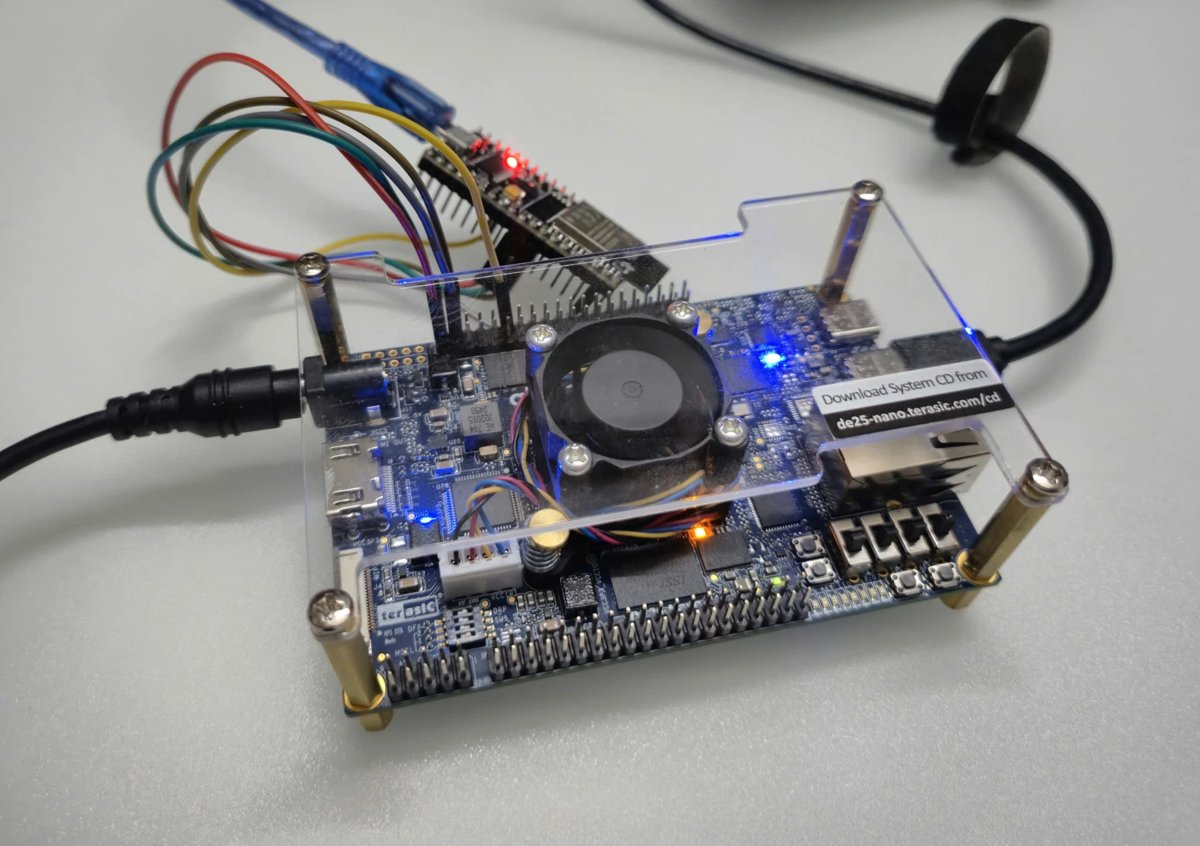

In [39]:
display(Image(str(ROOT/"results/fpga/board_setup.jpg"), width=620))

*The DE25-Nano board (Altera Agilex 5) hosts HSKEM; the ESP32 at the rear, the untrusted host, drives it
over SPI jumper wires.*

In [40]:
fr = json.loads((ROOT/"results/fpga/fpga_resources.json").read_text())     # resources: Appendix D.1
assert fr["device_total_alms"].startswith("39,")       # Section 1: "about 39,000 ALMs"
b = pd.read_csv(ROOT/"results/fpga/c3_repeat.csv")
F_CLK = 50e6
assert b.result_pass.all(), "a two-role ML-KEM run failed"
phases = ["keygen", "encaps", "ciphertext_final", "decaps"]
st = pd.DataFrame({p: {"min": b[f"{p}_cycles"].min(), "median": b[f"{p}_cycles"].median(),
                       "max": b[f"{p}_cycles"].max(),
                       "saturated": int((b[f"{p}_cycles"] >= 65535).sum())} for p in phases}).T
st["core_time_ms (at median)"] = st["median"] / F_CLK * 1e3
st["note"] = ["counter saturated: lower bound only" if s else "" for s in st["saturated"]]
display(st)
core_ms = st.loc[["keygen","encaps","ciphertext_final","decaps"], "median"].sum() / F_CLK * 1e3
e2e_ms = b.esp32_latency_us.median() / 1e3
assert round(e2e_ms / 1e3, 1) == 8.6                                              # "an 8.6 s run"
print(f"runs: {len(b)}  all PASS: {bool(b.result_pass.all())}  shared-secret match in every run")
print(f"end-to-end time of one complete exchange seen by the ESP32: median {e2e_ms:.1f} ms  (min {b.esp32_latency_us.min()/1e3:.1f}, max {b.esp32_latency_us.max()/1e3:.1f})")
print(f"FPGA core time (lower bound, decaps saturated): {core_ms:.2f} ms  ->  {100*core_ms/e2e_ms:.3f} % of the end-to-end time")
# guards for the statements made in the text above
assert core_ms / e2e_ms < 0.01, "the core no longer accounts for well under one percent"

# effective throughput of the host link: payload bytes moved per run (public key and ciphertext,
# each exported and imported once) over the end-to-end time, read from the raw log of every run
raw = (ROOT/"results/fpga/c3_repeat_raw.log").read_text()
moved = [sum(int(x) for x in re.findall(r"C3_(?:PUBLIC_KEY|CIPHERTEXT)_(?:EXPORT|IMPORT): PASS chunks=\d+ bytes=(\d+)", run))
         for run in raw.split("### run ")[1:]]
assert len(moved) == len(b) and set(moved) == {3136}
tput = 3136 / (b.esp32_latency_us / 1e6)
print(f"payload over the host link: 3,136 bytes per run; effective throughput median {tput.median():.0f} B/s "
      f"(range {tput.min():.1f}-{tput.max():.1f}); end-to-end spread {b.esp32_latency_us.max() - b.esp32_latency_us.min():.0f} us")
assert 300 < tput.median() < 450 and b.esp32_latency_us.max() - b.esp32_latency_us.min() < 1000

,min,median,max,saturated runs,core time at median [ms],note
key generation,35640,35655,35670,0,0.7131,
encapsulation,56157,56171,56188,0,1.1234,
ciphertext finalization,6148,6148,6148,0,0.1230,
decapsulation,65535,65535,65535,100,1.3107,counter saturated: lower bound only


runs: 100  all PASS: True  shared-secret match in every run
end-to-end time of one complete exchange seen by the ESP32: median 8625.3 ms  (min 8625.0, max 8625.7)
FPGA core time (lower bound, decaps saturated): 3.27 ms  ->  0.038 % of the end-to-end time
payload over the host link: 3,136 bytes per run; effective throughput median 364 B/s (range 363.6-363.6); end-to-end spread 628 us


**HSM security rules.** The board also ran the HSM's message protection 100 times in a banking
scenario: in a fresh ML-KEM session a genuine frame (one protected message) is accepted, an altered amount and a replayed frame are
rejected, and after a zeroize command, which erases the keys, every frame is refused. This is a regression
test on one board, not a security evaluation.

In [41]:
bank = pd.read_csv(ROOT/"results/fpga/bank_repeat.csv")
marks = [c for c in bank.columns if c.startswith("bank_")]
summary = pd.DataFrame({k: bank[k].value_counts() for k in marks}).fillna(0).astype(int).T
display(summary)
print("runs:", len(bank), " duplicate debits:", int(bank.duplicate_debit.sum()),
      " runs with any FAIL/failed text:", int(bank.any_fail_text.sum()))
assert (bank[marks] == "PASS").all().all() and bank.duplicate_debit.sum() == 0

,runs passed
ML-KEM session established,100
authenticated frame prepared,100
altered amount rejected,100
genuine frame accepted,100
replayed frame rejected,100
zeroize executed,100
frame after zeroize refused,100
complete scenario,100


runs: 100  duplicate debits: 0  runs with any FAIL/failed text: 0


**The redesigned systems on the board.** Step D and the streamed system of Section 8 were compiled from the
same source edits as the simulations, the streamed one with the session-security changes. Both close
timing at 50 MHz; step D passes five complete exchanges, the streamed system a hundred. Their
decapsulation counters read 36,112 and 6,858 cycles in every run, the simulated counts plus two hand-over
cycles in which the start request and the returned done signal cross between the blocks. On hardware, the
redesign therefore takes the predicted count to within those two cycles (Appendix D.3).

In [42]:
pb = pd.read_csv(ROOT/"results/fpga/packed_c3_repeat.csv")
pkb = json.loads((ROOT/"results/fpga/packed_build.json").read_text())
assert round(20 - 1000 / pkb["fmax_clock1_50_mhz"], 2) == 1.75   # Appendix D.3: step D's setup slack at 50 MHz
sim_fcd = json.loads((ROOT/"results/system_sim/packed_system.json").read_text())["configs"]["fpga_sysFCD"]
display(pb[["run", "result_pass", "keygen_cycles", "encaps_cycles", "ciphertext_final_cycles", "decaps_cycles"]])
alm = [float(x["alms_needed"].split()[0]) for x in (fr["kyber_ntt_engine (u_shared_ntt)"],
                                                     pkb["kyber_ntt_engine_packed (u_shared_ntt)"])]
print(f"bitstream {pkb['sof_sha256'][:16]}… (not published), Fmax {pkb['fmax_clock1_50_mhz']} MHz; "
      f"NTT engine {alm[0]:.0f} -> {alm[1]:.0f} ALMs")
# guards for the statements made in the text above and in Appendix D.3
assert pb.result_pass.all() and len(pb) == 5
assert (pb.decaps_cycles == 36112).all()                                  # equal in every run
assert pb.decaps_cycles.iloc[0] == sim_fcd["decaps_cycles_valid_and_rejected"] + 2
assert pkb["fmax_clock1_50_mhz"] > 50 and 2.2 < alm[1] / alm[0] < 2.6

run,passed,key generation [cycles],encapsulation [cycles],ciphertext finalization [cycles],decapsulation cycles
0,1,21689,32163,5380,36112
1,1,21667,32176,5380,36112
2,1,21692,32187,5380,36112
3,1,21677,32183,5380,36112
4,1,21683,32165,5380,36112


bitstream 67066b54dd71b7bb… (not published), Fmax 54.8 MHz; NTT engine 375 -> 900 ALMs


In [43]:
fb = pd.read_csv(ROOT/"results/fpga/revc_c3_repeat.csv")
ib = pd.read_csv(ROOT/"results/fpga/maxopt_c3_repeat.csv")
fbj = json.loads((ROOT/"results/fpga/revc_build.json").read_text())
display(fb[["result_pass", "keygen_cycles", "encaps_cycles", "ciphertext_final_cycles", "decaps_cycles"]]
        .agg(["min", "max"]).rename_axis(f"{len(fb)} board runs"))
alm_tot = int(fbj["alms"].split()[0].replace(",", ""))
alm_ntt = float(fbj["entities_alms_needed"]["kyber_ntt_engine_packed2 (u_shared_ntt)"]["alms_needed"])
print(f"bitstream {fbj['sof_sha256'][:16]}… (not published), Fmax {fbj['fmax_mhz']} MHz, "
      f"setup slack {fbj['clock1_50_setup_slack_ns']} ns; {alm_tot:,} ALMs, two-lane NTT engine {alm_ntt:.0f} ALMs")
# guards for the statements made in Section 10 and Appendix D.3
assert fb.result_pass.all() and len(fb) == 100 and ib.result_pass.all() and len(ib) == 5
assert (fb.decaps_cycles == dc["H"]["fpga"] + 2).all() and (ib.decaps_cycles == 13098).all()
assert 32000 < pb.encaps_cycles.median() < 32400 and 7150 < fb.encaps_cycles.median() < 7250
assert (pb.ciphertext_final_cycles == 5380).all() and (fb.ciphertext_final_cycles == 908).all()
assert 3400 < alm_tot - int(fr["device_total_alms"].split()[0].replace(",", "")) < 3500 and fbj["alms"].endswith("(91 %)")
assert fbj["fmax_mhz"] > 50 and abs(fbj["clock1_50_setup_slack_ns"] - 0.43) < 0.01
mf_ = pd.read_csv(ROOT/"results/fpga/maxopt_final_c3_repeat.csv")
assert len(mf_) == 5 and mf_.result_pass.all() and (mf_.decaps_cycles == 6858).all()        # D.3: "the same 6,858 cycles in five runs"
slog_ = (ROOT/"results/fpga/revc_session_c4.log").read_text(errors="replace")
assert "HSM4D1_RESTORE: FAIL" in slog_ and "C5_FULL_INTEGRATED_RESULT: FAIL" in slog_       # D.3: the failed PUF and vault restore

100 board runs,passed,key generation [cycles],encapsulation [cycles],ciphertext finalization [cycles],decapsulation cycles
min,1,19984,7197,908,6858
max,1,20015,7227,908,6858


bitstream 473e864aa4988d5a… (not published), Fmax 51.1 MHz, setup slack 0.43 ns; 42,547 ALMs, two-lane NTT engine 1945 ALMs


## 11. What is not yet protected: a simulated leakage assessment

Sections 4 and 8 found no secret-dependent cycle count, so this section turns to power.

* **What is measured.** `tb/tb_ntt_leak.sv` records for every cycle of a forward NTT how many bits of the
  datapath registers change, the standard register-transition stand-in for power, with Gaussian noise of
  four bit flips (σ) added.
* **How it is tested.** `golden/leakage.py` applies the fixed-versus-random Test Vector Leakage Assessment
  (TVLA) [6]: Welch's t-test compares, cycle by cycle, traces of a fixed secret polynomial with traces of
  fresh random ones, and $|t| > 4.5$ marks a detectable data dependence. A negative control, two halves of
  the random set, must stay below it.
* **What it can show.** This model covers the logic's registers, not an SRAM macro's interior, and locates
  data-dependent activity rather than predicting how many traces an attack needs.

**A first-order countermeasure.** Such a countermeasure defeats attacks that exploit one intermediate value
at a time. Because the NTT is linear, it can be protected without changing the
hardware [7]: the secret $a$ is split into the shares $a - m$ and a fresh uniform mask $m$, each share is
transformed separately, and the results add up to $\mathrm{NTT}(a)$. Each share alone is uniformly
random, so neither transform should reveal $a$, and the TVLA treats the two transforms as one trace.

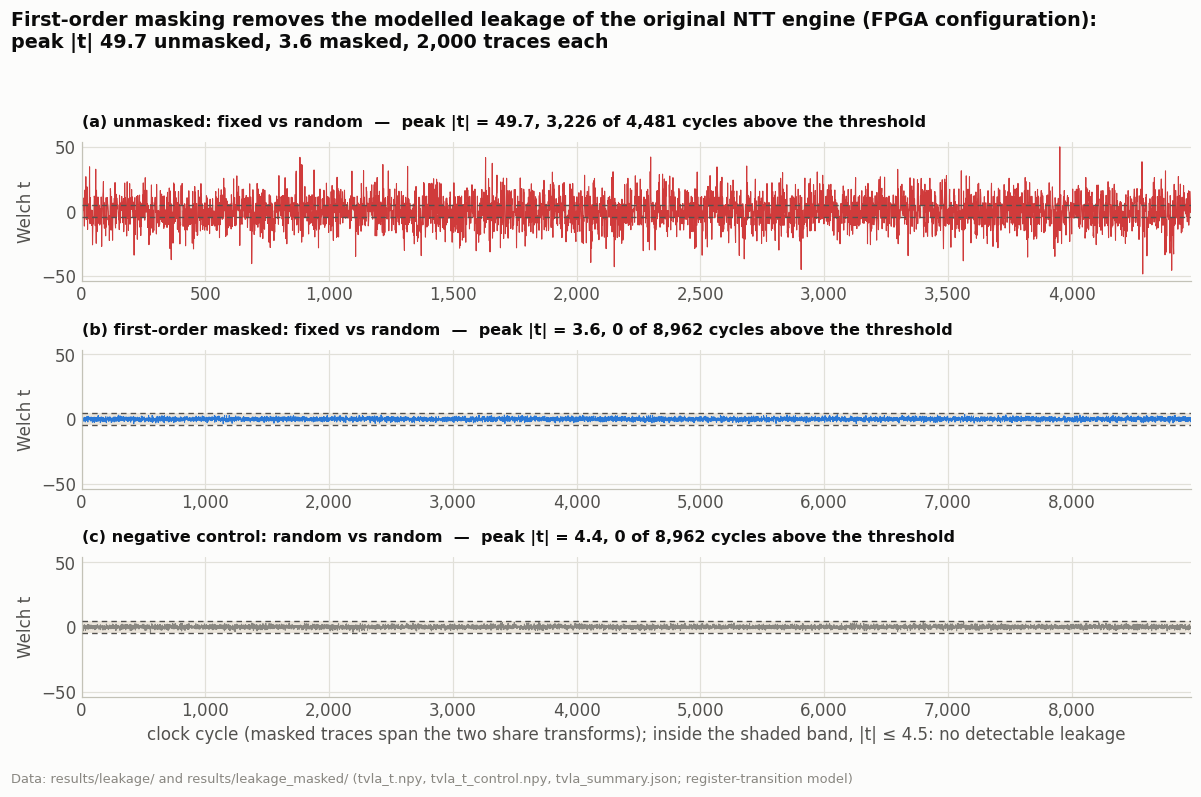

,traces,cycles,peak |t|,cycles with |t| > 4.5,share of cycles with |t| > 4.5,negative control: peak |t|,negative control: cycles with |t| > 4.5
unmasked,2000,4481,49.7495,3226,0.7199,3.4338,0
first-order masked,2000,8962,3.6362,0,0.0000,4.3507,0
"unmasked, HSKEM-1 engine",2000,6273,44.1727,3259,0.5195,4.4953,0
"first-order masked, HSKEM-1 engine",2000,12546,4.1766,0,0.0000,3.9590,0
"unmasked, packed engine",2000,987,65.8776,805,0.8156,3.5991,0
"first-order masked, packed engine",2000,1974,3.7052,0,0.0000,3.8296,0
"unmasked, two-lane engine (HSKEM-2)",2000,567,88.2293,436,0.7690,3.0213,0
"first-order masked, two-lane engine (HSKEM-2)",2000,1134,3.1899,0,0.0000,3.5088,0


In [44]:
LEAK_N = 400        # traces per experiment when re-run in Colab; the committed results use 2,000
if IN_COLAB:
    sh(f"bash scripts/run_leakage.sh {LEAK_N} 4.0 plain")
    sh(f"bash scripts/run_leakage.sh {LEAK_N} 4.0 masked")
summ, series = {}, []
for name, d in [("unmasked", "leakage"), ("first-order masked", "leakage_masked")]:
    summ[name] = json.loads((ROOT/"results"/d/"tvla_summary.json").read_text())
    series.append((f"{name}: fixed vs random", np.load(ROOT/"results"/d/"tvla_t.npy"), ps.CRITICAL if name == "unmasked" else ps.NTT))
series.append(("negative control: random vs random", np.load(ROOT/"results/leakage_masked/tvla_t_control.npy"), ps.MUTED))

ylim = max(np.abs(s[1]).max() for s in series) * 1.08
fig, axes = plt.subplots(3, 1, figsize=(11, 6.6), sharey=True)
for ax, tag, (title, t, colour) in zip(axes, "abc", series):
    ax.axhspan(-4.5, 4.5, color=ps.BAND, alpha=1.0, zorder=0, lw=0)  # the "no detectable leakage" band
    ax.plot(t, lw=0.7, color=colour, zorder=2)
    for y in (4.5, -4.5):                           # thresholds stay visible above the trace
        ax.axhline(y, color=ps.INK_2, lw=0.9, ls=(0, (4, 3)), zorder=3)
    ax.set_ylim(-ylim, ylim); ax.set_xlim(0, len(t)); ax.set_ylabel("Welch t"); ps.thousands(ax)
    over = int((np.abs(t) > 4.5).sum())
    ax.set_title(f"({tag}) {title}  —  peak |t| = {np.abs(t).max():.1f}, {over:,} of {len(t):,} cycles above the threshold",
                 fontsize=10.5, loc="left")
axes[-1].set_xlabel("clock cycle (masked traces span the two share transforms); "
                    "inside the shaded band, |t| ≤ 4.5: no detectable leakage")
fig.suptitle(f"First-order masking removes the modelled leakage of the original NTT engine (FPGA configuration):\n"
             f"peak |t| {summ['unmasked']['max_abs_t']:.1f} unmasked, {summ['first-order masked']['max_abs_t']:.1f} masked, "
             f"{summ['unmasked']['traces']:,} traces each", x=0.01, ha="left", y=1.035, fontsize=12.5, fontweight="bold")
fig.tight_layout()
ps.source(fig, "results/leakage/ and results/leakage_masked/ (tvla_t.npy, tvla_t_control.npy, tvla_summary.json; "
              "register-transition model)")
plt.show()
S = pd.DataFrame(summ).T[["traces", "runs_per_trace", "max_abs_t", "cycles_over_4p5",
                          "fraction_over_4p5", "control_max_abs_t", "control_cycles_over_4p5"]]
assert (S.control_cycles_over_4p5 == 0).all(), "negative control failed"
assert S.loc["unmasked", "cycles_over_4p5"] > 0 and S.loc["first-order masked", "cycles_over_4p5"] == 0
assert summ["first-order masked"]["cycles"] == 2 * summ["unmasked"]["cycles"]   # "twice the transform time"
# the same assessment of the ASIC configuration (single-port store), 2000 traces, committed results only
for name, d in [("unmasked, HSKEM-1 engine", "leakage_asic"), ("first-order masked, HSKEM-1 engine", "leakage_masked_asic"),
                ("unmasked, packed engine", "leakage_packed"), ("first-order masked, packed engine", "leakage_masked_packed"),
                ("unmasked, two-lane engine (HSKEM-2)", "leakage_packed2"), ("first-order masked, two-lane engine (HSKEM-2)", "leakage_masked_packed2")]:
    f = ROOT/"results"/d/"tvla_summary.json"
    if f.exists():
        summ[name] = json.loads(f.read_text())
S = pd.DataFrame(summ).T[["traces", "cycles", "max_abs_t", "cycles_over_4p5", "fraction_over_4p5",
                          "control_max_abs_t", "control_cycles_over_4p5"]]
assert (S.control_cycles_over_4p5 == 0).all(), "negative control failed"
assert S.loc["unmasked, HSKEM-1 engine", "cycles_over_4p5"] > 0                  # "leaks as well"
assert S.loc["first-order masked, HSKEM-1 engine", "cycles_over_4p5"] == 0       # "and masking removes it"
assert S.loc["unmasked, packed engine", "cycles_over_4p5"] > 0 and S.loc["first-order masked, packed engine", "cycles_over_4p5"] == 0
assert S.loc["unmasked, two-lane engine (HSKEM-2)", "cycles_over_4p5"] > 0 and S.loc["first-order masked, two-lane engine (HSKEM-2)", "cycles_over_4p5"] == 0
S

On the original engine, most cycles of an unmasked transform exceed the threshold, many by a wide margin
(panel a); with masking none does, and the peak $|t|$ stays at the level of the negative control (b, c), at
twice the transform time, mask generation not included. HSKEM-1's engine, the packed engine and the
two-lane engine of HSKEM-2 leak just as clearly unmasked, and masking again removes every crossing.
Because the shares are transformed in separate passes, the register-transition model predicts exactly this
outcome, and only within it. A first-order scheme still leaves second-order leakage: combining one cycle of
each pass can reveal a value that depends on $a$, and no second-order test was run.

**From registers to the routed netlist.** The register model leaves out the combinational logic and the
wiring, which dominate real switching. `scripts/run_leakage_gls.sh` therefore repeats the test on the routed
layout of HSKEM-2's NTT engine (Section 7), simulated at gate level without delays and without the macro's interior. For every cycle it
adds up the capacitance of all nets that switch and adds Gaussian noise of four toggles of the average net. The transform is run on 2,000 traces, with and without
the first-order masking above.

In [45]:
# switched capacitance per cycle: extracted wiring plus load pins (scripts/leak_cap_monitor.py); noise σ = 63,494 aF
gl = {k: json.loads((ROOT/"results"/d/"tvla_summary.json").read_text())
      for k, d in [("unmasked", "leakage_gls"), ("first-order masked", "leakage_gls_masked")]}
G = pd.DataFrame(gl).T[["traces", "cycles", "max_abs_t", "cycles_over_4p5", "fraction_over_4p5",
                        "control_max_abs_t", "control_cycles_over_4p5"]]
assert (G.control_cycles_over_4p5 == 0).all(), "negative control failed"
assert gl["unmasked"]["cycles_over_4p5"] > 0 and gl["first-order masked"]["cycles_over_4p5"] == 0
assert gl["unmasked"]["noise_sigma_af"] == gl["first-order masked"]["noise_sigma_af"] == 63494
assert gl["first-order masked"]["cycles"] == 2 * gl["unmasked"]["cycles"]
print(f"gate level: {gl['unmasked']['cycles_over_4p5']} of {gl['unmasked']['cycles']} cycles exceed |t| = 4.5 unmasked "
      f"(peak {gl['unmasked']['max_abs_t']:.1f}); masked, none of {gl['first-order masked']['cycles']} "
      f"(peak {gl['first-order masked']['max_abs_t']:.1f}, control {gl['first-order masked']['control_max_abs_t']:.1f})")
G

gate level: 492 of 567 cycles exceed |t| = 4.5 unmasked (peak 102.8); masked, none of 1134 (peak 3.3, control 3.1)


,traces,cycles,peak |t|,cycles with |t| > 4.5,share of cycles with |t| > 4.5,negative control: peak |t|,negative control: cycles with |t| > 4.5
unmasked,2000,567,102.80821333121627,492,0.8677248677248677,2.962132608031656,0
first-order masked,2000,1134,3.34890351222177,0,0.0,3.076297875785475,0


Unmasked, 492 of the 567 cycles exceed the threshold, so that the leak survives the combinational logic and
the wiring, which add switching but no protection. With masking, none of the 1,134 cycles does, and the peak
$|t|$ of 3.3 stays at the level of the negative control (3.1). The test models neither glitches nor measured power.

## 12. What transfers

This section draws lessons beyond HSKEM, places the numbers among published designs and
lists what looked right and was not.

In [46]:
P = pnr[pnr.clk_target_ns == 20].set_index("variant")   # the common 20 ns comparison point
def ratio(col, a, b): return P.loc[a, col] / P.loc[b, col]
F = pd.Series({
    "NTT dual/single: cell area":       ratio("cell_area_um2", "ntt_dp", "ntt_sp"),
    "NTT dual/single: latency":         ratio("latency_us_at_fmax", "ntt_dp", "ntt_sp"),
    "NTT dual/single: area x time":     ratio("at_product", "ntt_dp", "ntt_sp"),
    "Keccak serial/round: cell area":   ratio("cell_area_um2", "keccak_s7", "keccak_r1"),
    "Keccak serial/round: die area":    ratio("die_area_um2", "keccak_s7", "keccak_r1"),
    "Keccak serial/round: fmax":        ratio("fmax_mhz", "keccak_s7", "keccak_r1"),
    "Keccak serial/round: latency":     ratio("latency_us_at_fmax", "keccak_s7", "keccak_r1"),
    "Keccak serial/round: area x time": ratio("at_product", "keccak_s7", "keccak_r1"),
}).round(3)
assert F["NTT dual/single: latency"] < 1 < F["NTT dual/single: cell area"]
assert abs(F["NTT dual/single: area x time"] - 1) < 0.05
assert F["Keccak serial/round: cell area"] > 0.95 and 8.5 < F["Keccak serial/round: latency"] < 10  # "roughly nine times"
# every routed block-level layout, including the clock-sweep points, must be fully clean
assert (pnr.drc_errors == 0).all(), "a routed layout has DRC errors"
assert (pnr.antenna_violating_nets == 0).all(), "a routed layout has antenna violations"
# system level (Section 8): share of the decapsulation slowdown caused by each decision
sys_total = dec["both_delta"]
F["System: Decaps slowdown, both decisions"] = round(sys_total / int(cfg.loc["fpga", "decaps_cycles"]), 3)
F["System: share due to single-port store"] = round(dec["single_port_sram_delta"] / sys_total, 3)
F["System: share due to row-serial Keccak"] = round(dec["keccak_serial_delta"] / sys_total, 3)
assert F["System: share due to single-port store"] > 0.5 > F["System: share due to row-serial Keccak"]
assert dec["keccak_serial_delta"] / int(cfg.loc["fpga", "decaps_cycles"]) < 0.1   # "only a few percent"
assert 0.11 < pf.loc["fpga", "sponge_busy"] / pf.loc["fpga", "cycles"] < 0.14      # "about an eighth"
# design iteration (Section 7), post-route, final iteration vs the original single-port NTT
F["Iteration (routed): cell area"] = round(it.loc["ntt_opt_pipe_w12", "cell_area_um2"] / base_it.cell_area_um2, 3)
F["Iteration (routed): fmax"] = round(it.loc["ntt_opt_pipe_w12", "fmax_mhz"] / base_it.fmax_mhz, 3)
F["Iteration (routed): latency"] = round(it.loc["ntt_opt_pipe_w12", "latency_us_at_fmax"] / base_it.latency_us_at_fmax, 3)
F["Iteration (routed): area x time"] = round(it.loc["ntt_opt_pipe_w12", "at_product"] / base_it.at_product, 3)
assert F["Iteration (routed): cell area"] < 0.85 and F["Iteration (routed): latency"] < 0.75 \
       and F["Iteration (routed): fmax"] > 1.5 and F["Iteration (routed): area x time"] < 0.6
# the packed iteration (Sections 7 and 8)
F["Packed (routed): latency vs macro original"] = round(P.loc["ntt_packed", "latency_us_at_fmax"] / P.loc["ntt_macro", "latency_us_at_fmax"], 3)
F["Packed (routed): total area vs macro original"] = round(sum(total_area("ntt_packed_20ns")) / sum(total_area("ntt_macro_20ns")), 3)
F["Packed system (step D): decapsulation vs HSKEM-1"] = round(cyc_["sram_only_sysBCD"] / cyc_["asic_sysR"], 3)
F["HSKEM-2: decapsulation cycles vs HSKEM-1"] = round(dc["H"]["sram_only"] / cyc_["asic_sysR"], 3)
F["HSKEM-2: energy per decapsulation vs HSKEM-1"] = round(e_tot / e_first, 3)
assert 14 < 1 / F["HSKEM-2: decapsulation cycles vs HSKEM-1"] < 15 and 12.5 < 1 / F["HSKEM-2: energy per decapsulation vs HSKEM-1"] < 13.4
assert 1.35 < F["Packed (routed): total area vs macro original"] < 1.55     # "almost half more area"
assert F["Packed (routed): latency vs macro original"] < 1 / 8.5            # "nine times faster"
assert (round(P.loc["ntt_packed", "latency_us_at_fmax"]), round(P.loc["ntt_macro", "latency_us_at_fmax"])) == (14, 130)   # Section 7
assert 0.86 < 1 - acc_["ntt_packed"] / 6274 < 0.89                          # "removed most macro accesses"
print(f"original NTT after routing: dual-port store {P.loc['ntt_dp', 'fmax_mhz']:.1f} MHz, "
      f"single-port store {P.loc['ntt_sp', 'fmax_mhz']:.1f} MHz")
F

original NTT after routing: dual-port store 47.5 MHz, single-port store 49.8 MHz


NTT dual/single: cell area                          1.333
NTT dual/single: latency                            0.748
NTT dual/single: area x time                        0.997
Keccak serial/round: cell area                      0.986
Keccak serial/round: die area                       0.965
Keccak serial/round: fmax                           0.719
Keccak serial/round: latency                        9.405
Keccak serial/round: area x time                    9.272
System: Decaps slowdown, both decisions             0.222
System: share due to single-port store              0.793
System: share due to row-serial Keccak              0.207
Iteration (routed): cell area                       0.786
Iteration (routed): fmax                            1.658
Iteration (routed): latency                         0.689
Iteration (routed): area x time                     0.542
Packed (routed): latency vs macro original          0.111
Packed (routed): total area vs macro original       1.468
Packed system 

| Lesson | Where it showed | Section |
|:---|:---|:---:|
| **Price a block decision in the system, and again when the system changes.** | the serialized Keccak barely mattered to HSKEM-1 but would slow the streamed system by a third, while the cheaper single-port store set most of HSKEM-1's extra latency | 6, 8 |
| **Let each redesign answer a measurement.** | a proof and a routed critical path gave the first NTT iteration, the macro's share of a transform's energy the second, and the system profiles every step of the streamed datapath | 4, 7, 8 |
| **Feed the memory, not the multiplier.** | two coefficients per word removed most macro accesses and let one single-port macro do what published designs do with banks | 7 |
| **A faster engine pays only while the datapath keeps up.** | the packed NTT alone left the datapath as the bottleneck; only streaming it let the shared engines set the pace | 8 |
| **Clocking and integration set the energy of an open-source chip.** | most of HSKEM-2's energy clocks registers that do not change and macros selected in every cycle; two standard remedies would save a third to a half | 9 |
| **The unmasked NTT leaks; masking its input removes the modelled leakage without changing the engine.** | every engine tested leaks unmasked; first-order masking of the input removes the modelled leakage, in registers and on the routed netlist, at twice the transform time; mask generation and the rest of the datapath are not covered | 11 |
| **Obtain every important number twice.** | thirteen results that looked right were wrong, each exposed by an independent route (last table of this section) | 12 |

### Context: published Kyber hardware

The table compares HSKEM with the compact FPGA design of Xing and Li [13] and the Sapphire
crypto-processor [14]; platforms differ and Sapphire implements round-1 Kyber, so it gives orders of
magnitude, not a ranking. The last three rows are more recent.

In [47]:
fp_c = cfg.loc["fpga", "decaps_cycles"]
# the published figures are quoted from the cited papers; the HSKEM rows are read from this notebook's results
ctx = pd.DataFrame([
    {"design": "HSKEM, FPGA configuration (this work)", "platform": "Agilex 5 FPGA, 50 MHz",
     "cycles / NTT": int(sim.loc["ntt_dp", "cycles_measured"]), "cycles / decapsulation": f"{int(fp_c):,}",
     "resources": f"NTT engine: {fr['kyber_ntt_engine (u_shared_ntt)']['alms_needed'].split()[0]} ALMs, 1 M20K, 2 DSP"},
    {"design": "HSKEM, NTT redesign (this work)", "platform": f"SKY130, {P.loc['ntt_opt_pipe_w12', 'fmax_mhz']:.1f} MHz",
     "cycles / NTT": int(P.loc["ntt_opt_pipe_w12", "cycles"]), "cycles / decapsulation": "–",
     "resources": f"NTT block: {P.loc['ntt_opt_pipe_w12', 'cell_area_um2'] / 1e6:.3f} mm² (flip-flop store)"},
    {"design": "HSKEM, packed NTT (this work)", "platform": f"SKY130, {P.loc['ntt_packed', 'fmax_mhz']:.1f} MHz",
     "cycles / NTT": int(P.loc["ntt_packed", "cycles"]),
     "cycles / decapsulation": f"{cyc_['sram_only_sysBCD']:,} (RTL, Section 8)",
     "resources": "NTT block: {:.3f} mm² cells + {:.3f} mm² SRAM macro".format(*(a / 1e6 for a in total_area("ntt_packed_20ns")))},
    {"design": "HSKEM, streamed system (this work)", "platform": "Agilex 5 FPGA, 50 MHz",
     "cycles / NTT": int(re.search(r"NTT_RESULT .*?cycles_fwd=(\d+)", (ROOT/"results/sim_packed/packed2_x1.log").read_text())[1]),
     "cycles / decapsulation": f"{dc['H']['fpga']:,} (RTL), {int(fb.decaps_cycles.iloc[0]):,} (board)",
     "resources": f"two-lane NTT engine: {alm_ntt:.0f} ALMs, {fbj['entities_alms_needed']['kyber_ntt_engine_packed2 (u_shared_ntt)']['m20k']} M20K, "
                  f"{fbj['entities_alms_needed']['kyber_ntt_engine_packed2 (u_shared_ntt)']['dsp']} DSP"},
    {"design": "HSKEM-2, signed-off chip (this work)", "platform": f"SKY130, {1e3 / pw['clock_ns']:.0f} MHz",
     "cycles / NTT": f'{int(P.loc["ntt_packed2", "cycles"])} (block)', "cycles / decapsulation": f"{pw['window_cycles'] + 1:,}",
     "resources": f"complete HSM core: {m['finish__design__instance__area__stdcell'] / 1e6:.2f} mm² cells + "
                  f"{m['finish__design__instance__area__macros'] / 1e6:.2f} mm² SRAM"},
    {"design": "Xing and Li, TCHES 2021 [13]", "platform": "Artix-7 FPGA, 161 MHz",
     "cycles / NTT": 448, "cycles / decapsulation": "6,668 (k = 2)",
     "resources": "complete KEM, server configuration: 7,412 LUTs, 2 DSP, 3 BRAM"},
    {"design": "Sapphire, TCHES 2019 [14]", "platform": "TSMC 40 nm, 72 MHz",
     "cycles / NTT": 1289, "cycles / decapsulation": "142,309",
     "resources": "processor core: 0.28 mm², 5.69 mW (Kyber round 1, q = 7681)"},
    {"design": "Nguyen et al., TCAS-I 2025 [22]", "platform": "Artix-7 FPGA, 185 MHz",
     "cycles / NTT": "–", "cycles / decapsulation": "6.1k (k = 2)",
     "resources": "complete KEM, three security levels: 5,487 LUTs, 2 DSP, 3.5 BRAM"},
    {"design": "Fan et al., TVLSI 2026 [23]", "platform": "Artix-7 FPGA, 210 MHz",
     "cycles / NTT": "112", "cycles / decapsulation": "1,936 (k = 2)",
     "resources": "complete KEM, three security levels: 13.8k LUTs, 9.6k flip-flops"},
    {"design": "Nguyen et al., IEEE Access 2025 [24]", "platform": "180 nm CMOS",
     "cycles / NTT": "–", "cycles / decapsulation": "–",
     "resources": "three security levels: 3.47 mm² die, 7.37 kB SRAM"},
]).set_index("design")
# decapsulation time at each design's clock, energy where it is known, and the evidence behind each row
t_ = {"HSKEM, streamed system (this work)": int(fb.decaps_cycles.iloc[0]) / 50,
      "HSKEM-2, signed-off chip (this work)": (pw["window_cycles"] + 1) * pw["clock_ns"] / 1e3,
      "Xing and Li, TCHES 2021 [13]": 41.3, "Sapphire, TCHES 2019 [14]": 142309 / 72, "Fan et al., TVLSI 2026 [23]": 1936 / 210}   # [13]: 41.3 µs as published (Table 3)
ctx["decapsulation [µs]"] = [f"{t_[d]:,.1f}" if d in t_ else "–" for d in ctx.index]
ctx["energy / decapsulation"] = ["–"] * 4 + [f"{e_tot:.1f} µJ (estimated)", "not reported", "11.25 µJ", "not reported", "not reported",
                                            "6.4 µJ for KeyGen, encapsulation and decapsulation together"]
ctx["evidence"] = ["RTL simulation", "routed block", "routed block, RTL simulation", "RTL simulation, board",
                   "RTL and gate-level simulation, post-layout timing, energy from zero-delay activity", "published, FPGA", "published, silicon",
                   "published, FPGA", "published, FPGA; 18.9 µs for all three operations", "published, silicon"]
# guards for the comparison in the text below
assert int(P.loc["ntt_packed2", "cycles"]) < 1289 and round(int(P.loc["ntt_packed2", "cycles"]) / 448, 1) == 1.3   # "1.3 times the 448"
assert (round(t_["Xing and Li, TCHES 2021 [13]"]), round(t_["HSKEM, streamed system (this work)"]), round(t_["HSKEM-2, signed-off chip (this work)"])) == (41, 137, 275)
assert 3 < t_["HSKEM, streamed system (this work)"] / t_["Xing and Li, TCHES 2021 [13]"] < 3.5 and 6.5 < t_["HSKEM-2, signed-off chip (this work)"] / t_["Xing and Li, TCHES 2021 [13]"] < 7.5   # "under a third", "about a seventh"
assert 20.5 < 142309 / (pw["window_cycles"] + 1) < 20.9                 # "20.7 times fewer cycles" than Sapphire
assert 2.3 < e_tot / 11.25 < 2.5                                       # "about 2.4 times the energy"
chip_mm2 = (m["finish__design__instance__area__stdcell"] + m["finish__design__instance__area__macros"]) / 1e6
assert 15 < chip_mm2 / 0.28 < 16.5
kge = m["finish__design__instance__area__stdcell"] / 3.7536 / 1e3       # sky130_fd_sc_hd__nand2_1 = 3.7536 µm²
assert round(kge) == 632 and round(e_tot, 1) == 27.3                             # "632 kGE"
assert 5.2 < cyc_["sram_only_sysBCD"] / 6668 < 5.6
assert 1.02 < dc["H"]["fpga"] / 6668 < 1.03                     # "within 3 %"
assert round(100 * (dc["H"]["fpga"] / 6100 - 1)) == 12          # "12 % more cycles" than [22]
ctx

design,platform,cycles / NTT,cycles / decapsulation,resources,decapsulation [µs],energy / decapsulation,evidence
"HSKEM, FPGA configuration (this work)","Agilex 5 FPGA, 50 MHz",4482,"81,457","NTT engine: 375.3 ALMs, 1 M20K, 2 DSP",–,–,RTL simulation
"HSKEM, NTT redesign (this work)","SKY130, 82.5 MHz",7170,–,NTT block: 0.170 mm² (flip-flop store),–,–,routed block
"HSKEM, packed NTT (this work)","SKY130, 68.4 MHz",988,"36,110 (RTL, Section 8)",NTT block: 0.076 mm² cells + 0.132 mm² SRAM macro,–,–,"routed block, RTL simulation"
"HSKEM, streamed system (this work)","Agilex 5 FPGA, 50 MHz",568,"6,856 (RTL), 6,858 (board)","two-lane NTT engine: 1945 ALMs, 1 M20K, 4 DSP",137.2,–,"RTL simulation, board"
"HSKEM-2, signed-off chip (this work)","SKY130, 25 MHz",568 (block),"6,875",complete HSM core: 2.37 mm² cells + 2.19 mm² SRAM,275.0,27.3 µJ (estimated),"RTL and gate-level simulation, post-layout timing, energy from zero-delay activity"
"Xing and Li, TCHES 2021 [13]","Artix-7 FPGA, 161 MHz",448,"6,668 (k = 2)","complete KEM, server configuration: 7,412 LUTs, 2 DSP, 3 BRAM",41.3,not reported,"published, FPGA"
"Sapphire, TCHES 2019 [14]","TSMC 40 nm, 72 MHz",1289,"142,309","processor core: 0.28 mm², 5.69 mW (Kyber round 1, q = 7681)","1,976.5",11.25 µJ,"published, silicon"
"Nguyen et al., TCAS-I 2025 [22]","Artix-7 FPGA, 185 MHz",–,6.1k (k = 2),"complete KEM, three security levels: 5,487 LUTs, 2 DSP, 3.5 BRAM",–,not reported,"published, FPGA"
"Fan et al., TVLSI 2026 [23]","Artix-7 FPGA, 210 MHz",112,"1,936 (k = 2)","complete KEM, three security levels: 13.8k LUTs, 9.6k flip-flops",9.2,not reported,"published, FPGA; 18.9 µs for all three operations"
"Nguyen et al., IEEE Access 2025 [24]",180 nm CMOS,–,–,"three security levels: 3.47 mm² die, 7.37 kB SRAM",–,"6.4 µJ for KeyGen, encapsulation and decapsulation together","published, silicon"


The published designs need several to ten times fewer cycles per transform than HSKEM's original engine,
because they complete at least one butterfly per clock; Sapphire uses single-port SRAMs like HSKEM but
spreads them over banks. HSKEM-2's two-lane engine matches that rate with one macro: 568 cycles per transform,
fewer than Sapphire's 1,289 and 1.3 times the 448 of Xing and Li, whose two memory banks also hold coefficient
pairs. At step D a decapsulation still took more than five times their cycles; the streamed system comes within
3 %. In time HSKEM loses: their 41 µs at 161 MHz are under a third of the streamed system's time on the board and
about a seventh of HSKEM-2's at 25 MHz, and their design implements the KEM alone.

Against Sapphire's silicon (1.1 V, 72 MHz), HSKEM-2 needs 20.7 times fewer cycles but about 2.4 times the
energy (ours estimated). It also takes 16 times the area, although Sapphire's paper does not say whether its
core includes the RISC-V processor. HSKEM-2's standard cells total 632 kGE (thousand NAND2 equivalents,
NAND2_1 = 3.7536 µm²), tap cells, clock tree and buffers included; its 18 macros take half the area.

The field has moved on since these two designs. A compact design of 2025 [22] needs 6.1k cycles with 5,487 LUTs, so
that the streamed system takes 12 % more cycles; a design of 2026 [23] decapsulates in 1,936 cycles at 210 MHz, using memory banks with 96-bit words;
and a fabricated 180 nm design reports 6.4 µJ for all three operations with 7.37 kB of SRAM, most of it dual-port [24]. All three cover the three security levels,
which HSKEM does not. HSKEM leads none of these measures: its contribution is the combination of key custody, one
single-port store and a chip signed off with open tools, not a speed, area or energy record.

### Things that looked right and were not

Each row is a first answer that looked right, often a tool's report of success, until a second,
independent route disagreed.

| What looked right | What was wrong | What exposed it |
|:---|:---|:---|
| HSKEM-1's timing from the exported netlist, with two hold violations | ORFS leaves the antenna diodes out of the netlist while the parasitics refer to them, so about 4,300 nets lost their wiring | Re-timing the routed database, which reproduces ORFS's own report to the picosecond (Appendix C.1) |
| A slow-corner frequency of HSKEM-1 far above the clock rate | The analysis read the first path group of the report, the asynchronous reset checks, instead of the core clock | Timing the flip-flop paths of the core clock separately, with and without the SRAM macros (Appendix C.1) |
| The power view that OpenRAM writes for each SRAM macro | It reports several megawatts for a single macro | Transistor-level simulation of every macro type (Appendix C.4) |
| Device sizes read from OpenRAM's SPICE netlists | Junction areas are written as `0.75u` but mean square microns, so they were read a million times too small | Checking the unit suffix of every device parameter before simulation (`scripts/sram_energy_spice.sh`) |
| The expectation that wiring capacitance raises energy | The extracted layout draws *less* energy per access than the schematic | The same extracted netlist simulated with and without its capacitors (Appendix C.4) |
| A clean design-rule report from the flow | Its front-end section was disabled; with it, implant gaps inside the OpenRAM macros produce 163,731 markers on HSKEM-2 | Running the front-end rules on their own (Appendix C.3) |
| Repaired transitions on the macro's address pins | The macro sat against the die edge, so the repair buffers ended up 25 to 70 µm from its pins (development log) | Measuring the transition at every address pin after routing (Appendix B.4) |
| A noise write scheduled in cycles when the single-port store is free | The write is registered and lands one cycle later, on the encryption's next read; the FPGA build passed and the single-port builds produced wrong ciphertexts | The full-system testbench in the single-port configuration (Section 8) |
| A schedule that runs J(z‖c) between the noise jobs, so that it ends sooner | It made the decapsulation slower: J then competed for the ciphertext memory with the ciphertext checks, which have priority | The time per controller state and a timeline of the re-encryption (Section 8) |
| A bitstream of the streamed system that passed every functional check | It missed timing by 2.3 ns, because functions that only the self-test uses sat on the new multiplier paths | Static timing analysis of each failing endpoint |
| The chip's logic energy from the activity of the system testbench | The testbench runs a 10 ns clock and the chip a 40 ns one, and OpenSTA counts toggles per second of simulated time, so the data-dependent power was that of a chip four times faster (24.9 instead of 20.2 µJ on HSKEM-2's first layout, development log) | A per-cycle annotation of the registers, whose cycle count disagreed with the length of the VCD; stretching the VCD fourfold (`scripts/vcd_shift.py`) cut the combinational power by exactly four. VCD is the value-change dump, the waveform file of the simulation. The slip recurred once, on an earlier version of the signed-off layout, and an assertion on the VCD's length now guards against it |
| The SRAM macros' typical-corner hold time, −0.06 ns, reused at the slow corner | At the slow corner the 24 × 256 macro corrupts data when its inputs change 0.3 ns after the clock, and needs up to 0.6 ns | A SPICE sweep of the input-change time; the chip's closest hold paths were then simulated in SPICE as well (Appendix C.1) |
| OpenRAM's clock-to-output times, 0.34 to 0.42 ns at every corner | SPICE gives 2.1 to 2.4 ns at the typical and 3.8 to 4.2 ns at the slow corner; the frequencies of the macro-store blocks, of HSKEM-1 and of HSKEM-2's first layout rest on the view | SPICE of every macro type at three corners, used in the sign-off of HSKEM-2 (Appendix C.1) |

In [48]:
# evidence behind each row of the table above
sta_fc = json.loads((ROOT/"results/fullchip/first_chip/sta_analysis.json").read_text())
assert "4,300 nets" in sta_fc["analysis"] and "asynchronous reset" in sta_fc["note"]
assert "core_clk group" in json.loads((ROOT/"results/fullchip/sta_corners.json").read_text())["method"]
lib_w = json.loads((ROOT/"results/gls_power/ntt_macro_20ns/summary.json").read_text())["macro_liberty_power_w"]
assert lib_w > 1e6                                                              # "several megawatts"
wd_ = json.loads((ROOT/"results/fullchip/sram_wiring_diagnosis.json").read_text())
assert wd_["without_wiring"]["read_pj"] > wd_["with_wiring"]["read_pj"]
fe = json.loads((ROOT/"results/fullchip/feol_drc.json").read_text())
assert fe["signed_off_gds"]["markers_total"] == 163731 and set(fe["signed_off_gds"]["markers_by_location"]) == {"OpenRAM macro"}
assert fe["after_implant_fix"]["markers_total"] == 0
assert "missed timing (-2.257 ns)" in json.loads((ROOT/"results/fpga/maxopt_final_build.json").read_text())["first_build_timing_note"]
pwc = json.loads((ROOT/"results/fullchip/power.json").read_text())
assert pwc["vcd_time_stretch"] == 4 and round(pwc["logic_energy_per_decaps_uj"], 1) == 20.2   # the VCD row
assert json.loads((R9/"power.json").read_text())["vcd_time_stretch"] == 4                      # ... and revision C
g_ = {float(k): v for k, v in sta9["spice_input_timing"]["sky130_sram_1rw_24x256_ss"]["points_pass"].items()}
assert not g_[-39.7] and g_[-39.4] and sta9["macro_input_hold"]["ss"]["view_hold_ns"] == -0.056  # the SRAM hold row
vw_ = [v for c in ("ss", "tt", "ff") for v in sta9["macro_clk_to_dout_view_ns"][c].values()]
sp_ = {c: list(sta9["macro_clk_to_dout_ns"][c].values()) for c in ("ss", "tt")}
assert (round(min(vw_), 2), round(max(vw_), 2)) == (0.34, 0.42)                                  # the clock-to-output row
assert (round(min(sp_["tt"]), 1), round(max(sp_["tt"]), 1), round(min(sp_["ss"]), 1), round(max(sp_["ss"]), 1)) == (2.1, 2.4, 3.8, 4.2)
print(f"OpenRAM power view of the 16x256 macro: {lib_w / 1e6:.1f} MW; FEOL markers before/after the implant fix: "
      f"{fe['signed_off_gds']['markers_total']:,} / {fe['after_implant_fix']['markers_total']}")

OpenRAM power view of the 16x256 macro: 3.9 MW; FEOL markers before/after the implant fix: 163,731 / 0


In [49]:
# the key-custody statements of Section 13 concern the chip's session logic: the published HSM shell plus the
# revision-C edits (flow/chip_rev_c/rtl/revc_edit.py, behind TRUSTEDGE_REVC); check them in both
rtl_ = (ROOT/"hskem_rtl/rtl/hsm/hsm_shell.sv").read_text()
rc_ = (ROOT/"flow/chip_rev_c/rtl/revc_edit.py").read_text()
assert "session_epoch        <= epoch_nonce;" in rc_ and "end else if (!epoch_nonce_valid) begin" in rc_   # a fresh epoch per binding
assert "last_seal_counter + 32'd1 : 32'd1" in rc_                       # the send counter advances by exactly one
assert "RECV_FAIL_LIMIT = 16'd16" in rc_                                # sixteen rejected tags lock the receive path
assert "keep the counter unused" in rc_                                 # a refused binding no longer consumes its counter
zer_ = rtl_.split("CMD_ZEROIZE_SESSION: begin")[1][:200]
assert "session_valid" not in zer_ and "if (" not in zer_              # zeroising needs no authentication
assert "CMD_ZEROIZE_SESSION" not in rc_                                 # ... also in revision C
assert "[63:0]  epoch_nonce" in rc_                                      # "64-bit epoch"
assert "TB_REVC_SESSION_RESULT: ALL PASS (16 checks, 0 errors)" in (R9/"tb_revc_session.log").read_text()   # "sixteen checks in simulation"
# the earlier session logic, kept by the published RTL and the FPGA configuration (Appendix E.3)
assert "ext_counter <= last_seal_counter" in rtl_                      # send counter: only has to increase
assert "session_epoch        <= {32'h53463231, ext_counter}" in rtl_   # epoch: fixed label + the host's binding counter
assert "unique\n                                    // until reset" in rtl_
bind_ = rtl_.split("SUB_MLKEM_SESSION_BIND: begin")[1][:900]
assert bind_.index("last_transaction_counter <= ext_counter") < bind_.index("ext_data[255:248]")   # a refused binding still counts
c4_ = re.search(r"C4_INTERNAL_K_HSM_RESULT: (.*)", (ROOT/"results/fpga/revc_session_c4.log").read_text(errors="replace"))[1]
assert c4_.startswith("PASS") and len(re.findall(r"\b(\w+)=PASS", c4_)) == 8 and "raw_secret_export=0" in c4_   # "eight board checks"
hm_ = json.loads((ROOT/"results/leakage_hmac/tvla_summary.json").read_text())
assert (hm_["cycles_over_4p5"], hm_["cycles"], hm_["control_cycles_over_4p5"]) == (126, 264, 0)   # Section 13: "126 of 264 cycles"
print("RTL statements of the key-custody limit hold")

RTL statements of the key-custody limit hold


## 13. Limitations

The results hold within the following boundaries.

* **Pre-silicon and uncertified.** Nothing has been fabricated, and the design holds no NIST algorithm
  (CAVP) or module (CMVP) certificate.
* **Physical verification.** The KLayout DRC deck passes only after a script closes implant gaps inside the
  OpenRAM macros (Appendix C.3). Magic's deck, a cross-check, still flags 368 poly-contact markers in
  two standard cells, whose ORFS layout differs from the PDK's current version. It also flags 23.8 million
  markers inside the macros, whose cause is not established; the KLayout deck accepts both. LVS abstracts the SRAMs (verified separately at transistor level) and six multi-finger
  cells (each proven by a switch-level truth table). 158 transition violations remain, all at SRAM address
  pins, and no capacitance limit is violated (Appendix C.2).
* **Timing.** Every corner is timed with the flow's nominal parasitics. The PDK's own rule sets do not replace
  them: one group holds no coupling capacitance and the other is inconsistent (Appendix C.1). With all wire resistance and
  capacitance raised by 15 %, the slow corner keeps 0.34 ns of setup slack at 25 MHz; with resistance raised by 18 % and
  capacitance by 20 %, one endpoint misses by 8 ps. Hold stays met in every scaled case. Of the
  macros' timing only the clock-to-output times are measured in SPICE; setup and hold remain OpenRAM's typical
  values. Hold at the entropy, PUF and service inputs assumes that their drivers share the core clock tree; under
  the constraints as written, 286 slow-corner endpoints miss hold by up to 1.05 ns. With every cell delay derated
  by ±5 %, the slow corner keeps 0.039 ns of setup slack at 25 MHz (Appendix C.1). The
  frequencies of HSKEM-1, the macro-store blocks and HSKEM-2's first layout rest on OpenRAM's views and the
  flow's own estimate, both optimistic.
* **Data.** The routed databases of HSKEM-1 and HSKEM-2's first layout stay private, as their logic held a
  since-rotated board credential; their summaries and hashes are committed.
* **Power.** Energies are for the typical corner; the logic energy rests on zero-delay activity without
  glitches, and 15 to 18 % of the pins take OpenSTA's defaults. The SRAM energies hold for 25 MHz only
  (Appendix C.4), so the energies of the macro-store blocks in Sections 6 and 7, priced at a 20 ns clock, are
  estimates as well.
* **Scope and depth.** Apart from the OpenRAM macros, every block-level store is built from flip-flops; dual-port
  and banked macros were not evaluated.
  Intermediate steps are verified in RTL simulation, routed blocks at gate level, and HSKEM-2's routed netlist at
  gate level without delays over one decapsulation.
* **The streamed system.** Its peak power and stream-mode leakage were not assessed. Two changes let two checks share
  one read of each ciphertext byte, so a fault injected into that read affects both checks and the redundancy
  against injected faults is lower, and the Karatsuba
  products form the sum of two secret coefficients, which masking must protect.
* **Key custody.** Once a session is bound to an agreed key, the session service keeps that key from a host compromised
  later, provided the key was agreed with an honest peer. This rests on an argument and on bounded checks, not on a proof. Model
  checking of the session logic finds no way, within 48 cycles of reset, for the key to alter a host response or for the counter, epoch
  and lock rules to break, with the lock limit lowered to two; proofs without a bound did not close (Appendix E.3). In the signed-off chip each binding
  takes a fresh 64-bit epoch from the entropy input, each sealed (protected) message must raise the counter by exactly one,
  and sixteen messages with rejected authentication tags lock the receive path until the next binding or zeroization (sixteen simulated
  checks; eight board checks cover all but the lock). A refused binding keeps its counter, but zeroizing needs no
  authentication and sixteen forged frames block the receive path. The published RTL and the original FPGA
  configuration keep the earlier session logic (Appendix E.3); attestation and key confirmation lie outside the goals.
* **Security and hardware.** The leakage assessments, of register transitions and of switched capacitance on
  the routed netlist, are simulations, not measured power; they cover first-order attacks on the NTT and, in the register
  model, on the session HMAC, where 126 of 264 cycles exceed the threshold (`results/leakage_hmac`). A
  masked ML-KEM must also protect the non-linear steps, as the open design of [20] does, and the ciphertext
  comparison, which in one published attack on an FPGA leaked more the wider its datapath [21], was not assessed. The
  PUF and entropy sources are ring oscillators on the FPGA and service interfaces on the ASIC, and the FPGA
  measurements come from a single board.

# Appendices

Each appendix supports results of the body: **A** verification, **B** place-and-route, **C** the chip,
**D** the FPGA, **E** reproduction.

## A. Verification details

### A.1 The on-chip self-test constant

HSKEM's NTT self-test compares a fingerprint of the transform of $a_i = 7 + 13i$ (a CRC-16/CCITT-FALSE checksum of
the 256 output coefficients and their 16-bit sum) with the constant `0xFC3B59FC` in the RTL and firmware;
the golden model reproduces it.

In [50]:
import binascii
a = [7 + 13 * i for i in range(256)]
out = ref.ntt(a)
digest = (binascii.crc_hqx(b"".join(c.to_bytes(2, "big") for c in out), 0xFFFF) << 16) | (sum(out) & 0xFFFF)
print(f"golden self-test fingerprint: 0x{digest:08X}")
assert digest == 0xFC3B59FC, "on-chip self-test constant does not match the FIPS 203 NTT"

golden self-test fingerprint: 0xFC3B59FC


### A.2 The memory-access pattern of the NTT

The figure shows the two coefficients that each butterfly of a forward NTT reads, taken from the
controller trace of Section 3.

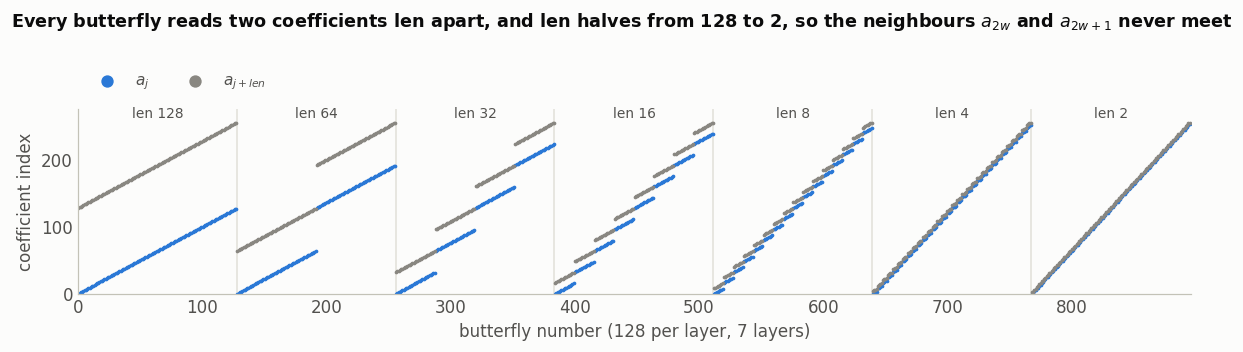

In [51]:
# the memory-access pattern of the whole transform, read from the same trace
f = tr["ntt_sp"][tr["ntt_sp"].state == "FETCH"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.scatter(f.index, f.j, s=2, color=ps.NTT, label="$a_j$", rasterized=True)
ax.scatter(f.index, f.j + f.len, s=2, color=ps.MUTED, label="$a_{j+len}$", rasterized=True)
for layer, (L, g) in enumerate(f.groupby("len", sort=False)):
    x0 = g.index.min()
    if layer:
        ax.axvline(x0 - 0.5, color=ps.GRID, lw=1, zorder=0)
    ax.text(x0 + 64, 262, f"len {L}", ha="center", fontsize=9, color=ps.INK_2)
ax.set_xlim(0, 896); ax.set_ylim(0, 275); ax.grid(False)
ax.set_xlabel("butterfly number (128 per layer, 7 layers)"); ax.set_ylabel("coefficient index")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncols=2, markerscale=5, frameon=False)
fig.suptitle("Every butterfly reads two coefficients len apart, and len halves from 128 to 2, so the neighbours "
             "$a_{2w}$ and $a_{2w+1}$ never meet",
             x=0.01, ha="left", y=0.99, fontsize=11.5, fontweight="bold")
ps.finish(fig); plt.show()

### A.3 Steps A to D, cycle by cycle

Each step of Section 8 removes exactly the cycles its cycle model assigns:

| Step | Cycles removed | Where they come from |
|:---|---:|:---|
| A, packed engine | 46,896 | 5,286 per forward and 6,438 per inverse transform, four of each |
| B, one-round Keccak | 3,744 | 144 from each of the 26 permutations |
| C, overlapped hashes | 7,667 | the whole hash phase of 7,668 cycles less one hand-over cycle, hidden behind the 9,239-cycle decryption; H(c) stays, because it also copies the ciphertext that the final comparison reads |
| D, streamed loops | 5,120 | one cycle per element; the decryption, now 7,959 cycles, still outlasts the hashes |

### A.4 The streamed system, step by step

The table lists the twenty-six changes behind the milestones of Section 8 in the order added, with the
decapsulation of each cumulative build (defines carry the project's working name
TrustEdge-PQC); a blank means that the row-serialized build was verified only with the next change. The
cycle model derives every count except two measured terms, the length of J(z‖c) and the 418 cycles that the
busy row-serialized sponge adds at the end.

In [52]:
steps_ = pd.read_csv(ROOT/"results/system_sim/streamed_steps.csv").set_index("step")
for ms_ in MS:   # the last change of every milestone is the rebuilt milestone
    last = steps_[steps_.milestone == ms_].iloc[-1]
    assert last.record == "milestone build" and last.decaps_one_round_keccak == dc[ms_]["sram_only"]
    assert int(last.decaps_serialized_keccak) == dc[ms_]["asic"]
assert (steps_.decaps_one_round_keccak.diff().dropna() <= 0).all()      # no change lengthens a decapsulation
assert len(steps_) == 26
show_ = steps_.drop(columns=["record"]).rename(columns={
    "decaps_one_round_keccak": "decapsulation, one-round Keccak",
    "decaps_serialized_keccak": "decapsulation, row-serialized Keccak"})
show_["decapsulation, row-serialized Keccak"] = show_["decapsulation, row-serialized Keccak"].map(
    lambda v: "" if pd.isna(v) else f"{int(v):,}")
show_["decapsulation, one-round Keccak"] = show_["decapsulation, one-round Keccak"].map(lambda v: f"{v:,}")
show_

step,milestone,define,change,"decapsulation, one-round Keccak","decapsulation, row-serialized Keccak"
1,E,TRUSTEDGE_FAST_BASEMUL,second multiplier; Karatsuba in both pointwise-product units (five multiply states become two),"33,515","37,259"
2,E,TRUSTEDGE_FAST_FEED,hash feed loops without a wait state; u written straight into the engine,"32,526","34,906"
3,E,TRUSTEDGE_STREAM_OUT,ciphertext compressed and packed while the coefficients stream out,"30,223","32,603"
4,E,TRUSTEDGE_FOLD_READBACK,audit digests folded into the decode check; the separate read-back pass removed,"28,686",
5,E,TRUSTEDGE_PREFETCH,operands of the next product step addressed in advance (encryption and decryption),"25,375","28,771"
6,E,TRUSTEDGE_TIGHT_LOOPS,comparison at one byte per cycle; result writes overlapped with the next pair,"23,846","27,242"
7,E,TRUSTEDGE_FAST_CHECK,codec decode check addresses its next byte in advance,"22,822","26,218"
8,E,TRUSTEDGE_FAST_Y,noise loaded at two cycles per pair; transform results read at one cycle per coefficient,"22,058","25,454"
9,F,TRUSTEDGE_PACKED2,two-lane packed engine; three-plus-four layer fusion (568/569 cycles per transform),"19,229","22,973"
10,F,TRUSTEDGE_FAST_PRF,noise sampler emits a pair of coefficients per cycle,"17,965","21,709"


### A.5 A mutation test of the testbenches

`scripts/mutation_test.py` plants each bug in a copy of the RTL and runs the
unchanged block testbenches of Section 4 on it with the committed golden vectors; a bug counts as caught
when a testbench reports an error, and the unmutated design passes as the control. Each χ mutant is caught
by only one Keccak core, because the one-round core computes χ lane by lane and the row-serialized core row
by row. The equivalent mutant leaves a sum of exactly $q$ unreduced where it feeds only the inverse
transform, in which a stored $q$ behaves exactly as 0. The full-system testbench was not run on the mutants.

In [53]:
mu5 = json.loads((ROOT/"results/mutation/summary.json").read_text())
def caught_by(m):
    if m["equivalent"]:
        return "equivalent (no input exposes it)"
    by = [k for k, r in m["runs"].items() if r["caught"]]
    return ", ".join(by) if by else ("SAT proof only" if m.get("formal", {}).get("caught") else "missed")
nbd.show(pd.DataFrame({m["mutant"]: {"what it models": m["models"], "file": m["file"], "caught by": caught_by(m),
                                    "errors reported (NTT: coefficients; Keccak: permutations)":
                                        "; ".join(f"{k}: {r['errors']}" for k, r in m["runs"].items())}
                       for m in mu5["mutants"]}).T.rename_axis("mutant"), index=True)
print("control (unmutated RTL):", {k: v["how"] for k, v in mu5["control"].items()}, "; SAT proof of the unmutated reducer:",
      mu5["base_formal"]["proof"])
# guards for the statements made in the text above and in Section 4
mm_ = {m["mutant"]: m for m in mu5["mutants"]}
assert [k for k, r in mm_["chi_not_lane"]["runs"].items() if r["caught"]] == ["keccak_round"]
assert [k for k, r in mm_["chi_not_row"]["runs"].items() if r["caught"]] == ["keccak_serial"]
assert mm_["sum_bound"]["equivalent"] and not mm_["sum_bound"]["caught"] and mu5["base_formal"]["proof"] == "holds"
assert mu5["control_passes"] and mu5["total"] == len(mu5["mutants"]) == 10

mutant,what it models,file,caught by,errors reported (NTT: coefficients; Keccak: permutations)
zeta_value,one twiddle factor off by one,rtl/kyber_pkg.sv,packed2_x1,packed2_x1: 38644
barrett_bound,the final correction misses r = q,rtl/barrett_reduce_1c.v,SAT proof only,packed2_x1: 0
sum_bound,modular addition misses a + b = q,rtl/kyber_ntt_engine_packed2.sv,equivalent (no input exposes it),packed2_x1: 0
diff_no_q,modular subtraction without +q,rtl/kyber_ntt_engine_packed2.sv,packed2_x1,packed2_x1: 50727
fsum_bound,the forward butterfly's modular addition misses x + r = q,rtl/kyber_ntt_engine_packed2.sv,packed2_x1,packed2_x1: 9
zeta_index,forward twiddle index shifted by one level,rtl/kyber_ntt_engine_packed2.sv,packed2_x1,packed2_x1: 50893
rho_offset,one lane rotated by 61 instead of 62,rtl/keccak_f1600_iter.sv,"keccak_round, keccak_serial",keccak_round: 202; keccak_serial: 202
round_constant,one bit of the last round constant,rtl/keccak_f1600_iter.sv,"keccak_round, keccak_serial",keccak_round: 202; keccak_serial: 202
chi_not_lane,chi without its NOT (lane-indexed form),rtl/keccak_f1600_iter.sv,keccak_round,keccak_round: 202; keccak_serial: 0
chi_not_row,chi without its NOT (row form),rtl/keccak_f1600_iter.sv,keccak_serial,keccak_round: 0; keccak_serial: 202


control (unmutated RTL): {'packed2_x1': 'passes', 'keccak_round': 'passes', 'keccak_serial': 'passes'} ; SAT proof of the unmutated reducer: holds


## B. Place-and-route details

### B.1 Every routed run

Blocks are compared on their **register-to-register** slack, because the design-level slack includes an
I/O budget that makes a read path of the Keccak wrapper critical; `design fmax` keeps the design-level value.

In [54]:
cols = ["variant","clk_target_ns","flow_rc","die_area_um2","cell_area_um2","flops","wns_ns","reg2reg_slack_ns",
        "fmax_mhz","fmax_design_mhz","drc_errors","antenna_violating_nets","cycles","latency_us_at_fmax","at_product"]
pnr[[c for c in cols if c in pnr]].rename(columns={"at_product": "standard-cell area × time [mm²·µs]"})   # body tables add the macro

design,clock target [ns],flow exit code,die area [µm²],cell area [µm²],flip-flops,design WNS [ns],reg→reg slack [ns],reg→reg fmax [MHz],design fmax [MHz],DRC errors,antenna violations,cycles,latency at fmax [µs],standard-cell area × time [mm²·µs]
"Keccak, one round per clock",10,0,470850,235078.0,3207,2.0061,5.69,232.0186,125.0960,0,0,25,0.1077,0.0253
"Keccak, one round per clock",20,0,470850,234290.0,3207,7.1845,14.48,181.1594,78.0308,0,0,25,0.1380,0.0323
"Keccak, one round per clock",7,0,470850,237944.0,3207,0.5862,2.82,239.2344,155.9150,0,0,25,0.1045,0.0249
"Keccak, row-serialized",10,0,454316,231333.0,3534,1.3298,4.46,180.5054,115.3380,0,0,169,0.9363,0.2166
"Keccak, row-serialized",20,0,454316,230962.0,3534,6.5019,12.32,130.2083,74.0846,0,0,169,1.2979,0.2998
"Keccak, row-serialized",7,0,454316,235517.0,3534,0.1592,2.09,203.6660,146.1810,0,0,169,0.8298,0.1954
"original NTT, dual-port store",15,0,574200,287563.0,4277,-6.0969,-6.10,47.3934,47.4003,0,0,4482,94.5702,27.1949
"original NTT, dual-port store",20,0,574200,287711.0,4277,-1.0580,-1.06,47.4834,47.4878,0,0,4482,94.3909,27.1573
"original NTT, dual-port store",30,0,574200,281128.0,4277,2.8141,2.81,36.7782,36.7838,0,0,4482,121.8656,34.2598
"original NTT, 16 × 256 macro (HSKEM-1)",20,0,293206,38804.7,155,-0.7985,-0.80,48.0769,48.0805,0,0,6274,130.4992,5.0640


The figure below sets the NTT layouts of Sections 6 and 7 against each other; in Colab, menus choose any
pair of metrics, and no layout wins on every axis.

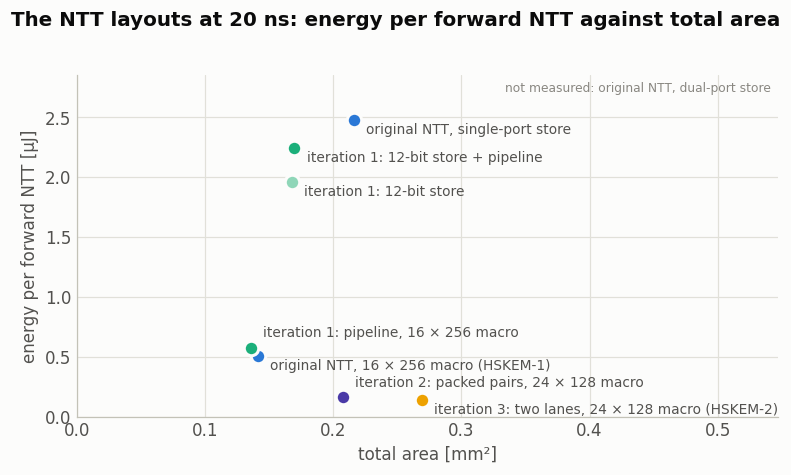

interactive(children=(Dropdown(description='x axis', index=1, options=('total area [mm²]', 'fmax [MHz]', 'late…

In [55]:
nt = pnr[(pnr.clk_target_ns == 20) & pnr.variant.str.startswith("ntt") & ~pnr.variant.str.contains("hm")].set_index("variant")
def _energy(v):
    f = ROOT/"results/gls_power"/f"{v}_20ns"/"summary.json"
    return json.loads(f.read_text())["energy_per_forward_ntt_nj"] / 1e3 if f.exists() else np.nan
explore = pd.DataFrame({
    "total area [mm²]": [sum(total_area(f"{v}_20ns")) / 1e6 for v in nt.index],
    "fmax [MHz]": nt.fmax_mhz.values,
    "latency of a forward NTT [µs]": nt.latency_us_at_fmax.values,
    "energy per forward NTT [µJ]": [_energy(v) for v in nt.index],
    "flip-flops": nt.flops.astype(int).values,
}, index=nt.index)
explore["area × time [mm²·µs]"] = explore["total area [mm²]"] * explore["latency of a forward NTT [µs]"]

def show_points(x="total area [mm²]", y="energy per forward NTT [µJ]"):
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    pts = explore.dropna(subset=[x, y]).sort_values(y)
    for k, (v, r) in enumerate(pts.iterrows()):
        ax.scatter(r[x], r[y], **ps.marker_kw(COLOR[v]))
        close = k > 0 and abs(r[y] - pts[y].iloc[k - 1]) < 0.06 * pts[y].max()   # neighbours: label above
        right = False                                   # labels to the right; the x axis leaves room for them
        ax.annotate(LABEL[v], (r[x], r[y]), xytext=(-8 if right else 8, 7 if close else -9), textcoords="offset points",
                    ha="right" if right else "left", fontsize=9, color=ps.INK_2)
    ax.set_xlim(0, explore[x].max() * 1.9); ax.set_ylim(0, explore[y].max() * 1.15)
    ax.set_xlabel(x); ax.set_ylabel(y)
    missing = explore.index[explore[[x, y]].isna().any(axis=1)]
    if len(missing):
        ax.text(0.99, 0.98, "not measured: " + ", ".join(LABEL[v] for v in missing), transform=ax.transAxes,
                ha="right", va="top", fontsize=8, color=ps.MUTED)
    ps.finish(fig, title=f"The NTT layouts at 20 ns: {y.split(' [')[0]} against {x.split(' [')[0]}")
    if (x, y) == ("total area [mm²]", "energy per forward NTT [µJ]"):
        ps.save_pdf(fig, "ntt_layouts_area_energy")
    plt.show()

show_points()                          # the default pair, stored with the notebook so that it shows everywhere
try:                                   # in Colab or Jupyter: menus for any other pair
    import ipywidgets as widgets
    widgets.interact(show_points,
                     x=widgets.Dropdown(options=list(explore), value="fmax [MHz]", description="x axis"),
                     y=widgets.Dropdown(options=list(explore), value="area × time [mm²·µs]", description="y axis"))
except ImportError:
    pass
# guard for the statement in the text above: no layout is best on every figure of merit
better_high = {"fmax [MHz]"}
best = {m: (explore[m].idxmax() if m in better_high else explore[m].idxmin()) for m in explore}
assert len(set(best.values())) > 1, best

### B.2 The critical path and the routed layouts

The worst setup path of the original single-port NTT (red, *Signal*) runs from a coefficient register
through the modular subtraction, the multiplier and the Barrett reducer to the reduced-product register;
cyan and green are the clock-tree branches to its first and last register.

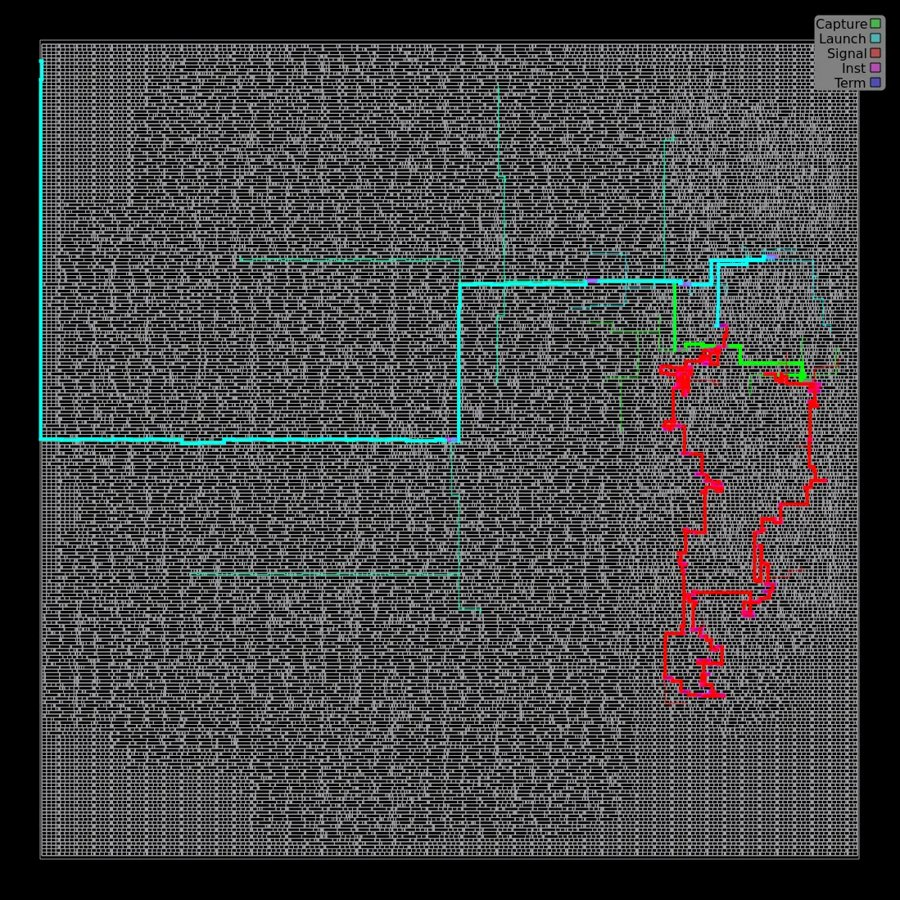

In [56]:
display(Image(str(ROOT/"results/asic/ntt_sp_20ns/worst_path.jpg"), width=520))

The routed layouts below are rendered with KLayout at a common scale.

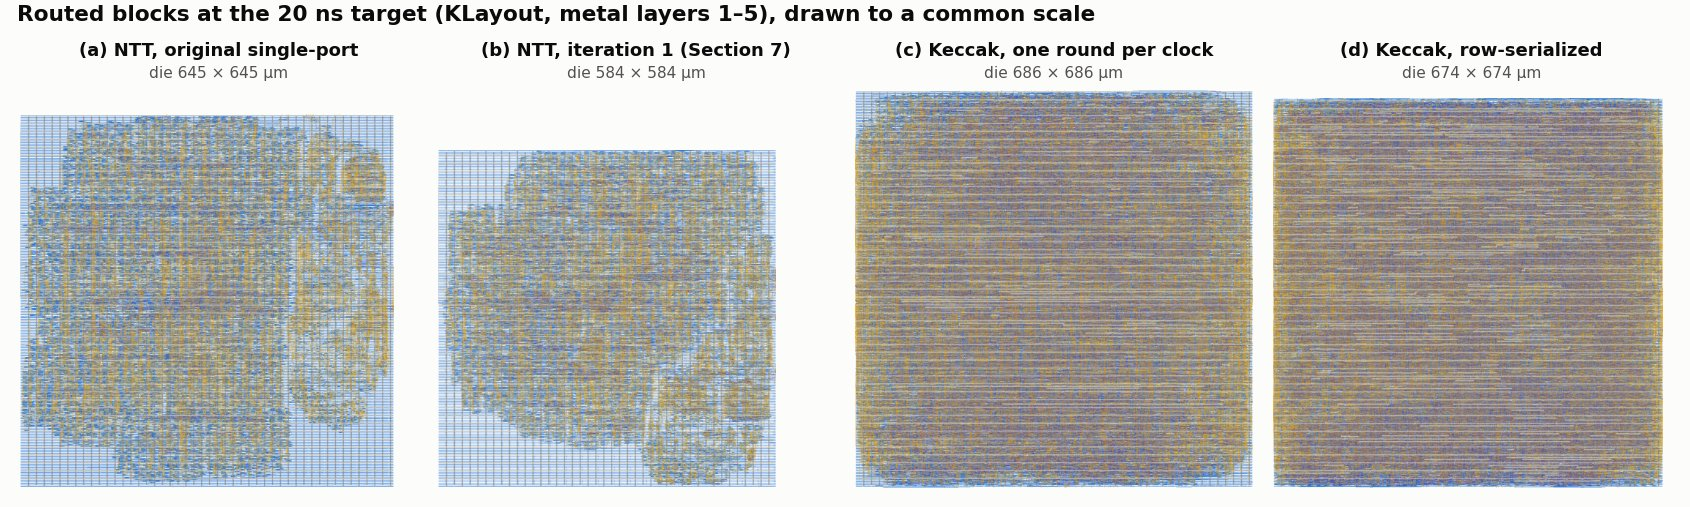

In [57]:
display(Image(str(ROOT/"figures/block_layouts.jpg")))

The next cell fetches one GDS of the release `hskem-block-layouts`, checks its SHA-256 and renders the
file itself; `RUN_DRC_COLAB = True` also runs the front-end rules of Appendix C.3 on it.

ntt_opt_pipe_w12_20ns.gds.gz: 2.3 MB, SHA-256 matches the committed list


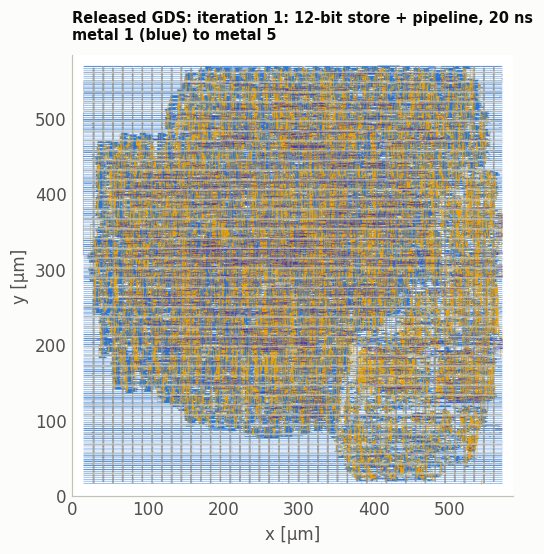

In [58]:
import hashlib, gzip, urllib.request
GDS_POINT = "ntt_opt_pipe_w12_20ns"          # any line of results/asic/release_gds_sha256.txt
RUN_DRC_COLAB = False
REL = "https://github.com/tandat08052007/sscs-ose-code-a-chip.github.io/releases/download/hskem-block-layouts"
want = dict(l.split()[::-1] for l in (ROOT/"results/asic/release_gds_sha256.txt").read_text().splitlines())
gz = pathlib.Path(f"/tmp/{GDS_POINT}.gds.gz")
try:
    if not gz.exists():
        urllib.request.urlretrieve(f"{REL}/{GDS_POINT}.gds.gz", gz)
    digest = hashlib.sha256(gz.read_bytes()).hexdigest()
    assert digest == want[f"{GDS_POINT}.gds.gz"], "the downloaded GDS differs from the published checksum"
    gds = gz.with_suffix("")
    gds.write_bytes(gzip.decompress(gz.read_bytes()))
    print(f"{GDS_POINT}.gds.gz: {gz.stat().st_size / 1e6:.1f} MB, SHA-256 matches the committed list")
    try:
        import klayout.lay as kl
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", "klayout==0.30.7"],
                       check=True, env={**os.environ, "PIP_ROOT_USER_ACTION": "ignore"})   # Colab runs pip as root
        import klayout.lay as kl
    lv = kl.LayoutView()
    lv.set_config("background-color", "#ffffff"); lv.set_config("grid-visible", "false")
    lv.set_config("text-visible", "false")
    lv.load_layout(str(gds), True); lv.max_hier()
    METAL = {(68, 20): 0x2a78d6, (69, 20): 0xeda100, (70, 20): 0x4a3aa7, (71, 20): 0x898781, (72, 20): 0xc3c2b7}
    it = lv.begin_layers()
    while not it.at_end():                      # metal 1 to 5 only, as in the figure above
        lp = it.current()
        key = (lp.source_layer, lp.source_datatype)
        if key not in METAL:
            lp.visible = False
        else:                                   # the palette of the three-scale layout figure of Section 7
            lp.fill_color = lp.frame_color = METAL[key]; lp.dither_pattern = 2
        lv.set_layer_properties(it, lp)
        it.next()
    lv.zoom_fit(); lv.save_image("/tmp/gds_render.png", 1000, 1000)
    bb = lv.active_cellview().layout().top_cell().dbbox()
    fig, ax = plt.subplots(figsize=(5.2, 5.2))
    ax.imshow(plt.imread("/tmp/gds_render.png"), extent=(0, bb.width(), 0, bb.height()))
    ax.set_xlabel("x [µm]"); ax.set_ylabel("y [µm]"); ax.grid(False)
    ax.set_title(f"Released GDS: {nbd.label(GDS_POINT)}\nmetal 1 (blue) to metal 5", loc="left", fontsize=9.5)
    plt.show()
    if RUN_DRC_COLAB:
        if not have("klayout"):
            subprocess.run("apt-get -qq install -y klayout > /dev/null", shell=True, check=True)
        print(sh(f"bash scripts/feol_drc.sh {gds} /tmp/{GDS_POINT}_feol.lyrdb")[-300:])
except (OSError, AssertionError, subprocess.CalledProcessError) as e:   # the committed figure above still stands
    print("release asset not rendered (download, install or hash check failed):", e)

### B.3 Response to the clock target

Runs at 7 to 30 ns show how far each block can be pushed.

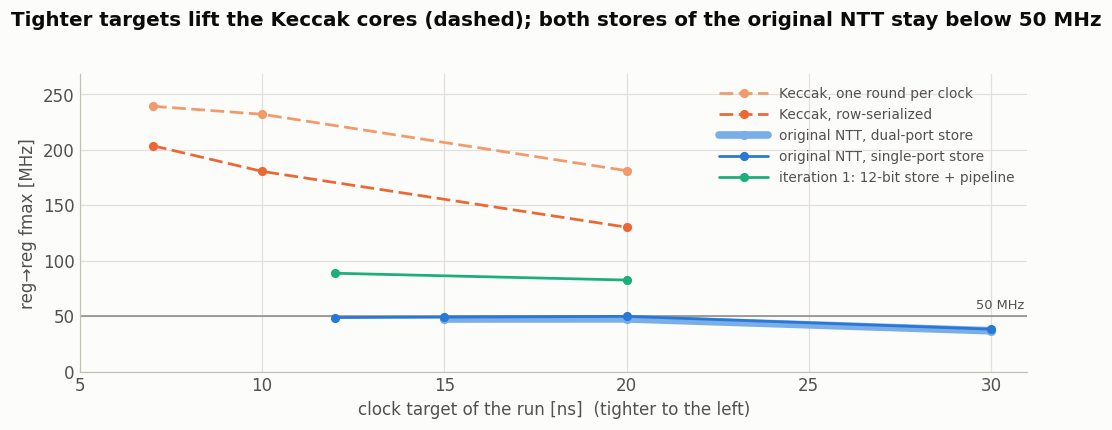

cell-area change vs 20 ns [%],7 ns,10 ns,12 ns,15 ns,20 ns,30 ns
"Keccak, one round per clock",1.6,0.3,,,0.0,
"Keccak, row-serialized",2.0,0.2,,,0.0,
"original NTT, dual-port store",,,,-0.1,0.0,-2.3
"original NTT, 16 × 256 macro (HSKEM-1)",,,,,0.0,
iteration 1: 12-bit store,,,,,0.0,
"iteration 1: pipeline, 16 × 256 macro",,,0.7,,0.0,
iteration 1: 12-bit store + pipeline,,,0.6,,0.0,
"iteration 2: packed pairs, 24 × 128 macro",,,4.2,,0.0,
"iteration 3: two lanes, 24 × 128 macro (HSKEM-2)",,,,,0.0,
"original NTT, single-port store",,,0.4,0.7,0.0,-3.1


In [59]:
fx = pnr.pivot(index="variant", columns="clk_target_ns", values="fmax_mhz")
ar = pnr.pivot(index="variant", columns="clk_target_ns", values="cell_area_um2")
darea = 100 * (ar.div(ar[20.0], axis=0) - 1)
show = fx.round(1).astype(object).where(fx.notna(), "")
show.columns = [f"{c:g} ns" for c in show.columns]
fig, ax = plt.subplots(figsize=(9.5, 3.8))
for v in ["keccak_r1", "keccak_s7", "ntt_dp", "ntt_sp", "ntt_opt_pipe_w12"]:
    line = fx.loc[v].dropna()
    ax.plot(line.index, line.values, marker="o", ms=5, lw=5 if v == "ntt_dp" else 1.8, color=COLOR[v], label=LABEL[v],
            zorder=1 if v == "ntt_dp" else 2,
            ls="-" if v.startswith("ntt") else (0, (5, 2)))
ps.reference_line(ax, 50, "50 MHz")
ax.legend(loc="upper right", fontsize=9, handlelength=3.6)
ax.set_xlim(5, 31); ax.set_ylim(0, fx.max().max() * 1.12)
ax.set_xlabel("clock target of the run [ns]  (tighter to the left)"); ax.set_ylabel("reg→reg fmax [MHz]")
ps.finish(fig, title="Tighter targets lift the Keccak cores (dashed); both stores of the original NTT stay below 50 MHz")
plt.show()
show = darea.round(1).astype(object).where(darea.notna(), "")
show.columns = [f"{c:g} ns" for c in show.columns]
display(show.rename(index=LABEL).rename_axis("cell-area change vs 20 ns [%]"))
# the statements below rest on these checks
assert fx.loc["keccak_r1", 7.0] > 1.3 * fx.loc["keccak_r1", 20.0] and fx.loc["keccak_s7", 7.0] > 1.5 * fx.loc["keccak_s7", 20.0]
assert darea.loc[["keccak_r1", "keccak_s7"], 7.0].max() < 2.0
assert fx.loc["ntt_dp"].max() < 50 and fx.loc["ntt_sp"].max() < 50
assert darea.loc[["ntt_dp", "ntt_sp"], 30.0].between(-3.5, -1.5).all()   # "saves only 2-3 % of area"
assert fx.loc["ntt_opt_pipe_w12", 12.0] > fx.loc["ntt_sp"].max() * 1.7

The Keccak cores gain a third to a half in frequency for at most 2 % more area.

### B.4 The macro's address pins

The macro's Liberty view limits the address-pin transition to 0.04 ns. While the macro sat against the die
edge, the repair buffers ended 25 to 70 µm from six of its pins and left 0.26 to 0.35 ns of transition with minimum-size buffers and 0.05 to 0.07 ns with larger ones (development logs, not committed; Section 12). Flow hooks (`flow/macro_place_*.tcl`, `flow/post_grt_macro_pins.tcl`) move the macro about
30 µm inward and place a 12-times buffer at its halo for every used address pin; four of the five measured
layouts still exceed the limit by about 4 ps at most on two to four pins, and HSKEM-2's two-lane block was
not measured this way.

The pipelined iteration with HSKEM-1's macro, rendered at three scales from its released GDS, shows the
macro below the logic (a), the address-pin drivers along its edge (b) and individual standard cells (c).

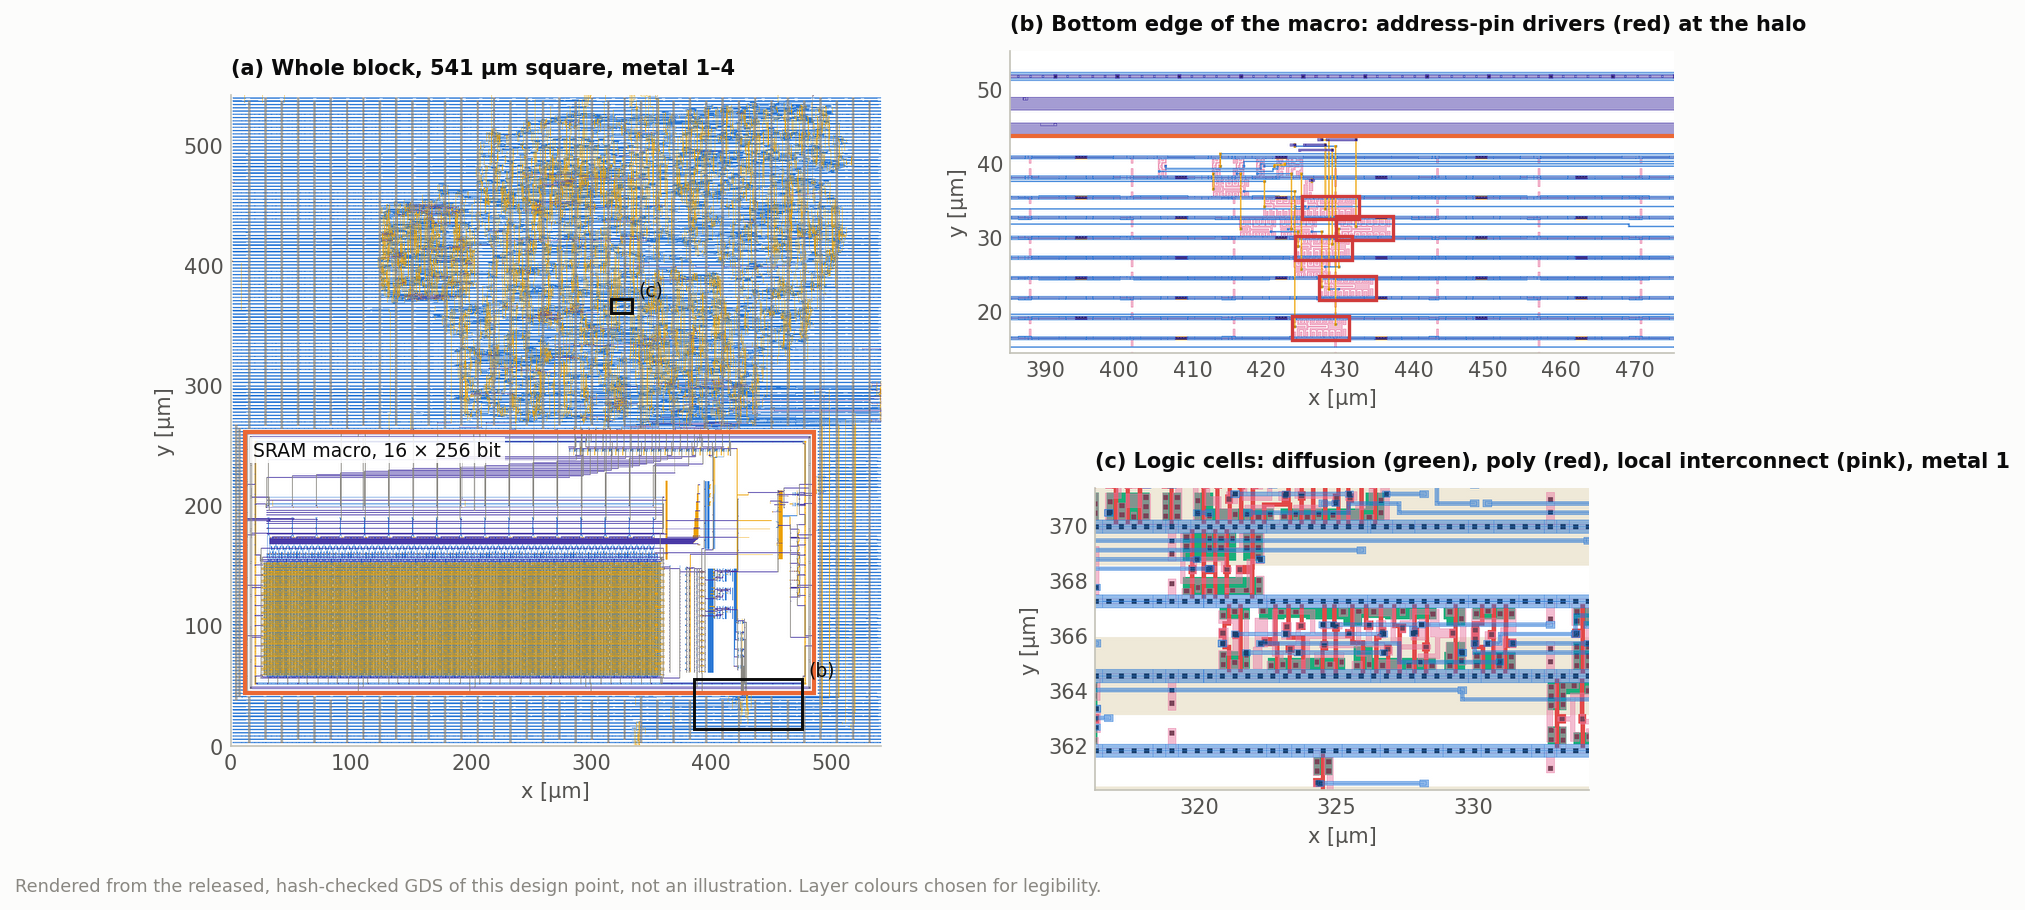

In [60]:
display(Image(str(ROOT/"figures/layout_zoom.png")))   # scripts/layout_zoom_figure.py, from the released GDS

In [61]:
ps_ = json.loads((ROOT/"results/asic/macro_pin_slew.json").read_text())
pin_t = pd.DataFrame({r: v["address_pin_transition_ns"] for r, v in ps_["runs"].items()})
pin_t.columns = [{"ntt_macro_20ns": "original engine, 20 ns", "ntt_opt_pipe_macro_20ns": "pipelined, 20 ns",
                  "ntt_opt_pipe_macro_12ns": "pipelined, 12 ns", "ntt_packed_20ns": "packed, 20 ns",
                  "ntt_packed_12ns": "packed, 12 ns"}[c] for c in pin_t.columns]
display(pin_t.rename_axis("address-pin transition [ns]"))
# the statements made in Sections 6 and 7 and above
over = {r: v["pins_over_limit"] for r, v in ps_["runs"].items()}
assert {r: over[r] for r in ("ntt_macro_20ns", "ntt_opt_pipe_macro_20ns", "ntt_opt_pipe_macro_12ns")} == \
       {"ntt_macro_20ns": 2, "ntt_opt_pipe_macro_20ns": 0, "ntt_opt_pipe_macro_12ns": 2}, over
assert all(0.001 < ps_["runs"][r]["max_ns"] - 0.04 < 0.003 for r in ("ntt_packed_20ns", "ntt_packed_12ns"))   # "about 2 ps"
assert ps_["runs"]["ntt_macro_20ns"]["max_ns"] - 0.04 < 0.0005
assert ps_["runs"]["ntt_opt_pipe_macro_12ns"]["max_ns"] - 0.04 <= 0.0045
for r in ps_["runs"]:
    packed = r.startswith("ntt_packed")
    log = next((ROOT/"results/asic"/r/"logs").rglob("5_1_grt.log")).read_text()
    assert f"CAC_MACRO_PIN_ECO: placed {7 if packed else 8} address-pin drivers (sky130_fd_sc_hd__buf_12)" in log, r
    place = next((ROOT/"results/asic"/r/"logs").rglob("2_2_floorplan_macro.log")).read_text()
    assert ("macro_place_packed.tcl" if packed else "macro_place_ntt.tcl") in place, r

address-pin transition [ns],"original engine, 20 ns","pipelined, 20 ns","pipelined, 12 ns","packed, 20 ns","packed, 12 ns"
addr0[0],0.0398,0.0357,0.0442,0.0410,0.0408
addr0[1],0.0357,0.0361,0.0416,0.0421,0.0424
addr0[2],0.0404,0.0367,0.0400,0.0390,0.0378
addr0[3],0.0376,0.0365,0.0365,0.0420,0.0379
addr0[4],0.0367,0.0400,0.0396,0.0383,0.0397
addr0[5],0.0381,0.0393,0.0370,0.0387,0.0373
addr0[6],0.0402,0.0395,0.0399,0.0413,0.0398
addr0[7],0.0365,0.0371,0.0381,,


### B.5 Process corners and the hold margin

`scripts/sta_corners.sh` re-times the flip-flop-store and Keccak blocks at the slow (`ss`, 100 °C,
1.60 V) and fast (`ff`, −40 °C, 1.95 V) corners; the macro-store blocks are left out, because their SRAM
views exist for the typical corner only.

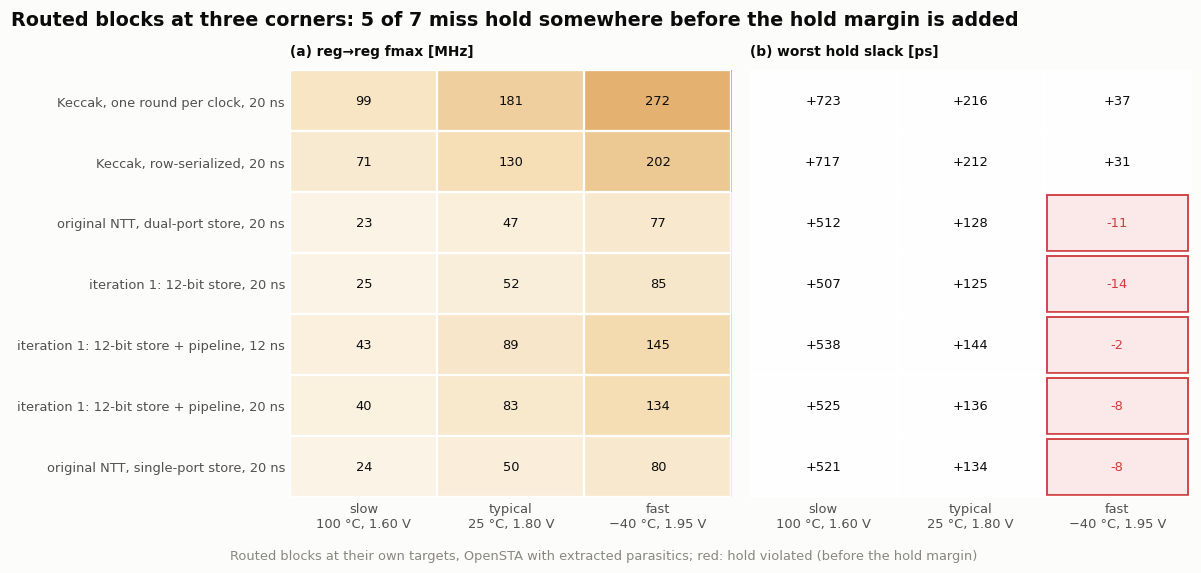

In [62]:
cor = pd.read_csv(ROOT/"results/sta_corners/summary.csv")
tt = cor[cor.corner == "tt_025C_1v80"].set_index("design")
tt_ref = pnr.assign(design=pnr.variant + "_" + pnr.clk_target_ns.map("{:g}".format) + "ns").set_index("design")
assert (abs(tt.reg2reg_setup_slack_ns - tt_ref.loc[tt.index, "reg2reg_slack_ns"]) < 0.01).all(), "STA setup differs from ORFS"
CORNER_ORDER = ["ss_100C_1v60", "tt_025C_1v80", "ff_n40C_1v95"]
fmx = cor.pivot(index="design", columns="corner", values="reg2reg_fmax_mhz")[CORNER_ORDER]
hold = cor.pivot(index="design", columns="corner", values="hold_wns_ns")[CORNER_ORDER] * 1e3      # ps
rows = [nbd.label(d) for d in fmx.index]
cols = ["slow\n100 °C, 1.60 V", "typical\n25 °C, 1.80 V", "fast\n−40 °C, 1.95 V"]
fig, ax = plt.subplots(1, 2, figsize=(11, 0.45 * len(rows) + 1.6))
import matplotlib.colors as mcolors
warm_ = mcolors.LinearSegmentedColormap.from_list("warm", ["#fdf8ef", "#f5d9a8", "#e0a458"])
for a, data, cmap, fmt, title in ((ax[0], fmx, warm_, "{:.0f}", "(a) reg→reg fmax [MHz]"),
                                  (ax[1], hold * 0, "Greys", "{:+.0f}", "(b) worst hold slack [ps]")):
    a.imshow(data.values, cmap=cmap, aspect="auto", vmin=0, vmax=max(data.values.max(), 1), alpha=0.85)
    a.grid(False)
    for (r, c), v in np.ndenumerate((fmx if a is ax[0] else hold).values):
        a.text(c, r, fmt.format(v), ha="center", va="center", fontsize=8.5,
               color=ps.CRITICAL if (a is ax[1] and v < 0) else ps.INK)
        if a is ax[1] and v < 0:
            a.add_patch(plt.Rectangle((c - 0.48, r - 0.46), 0.96, 0.92, fc="#fbe9e9", ec=ps.CRITICAL, lw=1.2, zorder=0))
    a.set_xticks(range(3), cols, fontsize=8.5); a.set_yticks(range(len(rows)), rows if a is ax[0] else [""] * len(rows), fontsize=8.5)
    a.set_title(title, loc="left", fontsize=9); a.tick_params(length=0)
    for sp in a.spines.values(): sp.set_visible(False)
    a.set_xticks(np.arange(-0.5, 3), minor=True); a.set_yticks(np.arange(-0.5, len(rows)), minor=True)
    a.grid(which="minor", color="white", lw=1.5); a.tick_params(which="minor", length=0)
fig.text(0.5, -0.02, "Routed blocks at their own targets, OpenSTA with extracted parasitics; red: hold violated (before the hold margin)",
         ha="center", fontsize=8.5, color=ps.MUTED)
plt.tight_layout()
fig.suptitle(f"Routed blocks at three corners: {int((hold < 0).any(axis=1).sum())} of {len(hold)} miss hold "
             "somewhere before the hold margin is added",
             x=0.01, ha="left", y=1.03, fontsize=12.5, fontweight="bold")
ps.save_pdf(fig, "corners"); plt.show()
# guards for the statements made in the text below
fx_c = cor.pivot(index="design", columns="corner", values="reg2reg_fmax_mhz")
hold_ff = cor[cor.corner.str.startswith("ff")].set_index("design").hold_wns_ns
assert fx_c["ss_100C_1v60"].div(fx_c["tt_025C_1v80"]).between(0.4, 0.6).all()
assert hold_ff.filter(like="ntt").between(-0.015, 0, inclusive="left").all()
assert (cor[cor.design.str.startswith("keccak")].reg2reg_hold_slack_ns > 0).all()

At the slow corner every block runs at roughly half its typical-corner frequency. At the fast corner the
five flip-flop-store NTT layouts miss hold by 2 to 14 ps, because ORFS repairs hold at the typical corner
only; re-run with `HOLD_SLACK_MARGIN = 0.17` ns, they meet it:

In [63]:
hc = json.loads((ROOT/"results/asic/hold_margin_check.json").read_text())["layouts"]
CN = ("ss_100C_1v60", "tt_025C_1v80", "ff_n40C_1v95")
rows = {}
for base, v in hc.items():
    h0, h1 = v["committed"], v["hold margin 0.17 ns"]
    rows[base] = {"ff hold before [ps]": 1e3 * h0["hold_wns_ns_ff_n40C_1v95"],
                  "ff hold after [ps]": 1e3 * h1["hold_wns_ns_ff_n40C_1v95"],
                  "worst hold after, any corner [ps]": 1e3 * min(h1[f"hold_wns_ns_{c}"] for c in CN),
                  "cell change": h1["stdcell_count"] - h0["stdcell_count"],
                  "area change [%]": 100 * (h1["stdcell_area_um2"] / h0["stdcell_area_um2"] - 1),
                  "fmax before [MHz]": h0["fmax_mhz"], "fmax after [MHz]": h1["fmax_mhz"],
                  "GLS after": "pass" if h1["gls_pass"] else "FAIL"}
hct = pd.DataFrame(rows).T.infer_objects()
display(hct.round({c: 0 for c in hct.columns[:3]} | {"area change [%]": 3,
                   "fmax before [MHz]": 2, "fmax after [MHz]": 2}).rename(
    columns={"fmax before [MHz]": "design fmax before [MHz]", "fmax after [MHz]": "design fmax after [MHz]"}))
# guards for the statements made in the text
assert len(hc) == 5, "every NTT layout of the corner table should have been re-run"
assert (hct["ff hold before [ps]"] < 0).all() and (hct["worst hold after, any corner [ps]"] >= 0).all()
assert (hct["cell change"].abs() <= 6).all() and (hct["area change [%]"].abs() < 0.02).all()
assert (hct["fmax after [MHz]"] / hct["fmax before [MHz]"]).between(0.995, 1.005).all()
assert (hct["fmax after [MHz]"] - hct["fmax before [MHz]"]).abs().max() <= 0.4          # "at most 0.4 MHz"
assert (hct["GLS after"] == "pass").all()

,ff hold before [ps],ff hold after [ps],"worst hold after, any corner [ps]",cell change,area change [%],design fmax before [MHz],design fmax after [MHz],GLS after
"original NTT, dual-port store, 20 ns",-11,51,51,-5,0.001,47.49,47.49,pass
"original NTT, single-port store, 20 ns",-8,59,59,2,0.016,49.74,49.75,pass
"iteration 1: 12-bit store, 20 ns",-14,50,50,6,0.018,52.28,52.31,pass
"iteration 1: 12-bit store + pipeline, 20 ns",-8,18,18,3,0.013,82.49,82.39,pass
"iteration 1: 12-bit store + pipeline, 12 ns",-2,60,60,3,0.018,88.64,88.28,pass


The notebook keeps using the original layouts, from which the repaired ones differ by at most 0.4 MHz in
fmax and 0.02 % in area.

### B.6 Gate-level verification and energy of the first iteration

`scripts/run_gls_power.sh` simulates each routed netlist of Section 7 against the golden vectors, and the
same simulation gives the switching activity from which OpenSTA derives the energy; the functional half
also runs in Colab.

In [64]:
RUN_GLS = IN_COLAB   # re-simulate the routed netlist of the pipelined NTT (about 5-8 minutes)
if RUN_GLS:
    out = sh("bash scripts/run_gls.sh ntt_opt_pipe_w12_20ns")
    assert "errors=0" in out and "PASS" in out, "the routed netlist failed gate-level simulation"
gp = {}
for r in ["ntt_sp_20ns", "ntt_opt_b1_w12_20ns", "ntt_opt_pipe_w12_20ns"]:
    f = ROOT/"results/gls_power"/r/"summary.json"
    if f.exists():
        gp[r.rsplit("_", 1)[0]] = json.loads(f.read_text())
gp = pd.DataFrame(gp).T
assert gp.gls_pass.all(), "a routed netlist failed gate-level simulation"
gp["power [mW]"] = gp.total_power_w.astype(float) * 1e3
gp["energy / forward NTT [µJ]"] = gp.energy_per_forward_ntt_nj.astype(float) / 1e3
gp.index = [LABEL.get(v, v) for v in gp.index]
if len(gp) == 3:
    e = gp["energy / forward NTT [µJ]"].astype(float).values
    assert e[1] < e[2] < e[0], "energy ordering stated in the text no longer holds"
    assert 0.75 < e[1] / e[0] < 0.85, "the 12-bit store no longer saves about a fifth of the energy"
# power groups of the original block, as reported by OpenSTA
grp_pw = {g: float(s) / 100 for g, s in re.findall(r"^(Sequential|Clock)\s.*?([\d.]+)%\s*$",
          (ROOT/"results/gls_power/ntt_sp_20ns/power.log").read_text(), re.M)}
print("original single-port NTT, share of power:", {g: f"{s:.0%}" for g, s in grp_pw.items()})
assert 0.45 < grp_pw["Sequential"] < 0.55 and 0.35 < grp_pw["Clock"] < 0.45
gp["energy spread, 5 inputs [%]"] = [energy_spread(r) for r in ["ntt_sp_20ns", "ntt_opt_b1_w12_20ns", "ntt_opt_pipe_w12_20ns"]]
assert (gp["energy spread, 5 inputs [%]"] < 0.2).all(), "the energy now depends noticeably on the input"
gp[["gls_pass", "cycles_fwd", "power [mW]", "energy / forward NTT [µJ]", "energy spread, 5 inputs [%]"]].round(3)

original single-port NTT, share of power: {'Sequential': '50%', 'Clock': '40%'}


,gate-level simulation passed,"cycles, forward NTT",power [mW],energy / forward NTT [µJ],"energy spread, 5 inputs [%]"
"original NTT, single-port store",True,6274,19.760,2.479,0.106
iteration 1: 12-bit store,True,6274,15.627,1.961,0.122
iteration 1: 12-bit store + pipeline,True,7170,15.668,2.247,0.103


Further random inputs change the energy by less than 0.2 %. Because nine tenths of the original block's
power goes into its flip-flops and their clock tree, removing a quarter of the storage saves about a fifth
of the energy, and the pipeline register gives part of it back.

## C. Chip-level details of HSKEM-2

The signed-off layout keeps the two chip-only changes of HSKEM-2's first layout (pipelined products
registered before their reduction; the codec packs each coefficient one cycle after loading it) and adds the
fourteen of Section 9, all bit-exact. Together they add 19 cycles to a decapsulation, 11 to an encapsulation
and 512 to a key generation, whose matrix products gain one cycle per coefficient pair; the session changes
add none. `flow/chip_rev_c/README.md` lists the changes, the script that rebuilds this RTL from the published
sources and the flow, including the timing repair before detailed routing and two fixes at one macro corner
that cleared the last routing violations.

### C.1 Timing at three corners

`flow/chip_rev_c/flow/final_sta.tcl` re-times the routed database with its parasitics at each corner and
replaces OpenRAM's clock-to-output time by the SPICE measurement of each macro type (both in the table).
The macros' setup and hold times remain OpenRAM's typical-corner values, so SPICE also checks the macro inputs
with the smallest margins (below the table). WNS, the worst negative slack, is the smallest margin over all paths, positive
when the check passes; setup margins grow and the hold margins of the shared-clock check shrink toward the fast corner.

Hold at the entropy, PUF and service-interface inputs is checked against a clock that shares the core clock
tree, while the synchronized SPI pins are excluded; the rows marked "as written" show the result without
that assumption. The frequencies in the table come from shortening the clock until a path fails, because
the macros' falling-edge reads are half-cycle paths that the flow's own estimate misses. The slowest path
at the slow corner (last line) leaves the ciphertext macro on the falling edge and crosses the die within
half a period.

In [65]:
CN3 = {"ss": "slow (100 °C, 1.60 V)", "tt": "typical (25 °C, 1.80 V)", "ff": "fast (−40 °C, 1.95 V)"}
ru = sta9["runs"]
fs9 = sta9["fmax_search"]
t9 = pd.DataFrame({CN3[c]: {"fmax [MHz]": fs9[c]["fmax_mhz"],
                            "setup WNS [ns]": ru[f"{c}_spice_soc"]["setup_wns"],
                            "hold WNS [ns]": ru[f"{c}_spice_soc"]["hold_wns"],
                            "hold WNS into the macros [ns]": sta9["macro_input_hold"][c]["slack_ns"],
                            "input change after the macro clock, closest hold path [ns]":
                                sta9["macro_input_hold"][c]["input_change_after_macro_clock_ns"],
                            "hold WNS, constraints as written [ns]": ru[f"{c}_spice_sdc"]["hold_wns"],
                            "hold-violating endpoints, constraints as written": int(ru[f"{c}_spice_sdc"]["hold_violating_endpoints"]),
                            "macro clock-to-output, SPICE [ns]": f'{min(sta9["macro_clk_to_dout_ns"][c].values()):.2f}–{max(sta9["macro_clk_to_dout_ns"][c].values()):.2f}',
                            "macro clock-to-output, OpenRAM view [ns]": f'{min(sta9["macro_clk_to_dout_view_ns"][c].values()):.2f}–{max(sta9["macro_clk_to_dout_view_ns"][c].values()):.2f}'}
                   for c in ("ss", "tt", "ff")})
display(t9.rename_axis("HSKEM-2, extracted parasitics"))
der = {c: ru[k] for c, k in (("ss", "ss_spice_soc_derate5"), ("ff", "ff_view_soc_derate5"))}
w9 = sta9["slow_corner_worst_path"]
print(f"±5 % cell-delay derate: slow corner setup {der['ss']['setup_wns']:+.3f} ns, hold {der['ss']['hold_wns']:+.3f} ns "
      f"({fs9['ss_derate5']['fmax_mhz']:.2f} MHz); fast corner hold {der['ff']['hold_wns']:+.3f} ns")
sta_fc = json.loads((ROOT/"results/fullchip/first_chip/sta_analysis.json").read_text())
print("HSKEM-1:", sta_fc["analysis"].split(". An earlier")[0] + ".")
print("slow corner, SPICE: the 24 × 256 macro works with its inputs ready 0.1 ns before the clock but corrupts data when "
      "they change 0.3 ns after it and needs up to 0.6 ns of hold (its view: −0.06 ns); every macro input of the chip "
      "changes at least 1.2 ns after its clock; the 8 × 768 macro, which receives the closest hold paths, works at the "
      "input-change times in the table")
print(f"slow-corner worst path: macro output on the falling edge {w9['macro_clk_to_dout_ns']:.2f} ns, {w9['repeaters']} repeaters "
      f"{w9['repeater_delay_ns']:.2f} ns, {w9['logic_cells']} logic cells {w9['logic_delay_ns']:.2f} ns, slack {w9['slack_ns']:+.3f} ns")
sp9 = sta9["spice_input_timing"]
g256 = {float(k): v for k, v in sp9["sky130_sram_1rw_24x256_ss"]["points_pass"].items()}
h128 = sp9["sky130_sram_1rw_8x768_hold_at_sta_arrival"]
# guards for the statements made in the text above and in Section 9
assert all(ru[f"{c}_spice_soc"][k] > 0 for c in ("ss", "tt", "ff") for k in ("setup_wns", "hold_wns"))
assert all(der[c]["setup_wns"] > 0 and der[c]["hold_wns"] > 0 for c in der)
assert round(fs9["ss"]["fmax_mhz"], 1) == 26.9 and abs(fs9["ss_derate5"]["fmax_mhz"] - 25.05) < 0.01
assert round(der["ss"]["setup_wns"], 3) == 0.039                                              # Section 13: "0.039 ns"
assert all(0 <= fs9[c]["setup_wns_at_period_ns"] < 0.02 for c in fs9)                         # bisection converged
assert abs(2 * (20 - ru["ss_spice_soc"]["setup_wns"]) - fs9["ss"]["period_ns"]) < 0.03         # a half-cycle path sets the slow corner
assert all(fs9[c]["period_ns"] >= 2 * (20 - ru[f"{c}_spice_soc"]["setup_wns"]) - 0.03 for c in ("ss", "tt", "ff"))
assert "reproduces ORFS's own final report" in sta_fc["analysis"]
assert all(sta9["macro_input_hold"][c]["slack_ns"] > 0 for c in ("ss", "tt", "ff"))
assert [round(sta9["macro_input_hold"][c]["input_change_after_macro_clock_ns"], 2) for c in ("ss", "tt", "ff")] == [1.4, 0.77, 0.51]
assert {c: v["pass"] for c, v in h128.items()} == {"ss": True, "tt": True, "ff": True}
assert all(abs(h128[c]["input_change_after_edge_ns"] - sta9["macro_input_hold"][c]["input_change_after_macro_clock_ns"]) < 0.002 for c in h128)
assert g256[-0.1] and not g256[-39.7] and g256[-39.4]                     # setup 0.1 ns; hold between 0.3 and 0.6 ns
assert sta9["macro_input_hold"]["ss"]["view_hold_ns"] == -0.056
r_ = {c: [sta9["macro_clk_to_dout_ns"][c][k] / sta9["macro_clk_to_dout_view_ns"][c][k] for k in sta9["macro_clk_to_dout_ns"][c]] for c in ("ss", "tt")}
assert 9.5 < min(r_["ss"]) and max(r_["ss"]) < 12.5 and 5 < min(r_["tt"]) and max(r_["tt"]) < 7   # "six times ... ten times"
assert len({round(v, 3) for v in sta9["macro_clk_to_dout_view_ns"]["ss"].values()} ^ {round(v, 3) for v in sta9["macro_clk_to_dout_view_ns"]["ff"].values()}) == 0   # "the same at every corner"
mh9 = sta9["macro_input_hold"]["ss"]
assert mh9["slack_ns"] + mh9["view_hold_ns"] >= 1.2                                           # "at least 1.2 ns after its clock"
assert int(ru["ss_spice_sdc"]["hold_violating_endpoints"]) == 286 and -1.06 <= ru["ss_spice_sdc"]["hold_wns"] < -1.05
assert (w9["repeaters"], w9["logic_cells"], round(w9["macro_clk_to_dout_ns"], 1)) == (13, 15, 4.1)
cyc_ = lambda t: [int(x) for x in re.findall(r"oracle cycles=(\d+)", t)]
assert [b_ - a_ for a_, b_ in zip(cyc_(h_sim), cyc_(chip_sim))] == [512, 10, 11]   # key generation, encryption, encapsulation

"HSKEM-2, extracted parasitics","slow (100 °C, 1.60 V)","typical (25 °C, 1.80 V)","fast (−40 °C, 1.95 V)"
fmax [MHz],26.87,50.48,81.45
setup WNS [ns],1.395,10.095,13.863
hold WNS [ns],0.541,0.254,0.094
hold WNS into the macros [ns],1.257,0.626,0.369
"input change after the macro clock, closest hold path [ns]",1.401,0.77,0.513
"hold WNS, constraints as written [ns]",-1.052,0.087,0.094
"hold-violating endpoints, constraints as written",286,0,0
"macro clock-to-output, SPICE [ns]",3.76–4.20,2.06–2.35,1.21–1.41
"macro clock-to-output, OpenRAM view [ns]",0.34–0.42,0.34–0.42,0.34–0.42


±5 % cell-delay derate: slow corner setup +0.039 ns, hold +0.322 ns (25.05 MHz); fast corner hold +0.006 ns
HSKEM-1: OpenROAD's STA on the routed database with the extracted SPEF. The typical corner reproduces ORFS's own final report (setup WNS +4.893 ns, hold WNS +0.119 ns).
slow corner, SPICE: the 24 × 256 macro works with its inputs ready 0.1 ns before the clock but corrupts data when they change 0.3 ns after it and needs up to 0.6 ns of hold (its view: −0.06 ns); every macro input of the chip changes at least 1.2 ns after its clock; the 8 × 768 macro, which receives the closest hold paths, works at the input-change times in the table
slow-corner worst path: macro output on the falling edge 4.06 ns, 13 repeaters 3.39 ns, 15 logic cells 10.70 ns, slack +1.395 ns


**Parasitic corners.** The sign-off uses the extraction rules of the flow (`rcx_patterns.rules` of OpenROAD-flow-scripts). The
PDK ships six more OpenRCX rule sets, three for OpenLane and three derived from Magic, and `flow/chip_rev_c/revc/rc_corners.sh`
applies them all to the signed-off database. The OpenLane sets hold no coupling capacitance, and their minimum, nominal and
maximum differ only in resistance, so they see less than half of the flow's capacitance. The sets derived from Magic do not
agree with each other: their minimum holds almost twice the capacitance of their nominal, and their coupling between
minimum-spaced met2 wires is 0.53 fF/µm, where a parallel-plate estimate gives 0.09 fF/µm and the flow's rules 0.13 fF/µm.
With them the slow corner would fail by 12 to 42 ns. The sign-off therefore stays with the flow's rules, and the same
script scales its parasitics instead. The resistance factors follow the PDK's models, from ±11 % for met1 and met2 to ±18 % for
met5; those models give no corner for wire capacitance, so its factors are an assumption, and no field solver has checked
any of these rule sets. All slacks are in ns at the 40 ns clock, with the I/O model of the table above.

In [66]:
rc = json.loads((R9/"rc_corners.json").read_text())
S, rt, rr = rc["sets"], rc["rule_tables_met2_over_met1"], rc["pdk_resistance_ratio_high_low"]
NM = {"orfs": "flow's rules, repeated (control)", "nom": "PDK, OpenLane set, nominal", "min": "PDK, OpenLane set, minimum", "max": "PDK, OpenLane set, maximum",
      "mnom": "PDK, Magic set, nominal", "mmin": "PDK, Magic set, minimum", "mmax": "PDK, Magic set, maximum",
      "hi10": "sign-off, R × 1.11, C × 1.10", "hi15": "sign-off, R × 1.15, C × 1.15", "hi20": "sign-off, R × 1.18, C × 1.20", "hi30": "sign-off, R × 1.30, C × 1.30",
      "lo20": "sign-off, R × 0.82, C × 0.80", "lo30": "sign-off, R × 0.70, C × 0.70"}
def slack(t, c, k):
    v = [S[t]["corners"][x][k] for x in c if x in S[t]["corners"]]
    return f"{min(v):+.3f}" if v else "–"
print("wire capacitance, slack in ns at the 40 ns clock; fast-corner hold is the smaller of the SPICE and the OpenRAM macro views")
display(pd.DataFrame([{"parasitics": NM[t], "total wire C [pF]": f"{S[t]['total_net_cap_pF']:,.0f}",
                       "slow setup": slack(t, ["ss_spice"], "setup_wns"), "slow hold": slack(t, ["ss_spice"], "hold_wns"),
                       "typical setup": slack(t, ["tt_spice"], "setup_wns"), "typical hold": slack(t, ["tt_spice"], "hold_wns"),
                       "fast setup": slack(t, ["ff_spice"], "setup_wns"), "fast hold": slack(t, ["ff_spice", "ff_view"], "hold_wns")}
                      for t in NM]).set_index("parasitics"))
ss = lambda t, k="setup_wns": S[t]["corners"]["ss_spice"][k]
# the control reproduces the sign-off, and the guards for the statements above and in Section 13
assert all(S["orfs"]["corners"][f"{c}_spice"][k] == ru[f"{c}_spice_soc"][k] for c in ("ss", "tt", "ff") for k in ("setup_wns", "hold_wns"))
assert S["nom"]["total_net_cap_pF"] == S["min"]["total_net_cap_pF"] == S["max"]["total_net_cap_pF"]    # "differ only in resistance"
assert rt["spef_extractor_nom"]["coupling_pF_per_um"] == 0 and S["orfs"]["total_net_cap_pF"] / S["nom"]["total_net_cap_pF"] > 2   # "less than half"
assert 1.9 < S["mmin"]["total_net_cap_pF"] / S["mnom"]["total_net_cap_pF"] < 2                         # "almost twice"
assert round(rt["magic_nom"]["coupling_pF_per_um"] * 1e3, 2) == 0.53 and round(rt["flow"]["coupling_pF_per_um"] * 1e3, 2) == 0.13
assert rt["flow"]["spacing_um"] == 0.14 and round(8.854e-3 * 4.0 * 0.36 / rt["flow"]["spacing_um"], 2) == 0.09   # eps0, relative permittivity 4, met2 0.36 um thick
assert (round(-ss("mnom")), round(-ss("mmax"))) == (12, 42)                                            # "fail by 12 to 42 ns"
assert (round(100 * (rr["m1"][0] - 1)), round(100 * (rr["m5"][0] - 1)), round(100 * (1 - rr["m1"][1])), round(100 * (1 - rr["m5"][1]))) == (11, 18, 11, 18)   # "±11 % ... ±18 %"
assert round(ss("hi15"), 2) == 0.34 and S["hi15"]["corners"]["ss_spice"]["setup_violating_endpoints"] == 0   # Section 13: "0.34 ns"
assert round(ss("hi20") * 1e3) == -8 and S["hi20"]["corners"]["ss_spice"]["setup_violating_endpoints"] == 1  # Section 13: "one endpoint misses by 8 ps"
assert all(v["hold_wns"] > 0 for t in ("hi10", "hi15", "hi20", "hi30", "lo20", "lo30") for v in S[t]["corners"].values())   # "in every scaled case"

wire capacitance, slack in ns at the 40 ns clock; fast-corner hold is the smaller of the SPICE and the OpenRAM macro views


parasitics,total wire C [pF],slow setup,slow hold,typical setup,typical hold,fast setup,fast hold
"flow's rules, repeated (control)","2,925",+1.395,+0.541,+10.095,+0.254,+13.863,+0.094
"PDK, OpenLane set, nominal","1,324",+2.477,+0.288,+11.099,+0.107,+14.551,+0.028
"PDK, OpenLane set, minimum","1,324",+2.474,+0.287,+11.099,+0.106,+14.552,+0.026
"PDK, OpenLane set, maximum","1,324",+2.480,+0.290,+11.098,+0.107,+14.550,+0.029
"PDK, Magic set, nominal","7,019",-12.489,+0.753,+4.629,+0.279,+10.489,+0.089
"PDK, Magic set, minimum","13,462",-39.839,+0.650,-4.072,+0.191,+5.150,+0.008
"PDK, Magic set, maximum","14,115",-42.214,+0.634,-5.565,+0.170,+4.517,-0.004
"sign-off, R × 1.11, C × 1.10","3,217",+0.686,+0.592,–,–,–,–
"sign-off, R × 1.15, C × 1.15","3,363",+0.337,+0.616,–,–,–,–
"sign-off, R × 1.18, C × 1.20","3,510",-0.008,+0.640,+9.356,+0.257,+13.386,+0.097


### C.2 The rendered layout and the sign-off record

The rendering (about 2.5 µm per pixel) shows the SRAM macros along the left and top edges and in the lower
right corner. The routed database of the signed-off layout, with both GDS files from before and after the
implant fix of Appendix C.3, is attached to the release
[`hskem2-rev-c`](https://github.com/tandat08052007/sscs-ose-code-a-chip.github.io/releases/tag/hskem2-rev-c)
of the author's fork with the hashes below; it contains no secret, because the provisioning credential in
its logic is the public placeholder of Appendix E.3.

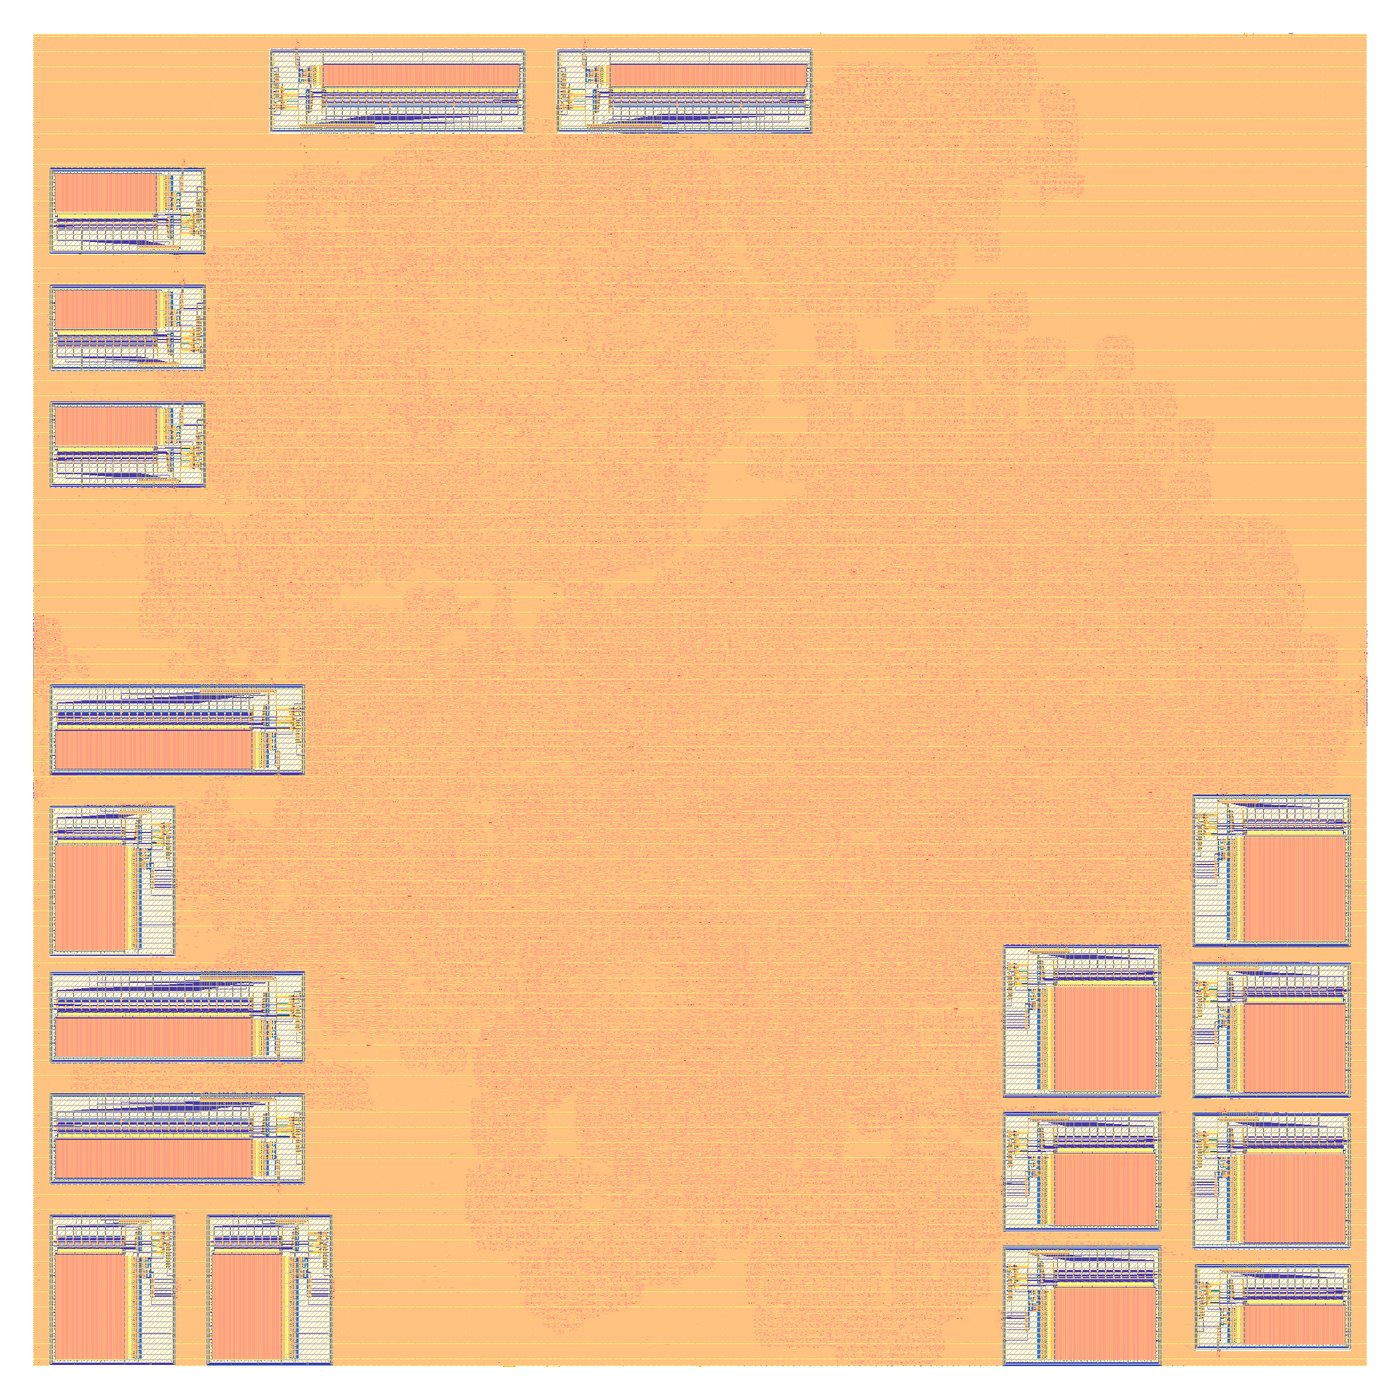

HSKEM-2 sign-off,result
routing,"0 router DRC violations, 0 antenna violations"
"LVS, top level (macros abstracted to their pin frames)","233,958 devices and 234,512 nets on both sides; circuits match uniquely, repeated: circuits match uniquely"
"LVS, negative control (one net altered)",Netlists do not match
"LVS, abstracted","7 SRAM types (18 instances), each with its own transistor-level LVS in Netgen; 6 multi-finger cells"
"DRC, back end and off-grid","0 markers; ORFS sky130hd.lydrc rules unchanged (BEOL and OFFGRID sections, FEOL checked separately), deep mode with threads(4), run as eight part decks that partition the BEOL rule lines (scripts/split_beol_deck.py of the submission); split because one run outgrew the build machine's memory"
"DRC, Magic (outside the OpenRAM macros)","368 poly-contact markers (licon.8a) in 325 instances: 282 of a2111oi_0 with one each, 43 of buf_16 with two; none in the PDK's corrected GDS of these cells; 23.8 million inside the OpenRAM macros, also in a macro checked alone, whose cells the KLayout deck accepts"
transition / capacitance violations (typical),"158 / 0 (26 on HSKEM-2's first layout), all 158 at the address pins of the 18 macros, up to 0.19 ns where the macros' tables end at 0.04 ns, so their input timing is extrapolated; timing uses the actual transitions"
"static IR drop, decapsulation activity","VDD 3.44 mV, VSS 3.53 mV worst, at 111 mW (ideal sources at both ends of every top-metal strap, no package model)"
gate-level simulation (zero delay),"6,873 cycles of a decapsulation next to the RTL, 0 output mismatches; two flip-flops (named by a listing run on an earlier layout with the same mismatch pattern) differ only while the RTL holds an unknown value in an unreset pipeline register whose result is never used"


released file (compressed),SHA-256
hskem2_rev_c_6_final.def.gz,1194f34ceed2607681e17d74ee140c80d1c07af8520f7a5dc0e2d4bd41fc8649
hskem2_rev_c_6_final.gds.gz,44b0c8c8085f8d98fec81ca09a819de638d794371ca01f382061cfc084790743
hskem2_rev_c_6_final.odb.gz,34e1fdc855b380b7a937c2db377a75ee9faeaa6195b707ecd98803cbc157f434
hskem2_rev_c_6_final.sdc.gz,fdb37c6b8af7aa66e1c4230cebd235f7f0640b78d8afc4e4ee693f7b9c9c8712
hskem2_rev_c_6_final.spef.gz,5804ff5bee8476cfe029da4785eb1d95929a5523dc013cc71d7f9c6db0d0fb6e
hskem2_rev_c_6_final.v.gz,59bcb30a1aebfa288096b6148cc759fc3e948fb1249a92995289c02b04d287dd
hskem2_rev_c_implant_fixed.gds.gz,0fedef3e5efa100bba069c74e96b5f0265fec97ffe337cdf30d92503485b0272


database file (after gunzip; the LVS netlist .cdl is not released),SHA-256
6_final.def,a4d81439004f5396640c009c491aec500ac88c5851ef4e4d65d89e7ff341be42
6_final.gds,aebb7d1a3223bb689f7fb7c04a5d0058e4c1c8f180cbca4446a46cb12b0bcf4d
6_final.odb,cf5a5079e27b8897556c0f488616101e721648fd5caa16e34eecaa8196eae197
6_final.sdc,71b4e06628bd221b1ea0e22883e6e601ca4e346d42d6ad2fe168e7ea0ba81ad6
6_final.spef,6fb3fd75ae26f21d35e2bbc3c1b838c5f5def7260f826600f5cd43f3f0361615
6_final.v,cce2a00bdb259ae899bead5885ecc30f547360af946968118fb9d535c28d0b8e
6_final_concat.cdl,88015bbcbf2d0c5ac41112ec19ba12c5172c2ab926de3ae365c3f812c83debe5


In [67]:
display(Image(str(ROOT/"figures/fullchip_layout_rev_c.jpg"), width=640))
s_ = fc["signoff"]; dr9 = json.loads((R9/"drv.json").read_text()); ir9 = json.loads((R9/"ir_drop.json").read_text())
gl9 = json.loads((R9/"gls.json").read_text())
mg9 = json.loads((R9/"magic_drc.json").read_text()); mc9 = json.loads((R9/"magic_cell_check.json").read_text())["results"]
ird = ir9["decapsulation_activity"]
nbd.show(pd.DataFrame({"result": {
    "routing": f'{s_["router_drc_violations"]} router DRC violations, {s_["antenna_violations"]} antenna violations',
    "LVS, top level (macros abstracted to their pin frames)": f'{s_["layout_devices"]:,} devices and {s_["layout_nets"]:,} nets on both sides; '
                      f'{s_["primary_compare"].lower()}, repeated: {s_["repeat_compare"].lower()}',
    "LVS, negative control (one net altered)": s_["negative_control_result"],
    "LVS, abstracted": f'{s_["sram_masters"]} SRAM types (18 instances), each with its own transistor-level LVS in Netgen; '
                       f'{len(s_["truth_table_verified_cells"])} multi-finger cells',
    "DRC, back end and off-grid": f'{s_["drc_markers"]} markers; {s_["drc_deck_scope"]}; split because one run outgrew '
                                  f'the build machine\'s memory',
    "DRC, Magic (outside the OpenRAM macros)": f'{mg9["outside_macros"]} poly-contact markers (licon.8a) in {sum(mg9["instances_of_outside_cells"].values())} instances: '
                                               f'{mg9["instances_of_outside_cells"]["sky130_fd_sc_hd__a2111oi_0"]} of a2111oi_0 with one each, '
                                               f'{mg9["instances_of_outside_cells"]["sky130_fd_sc_hd__buf_16"]} of buf_16 with two; none in the PDK\'s corrected GDS of these cells; '
                                               f'{mg9["inside_openram_macros"] / 1e6:.1f} million inside the OpenRAM macros, also in a macro '
                                               f'checked alone, whose cells the KLayout deck accepts',
    "transition / capacitance violations (typical)": f'{dr9["counts"]["max_slew"]} / {dr9["counts"]["max_cap"]} (26 on '
                                                     f'HSKEM-2\'s first layout), all {dr9["counts"]["sram_pins"]} at the address '
                                                     f'pins of the {len({d["pin"].split("/")[0] for d in dr9["max_slew"]})} macros, up to {max(d["value"] for d in dr9["max_slew"]):.2f} ns where the '
                                                     f'macros\' tables end at {dr9["max_slew"][0]["limit"]:.2f} ns, so their input timing is extrapolated; '
                                                     f'timing uses the actual transitions',
    "static IR drop, decapsulation activity": f'VDD {ird["VDD"]["worst_mv"]:.2f} mV, VSS {ird["VSS"]["worst_mv"]:.2f} mV '
                                              f'worst, at {ird["total_power_w"] * 1e3:.0f} mW (ideal sources at both ends of every top-metal strap, no package model)',
    "gate-level simulation (zero delay)": f'{gl9["cycles_compared"]:,} cycles of a decapsulation next to the RTL, '
                                          f'{gl9["pin_mismatches"]} output mismatches; two flip-flops (named by a listing run on an earlier layout with the same mismatch pattern) differ only while the RTL '
                                          f'holds an unknown value in an unreset pipeline register whose result is never used',
    }}).rename_axis("HSKEM-2 sign-off"), index=True)
rel9 = dict(l.split()[1::-1][:2] for l in (R9/"release_sha256.txt").read_text().splitlines() if l.strip())
nbd.show(pd.DataFrame({"SHA-256": rel9}).rename_axis("released file (compressed)"), index=True)
nbd.show(pd.DataFrame({"SHA-256": s_["final_sha256"]}).rename_axis("database file (after gunzip; the LVS netlist .cdl is not released)"), index=True)
# guards for the statements made in the text above
assert set(rel9) == {f"hskem2_rev_c_{n}.gz" for n in ("6_final.v", "6_final.def", "6_final.odb", "6_final.spef",
                                                       "6_final.sdc", "6_final.gds", "implant_fixed.gds")}
assert s_["final_sha256"]["6_final.gds"] == feol["signed_off_gds_sha256"]          # the released GDS is the signed-off one
assert (dr9["counts"]["max_slew"], dr9["counts"]["max_cap"], dr9["counts"]["sram_pins"]) == (158, 0, 158)
assert all(d["pin"].split("/")[-1].startswith("addr0") and d["limit"] == 0.04 for d in dr9["max_slew"])   # "SRAM address pins", "0.04 ns"
assert len({d["pin"].split("/")[0] for d in dr9["max_slew"]}) == 18 and round(max(d["value"] for d in dr9["max_slew"]), 2) == 0.19   # "the 18 macros", "up to 0.19 ns"
assert round(max(ird["VDD"]["worst_mv"], ird["VSS"]["worst_mv"]), 1) == 3.5
assert sum(mg9["instances_of_outside_cells"].values()) == 325 and sorted(mg9["instances_of_outside_cells"].values()) == [43, 282]   # "325 instances"
assert sorted(mg9["outside_by_rule_and_cell"].values()) == [86, 282]                                   # 282 x 1 and 43 x 2 markers
assert mg9["instances_of_outside_cells"] == {"sky130_fd_sc_hd__a2111oi_0": 282, "sky130_fd_sc_hd__buf_16": 43}
assert mg9["macros"] == 18 and mg9["outside_macros"] == 368 and set(mg9["outside_by_rule"]) == {k for k in mg9["outside_by_rule"] if "licon.8a" in k}
li_ = lambda d: sum(v for k, v in d.items() if "licon.8a" in k)
per_ = {c: li_(mc9["orfs_gds"][c]) for c in mc9["orfs_gds"]}                       # markers per stand-alone ORFS cell
assert all(li_(mc9["pdk_gds"][c]) == 0 for c in mc9["pdk_gds"]) and set(per_.values()) <= {1, 2}   # "one or two", PDK corrected
assert sum(per_[c] * n for c, n in mg9["instances_of_outside_cells"].items()) == mg9["outside_macros"]   # "in every instance"
assert round(mg9["inside_openram_macros"] / 1e6, 1) == 23.8 and sum(mc9["macro_alone"]["sky130_sram_1rw_24x128"].values()) > 0
assert gl9["pin_mismatches"] == 0 and gl9["real_x"] == 0 and gl9["flop_mismatches"] == 2 * 559 and "zero-delay" in gl9["method"]
mA_ = json.loads((ROOT/"results/fullchip/summary.json").read_text())["orfs_metrics"]
assert mA_["finish__timing__drv__max_slew"] + mA_["finish__timing__drv__max_cap"] == 26                # "26 in revision A"
assert not any(d["kind"] != "SRAM pin" for d in dr9["max_slew"] + dr9["max_cap"])         # "no standard-cell pin"
from PIL import Image as PImage
im_ = PImage.open(ROOT/"figures/fullchip_layout_rev_c.jpg").convert("L").point(lambda v: 255 if v < 245 else 0)
bb_ = im_.getbbox()                                                                 # the die, without the white margin
assert abs(fc["orfs_metrics"]["finish__design__die__area"] ** 0.5 / (bb_[2] - bb_[0]) - 2.5) < 0.1   # "about 2.5 µm per pixel"
assert s_["layout_devices"] == s_["reference_devices"] and s_["layout_nets"] == s_["reference_nets"]
assert len(s_["truth_table_verified_cells"]) == 6 and "match uniquely" not in s_["negative_control_result"]   # Section 13: "six"

### C.3 Front-end design rules

ORFS runs the SKY130 KLayout deck with its front-end-of-line (FEOL) section disabled, so
`scripts/feol_drc.sh` runs that section separately, skipping only `vpp.5`, which never finished and can fire
only on a capacitor layer that the script confirms to be empty. On the chip, abutted cells inside the
OpenRAM macros leave implant and poly-cut slivers that the deck says should be merged by hand;
`scripts/implant_fix.py` closes them and refuses to write a result if any transistor or resistor would
change, and `scripts/verify_untouched.py` confirms that everything outside the macros is identical.

In [68]:
fd = json.loads((R9/"feol_drc.json").read_text())                                 # revision C
fb = json.loads((ROOT/"results/asic/feol_blocks.json").read_text())["layouts"]
display(pd.DataFrame({"signed-off layout": fd["signed_off_gds"]["markers_by_rule"],
                      "after the implant fix": fd["after_implant_fix"]["markers_by_rule"]}).fillna(0).astype(int)
        .rename_axis("FEOL markers by rule"))
print(f"block-level layouts checked: {len(fb)}, FEOL markers in total: {sum(v['feol_markers'] for v in fb.values())}")
# guards for the statements made in the text above
assert set(fd["signed_off_gds"]["markers_by_rule"]) == {"n/psdm.1", "npc.2"}
assert fd["signed_off_gds"]["markers_by_location"] == {"OpenRAM macro": fd["signed_off_gds"]["markers_total"]}
assert fd["after_implant_fix"]["markers_total"] == 0
assert len(fb) == 28 and all(v["feol_markers"] == 0 and v["vpp_shapes"] == 0 for v in fb.values())
assert {"ntt_macro_20ns", "ntt_opt_pipe_macro_20ns", "ntt_opt_pipe_macro_12ns", "ntt_packed_20ns", "ntt_packed_12ns"} <= set(fb)

FEOL markers by rule,signed-off layout,after the implant fix
n/psdm.1,151886,0
npc.2,11845,0


block-level layouts checked: 28, FEOL markers in total: 0


### C.4 The energy of the SRAM macros

`scripts/sram_energy_spice.sh` simulates each macro type in ngspice at 25 MHz through idle cycles, random
writes and reads, and repeated reads of one address; every read returns the data written. OpenRAM's
netlists contain no wiring, so four types were simulated again from a flat extraction, and the ratio
scales their schematic energies; the other types take the mean ratio.

The wiring *lowers* the energy of an access to 0.65 to 0.77 of the schematic value and raises that of an
idle cycle by about a third. In the read cycle below, a current flows through the accessed row for the
whole 20 ns wordline phase and settles at about 2.5 mA without the wiring but 0.8 mA with it; removing the
capacitors from the extraction restores the schematic energy within a few percent, although the circuit
mechanism has not been isolated. Because the current lasts as long as the wordline phase, these energies
hold for 25 MHz only.

"macro, after wiring",read [pJ],repeated read [pJ],write [pJ],idle cycle [pJ],wiring factor (access)
12 bits × 256 words,44.48,43.81,45.55,4.34,0.75
12 bits × 512 words,45.86,45.20,46.87,4.46,
12 bits × 640 words,47.67,46.98,48.49,4.46,
12 bits × 768 words,49.18,48.50,49.97,4.46,
24 bits × 128 words,71.52,70.73,73.62,6.29,0.65
24 bits × 256 words,83.11,81.75,85.53,6.47,0.73
8 bits × 768 words,34.25,33.65,34.62,3.88,


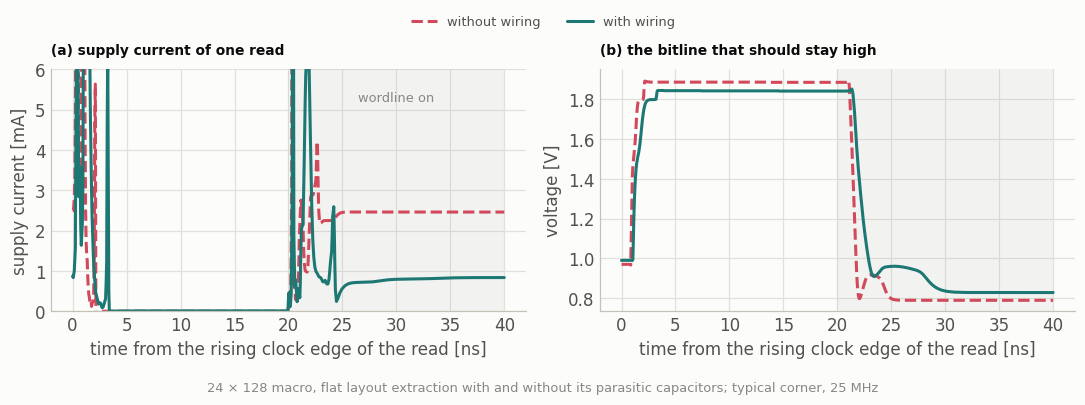

In [69]:
sm = json.loads((ROOT/"results/fullchip/sram_macro_spice.json").read_text())
se4 = json.loads((ROOT/"results/fullchip/sram_energy.json").read_text())
wd = json.loads((ROOT/"results/fullchip/sram_wiring_diagnosis.json").read_text())
macros = pd.DataFrame({m: {"read [pJ]": e["read_pj"], "repeated read [pJ]": e["read_repeat_pj"],
                           "write [pJ]": e["write_pj"], "idle cycle [pJ]": e["idle_pj"],
                           "wiring factor (access)": se4["wiring_factor"]["per_macro"].get(m, {}).get("access")}
                       for m, e in se4["masters"].items()}).T
macros.index = [re.sub(r"sky130_sram_1rw_(\d+)x(\d+).*", r"\1 bits × \2 words", m) for m in macros.index]
nbd.show(macros.round(2).rename_axis("macro, after wiring"), index=True)
wv = pd.read_csv(ROOT/"results/fullchip/sram_wiring_diagnosis_read_cycle.csv")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), sharex=True)
for lab, ls_ in (("without wiring", "--"), ("with wiring", "-")):
    w = wv[wv.netlist == lab]
    ax[0].plot(w.t_ns, w.i_mA, ls=ls_, color=ps.CAT[0] if lab == "with wiring" else ps.CAT[1], label=lab)
    ax[1].plot(w.t_ns, w.br3, ls=ls_, color=ps.CAT[0] if lab == "with wiring" else ps.CAT[1])
for a in ax:
    a.axvspan(20, 40, color=ps.MUTED, alpha=0.08, lw=0)
    a.set_xlabel("time from the rising clock edge of the read [ns]")
ax[0].set_ylim(0, 6); ax[0].set_ylabel("supply current [mA]")
ax[1].set_ylabel("voltage [V]")
ax[0].text(30, 5.2, "wordline on", ha="center", color=ps.MUTED, fontsize=8.5)
ax[0].set_title("(a) supply current of one read", loc="left", fontsize=9)
ax[1].set_title("(b) the bitline that should stay high", loc="left", fontsize=9)
fig.legend(*ax[0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False, fontsize=8.5,
           bbox_to_anchor=(0.5, 1.06))
fig.text(0.5, -0.04, "24 × 128 macro, flat layout extraction with and without its parasitic capacitors; typical corner, 25 MHz",
         ha="center", fontsize=8.5, color=ps.MUTED)
plt.tight_layout(); ps.save_pdf(fig, "sram_read_cycle"); plt.show()
# guards for the statements made in the text above
fac = sorted(f["access"] for f in se4["wiring_factor"]["per_macro"].values())
assert [round(f, 2) for f in (fac[0], fac[-1])] == [0.65, 0.77] and len(fac) == 4   # "the four macro types"
assert len(se4["masters"]) == 7 and sum(v["wiring_factor"] == "mean of the flat layouts" for v in se4["masters"].values()) == 4
assert fac[-1] < 1 and all(1.2 < f["idle"] < 1.45 for f in se4["wiring_factor"]["per_macro"].values())   # "lowers", "about a third"
assert all(all(v["reads_correct"]) and all(v["read_repeat_correct"]) for v in sm["macros"].values())
i_wo, i_w = (wd[k]["settled_current_wordline_on_ma"] for k in ("without_wiring", "with_wiring"))
assert round(i_wo, 1) == 2.5 and round(i_w, 1) == 0.8 and wd["with_wiring"]["clock_high_phase_pj"] > wd["without_wiring"]["clock_high_phase_pj"]
noc = sm["flat_layout_without_wiring_capacitance"]["macros"]["sky130_sram_1rw_24x128"]
sch = sm["macros"]["sky130_sram_1rw_24x128"]
assert abs(noc["read_pj"][0] / np.mean(sch["read_pj"]) - 1) < 0.05 and abs(noc["write_pj"][0] / np.mean(sch["write_pj"]) - 1) < 0.05

### C.5 Where HSKEM-2's registers and macros sit

`scripts/fullchip_blocks.py` attributes every flip-flop and SRAM macro of the flattened layout to its
HSKEM block by its hierarchical name; combinational logic cannot be attributed this way.

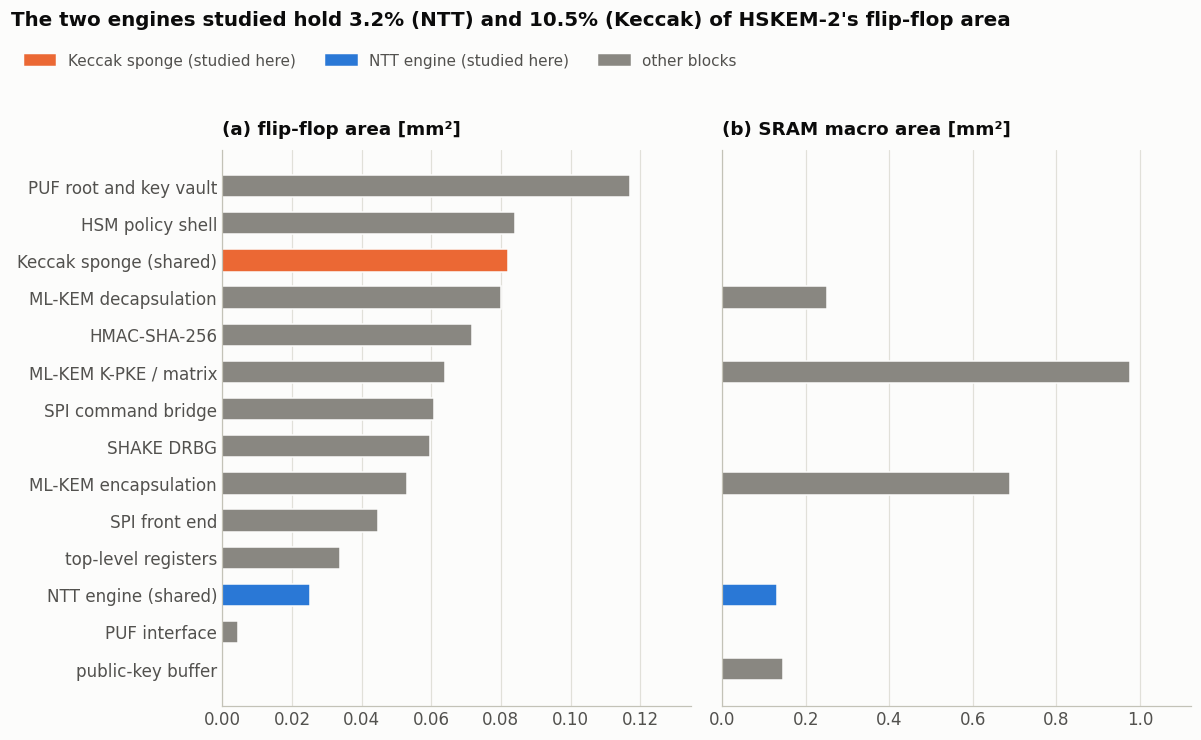

NTT engine: 995 flip-flops (3.2% of the flip-flop area) and one 3072-bit SRAM macro (HSKEM-1: 154 flip-flops, 4096 bits); Keccak sponge: 3279 flip-flops (10.5%) and no SRAM (HSKEM-1, row-serialized: 3606)


In [70]:
blk = pd.read_csv(R9/"blocks.csv").set_index("block")                              # revision C
# the attribution must account for the whole chip
assert abs(blk.flops.sum() - m["finish__design__instance__count__class:sequential_cell"]) <= 5
assert abs(blk.sram_area_um2.sum() - m["finish__design__instance__area__macros"]) / m["finish__design__instance__area__macros"] < 0.001
blk.index = [BLOCK.get(b, b) for b in blk.index]
fig, axes = plt.subplots(1, 2, figsize=(11, 6.2), sharey=True)
rows_ = blk.sort_values("flop_area_um2").index
hl = {"Keccak sponge (shared)": ps.SERIES[1], "NTT engine (shared)": ps.SERIES[0]}
for ax, col, title in [(axes[0], "flop_area_um2", "(a) flip-flop area [mm²]"), (axes[1], "sram_area_um2", "(b) SRAM macro area [mm²]")]:
    vals = blk.loc[rows_, col] / 1e6
    ax.barh(range(len(rows_)), vals, height=0.6, color=[hl.get(r, ps.MUTED) for r in rows_], edgecolor=ps.SURFACE)
    ax.set_title(title); ax.grid(axis="y", visible=False); ax.set_xlim(0, vals.max() * 1.15)
axes[0].set_yticks(range(len(rows_)), rows_)
fig.legend([Patch(color=c) for c in hl.values()] + [Patch(color=ps.MUTED)],
           ["Keccak sponge (studied here)", "NTT engine (studied here)", "other blocks"], ncols=3,
           loc="lower left", bbox_to_anchor=(0.01, 0.975), frameon=False)
_ff = blk.flop_area_um2 / blk.flop_area_um2.sum()
ps.finish(fig, title=f"The two engines studied hold {_ff['NTT engine (shared)']:.1%} (NTT) and "
                     f"{_ff['Keccak sponge (shared)']:.1%} (Keccak) of HSKEM-2's flip-flop area", y=1.08)
plt.show()
tot_ff = blk.flop_area_um2.sum()
blk0 = pd.read_csv(ROOT/"results/fullchip/first_chip/blocks.csv").set_index("block")
print(f"NTT engine: {blk.loc['NTT engine (shared)', 'flops']:.0f} flip-flops "
      f"({blk.loc['NTT engine (shared)', 'flop_area_um2'] / tot_ff:.1%} of the flip-flop area) and one "
      f"{blk.loc['NTT engine (shared)', 'sram_bits']:.0f}-bit SRAM macro "
      f"(HSKEM-1: {blk0.loc['u_shared_ntt', 'flops']} flip-flops, {blk0.loc['u_shared_ntt', 'sram_bits']} bits); "
      f"Keccak sponge: {blk.loc['Keccak sponge (shared)', 'flops']:.0f} flip-flops "
      f"({blk.loc['Keccak sponge (shared)', 'flop_area_um2'] / tot_ff:.1%}) and no SRAM "
      f"(HSKEM-1, row-serialized: {blk0.loc['u_shared_mlkem_sponge', 'flops']})")
# guards for the statements made in the text below
assert 0.02 < blk.loc["NTT engine (shared)", "flop_area_um2"] / tot_ff < 0.04
assert 0.09 < blk.loc["Keccak sponge (shared)", "flop_area_um2"] / tot_ff < 0.11
assert blk.flops.rank(ascending=False)["Keccak sponge (shared)"] == 3
assert blk.loc["Keccak sponge (shared)", "flops"] < blk0.loc["u_shared_mlkem_sponge", "flops"]
assert (blk.loc["NTT engine (shared)", "sram_macros"], blk.loc["NTT engine (shared)", "sram_bits"]) == (1, 24 * 128)

Fill, decoupling and well-tap cells occupy three fifths of the 11.2 mm² die, because the placement density
was held at 41 % so that the wiring of 18 macros could be routed; the logic and the macros take about
2.2 mm² each, and the table counts as fill the 120,858 well-tap cells that ORFS includes among its standard
cells. The largest register banks stay in flip-flops, because the key vault and the HMAC and Keccak states
are read and written in parallel every cycle or erased in one. Moving a bank of a few thousand bits into a
macro would save little anyway: per bit, the chip's two smallest macros cost more than a flip-flop and the
larger ones only somewhat less (printed below the table).

In [71]:
ab = pd.DataFrame(fc["area_by_class"]).T
ab["share of the die [%]"] = 100 * ab.area_mm2 / (m["finish__design__die__area"] / 1e6)
nbd.show(ab.rename(columns={"instances": "instances", "area_mm2": "area [mm²]"}).round(3).rename_axis("cell class, HSKEM-2"), index=True)
cells9 = pd.read_csv(R9/"cells.csv.gz")
mac9 = cells9[cells9.is_macro == 1].assign(a=lambda d: (d.x1 - d.x0) * (d.y1 - d.y0))
bits9 = {mm: int(w) * int(b) for mm, w, b in ((mm, *re.match(r"sky130_sram_1rw_(\d+)x(\d+)", mm).groups()) for mm in mac9.master.unique())}
um2_bit = {mm: mac9[mac9.master == mm].a.iloc[0] / bits9[mm] for mm in bits9}
ff_bit = ab.loc["flip-flops", "area_mm2"] * 1e6 / ab.loc["flip-flops", "instances"]
print("SRAM macro area per bit [µm²]:", {re.sub(r"sky130_sram_1rw_", "", k): round(v, 1) for k, v in sorted(um2_bit.items(), key=lambda kv: kv[1])},
      f"; flip-flop: {ff_bit:.1f} µm² per bit")
# guards for the statements made in the text above
die9 = m["finish__design__die__area"] / 1e6
assert 0.58 < ab.loc["fill and tap", "area_mm2"] / die9 < 0.62                              # "three fifths"
assert round(100 * m["finish__design__instance__utilization"]) == 41
logic9 = ab.drop(["SRAM macros", "fill and tap"]).area_mm2.sum()
assert 2.1 < logic9 < 2.3 and 2.1 < ab.loc["SRAM macros", "area_mm2"] < 2.3                 # "about 2.2 mm² each"
u_ = {re.sub(r"sky130_sram_1rw_", "", k): v for k, v in um2_bit.items()}
assert (round(u_["24x128"]), round(u_["12x256_wpr8"]), round(ff_bit)) == (43, 27, 26)
big_ = [v for k, v in u_.items() if int(re.match(r"\d+x(\d+)", k)[1]) >= 512]
assert 16 <= min(big_) and max(big_) < 19.5 and len(big_) == 4                             # "16 to 19 µm²"
assert ab.loc["flip-flops", "instances"] == m["finish__design__instance__count__class:sequential_cell"]
assert m["finish__design__instance__count__stdcell"] - ab.drop(["SRAM macros", "fill and tap"]).instances.sum() == 120858   # well-tap cells

"cell class, HSKEM-2",instances,area [mm²],share of the die [%]
SRAM macros,18,2.191,19.504
fill and tap,1159465,6.717,59.809
antenna diodes,5470,0.014,0.122
tie cells,87,0.000,0.003
flip-flops,30565,0.781,6.951
clock buffers and inverters,8080,0.132,1.179
buffers and hold delays,15279,0.137,1.220
combinational logic,180016,1.156,10.297


SRAM macro area per bit [µm²]: {'12x768_wpr8': np.float64(16.4), '12x640_wpr8': np.float64(17.5), '12x512_wpr8': np.float64(19.2), '8x768': np.float64(19.3), '24x256': np.float64(23.5), '12x256_wpr8': np.float64(27.1), '24x128': np.float64(43.0)} ; flip-flop: 25.5 µm² per bit


## D. FPGA details

### D.1 Resources and the FPGA store

Quartus stores only 12 bits per coefficient, because the upper four are provably zero. The bitstreams,
which are not published, disable the stand-alone NTT self-test, so the board observes the NTT only within
the flows of Section 10.

In [72]:
display(pd.DataFrame({k: v for k, v in fr.items() if isinstance(v, dict)}).T)
# guards for the statements made in the text above
ntt_fpga = fr["kyber_ntt_engine (u_shared_ntt)"]
assert 100 < float(ntt_fpga["alms_needed"].split()[0]) < 1000
assert (ntt_fpga["m20k"], ntt_fpga["dsp"], ntt_fpga["block_memory_bits"]) == ("1", "2", "3072")

,ALMs,registers,block-memory bits,M20K blocks,DSP blocks
NTT engine,375.3 (255.6),176 (176),3072,1,2
Keccak permutation (one round per clock),1881.5 (1881.5),1997 (1997),0,0,0
"Keccak sponge, including the permutation",4008.2 (2126.7),4046 (2049),0,0,0


### D.2 The host link

The ESP32 drives the board over a bit-banged SPI link at a nominal 10 kHz, chosen for robustness, so the
FPGA phases take a few milliseconds of an 8.6 s run; the effective rate printed in Section 10 follows from
the logged latency and the 3,136 payload bytes per run.

### D.3 The board builds of the redesigned systems

| Board build | Step D build | Final streamed build |
|:---|---:|---:|
| encapsulation [cycles] | about 32,200 | about 7,200 |
| final ciphertext check [cycles] | 5,380 | 908 |
| ALMs | not recorded | about 3,500 more than the original FPGA configuration, 91 % of the device |
| setup slack at 50 MHz [ns] | 1.75 (from its 54.8 MHz fmax) | 0.43 |

An intermediate streamed build, with J moved into the re-encryption, read 13,098 cycles per decapsulation, and the
final streamed build without the session changes read the same 6,858 cycles in five runs. The session log of the
board build also records a failed PUF and vault restore: the ESP32 holds helper data enrolled with an earlier
bitstream, so the PUF root and the vault are not claimed for this build.
In the streamed builds the self-test's fixed operands come from the key memories, which removes the
timing failure of the first compilation (Section 12) and changes no cycle and no result.

## E. Reproducing every result

### E.1 Run time in Colab

A `Run all` took 15 minutes in a clean Ubuntu 22.04 container with Colab's settings and four cores, mostly in Sections 4, 5 and 7 and Appendix B; a free Colab instance has two cores, and a full run there took about 35 minutes.
The last cell reports the time per section (the stored table is from a local run). Cells marked `RUN_…` repeat the long runs and are off by default, except
`RUN_ACVP_RTL` and `RUN_GLS`, which run in Colab only.

### E.2 Place-and-route, locally or in Colab

| Tool | Version used for the committed results |
|:---|:---|
| Icarus Verilog | 12.0; 11.0 for the chip-level simulations of the signed-off layout (the OSS CAD Suite of Colab ships 14-devel) |
| YosysHQ OSS CAD Suite | 2026-09-28: Yosys with the `slang` front end |
| OpenROAD-flow-scripts | commit `6101364b`, OpenROAD `f5522624` with its OpenSTA |
| KLayout, Magic, ngspice | 0.30.7; 8.3.629; 41 (conda-forge) |
| Netgen | 6.2, for the LVS of the signed-off layout |
| Python | 3.10 locally; Colab's default in Colab |
| Python packages | NumPy, pandas, Matplotlib, `kyber-py` 1.2.0 |
| Quartus Prime Pro | 26.1, the only non-open tool, for the FPGA cross-check |

Place-and-route takes eight minutes to three and a half hours per design point. `RUN_PNR = True` in the Setup cell
regenerates the committed results on Linux with ORFS at commit `6101364b`, and the README lists the
commands behind every other result; the chip-level results of HSKEM-2 start from the routed database of
the release `hskem2-rev-c` (`flow/chip_rev_c/README.md`), while those of HSKEM-1 and of HSKEM-2's first
layout need their private databases (Section 13). Without ORFS, `RUN_PNR_COLAB = True` downloads an archive
of the very ORFS build used here, repeats the pipelined-NTT run and compares it with the committed one; the
lines below record how the archive reproduced three design points in a clean container.

In [73]:
bundle = json.loads((ROOT/"results/asic/bundle_reproduction.json").read_text())
for chk in bundle["checks"]:
    print(f"{nbd.label(chk['committed']):<34} {chk['label']}: {chk['identical']} of {chk['metrics_compared']} final metrics identical")
assert all(chk["identical"] == chk["metrics_compared"] for chk in bundle["checks"])

RUN_PNR_COLAB = False     # True: about 130 MB download and 30-45 minutes on a free Colab instance
BUNDLE_URL = ("https://github.com/tandat08052007/sscs-ose-code-a-chip.github.io/releases/download/"
              "hskem-orfs-6101364b/orfs-6101364b-sky130hd.tar.xz")
if RUN_PNR_COLAB:
    bdir = pathlib.Path("/content" if IN_COLAB else pathlib.Path.home())
    if not (bdir/"orfs").exists():
        import hashlib
        arc = bdir/"orfs-6101364b-sky130hd.tar.xz"
        got = subprocess.run(["curl", "-fsSL", "-o", str(arc), BUNDLE_URL])
        if got.returncode:
            raise RuntimeError(f"Download of the ORFS bundle failed (curl exit status {got.returncode}): {BUNDLE_URL}")
        if hashlib.sha256(arc.read_bytes()).hexdigest() != bundle["bundle_sha256"]:
            raise RuntimeError(f"The downloaded ORFS bundle does not match the recorded SHA-256 {bundle['bundle_sha256']}; delete {arc.name} and try again.")
        print("ORFS bundle downloaded; SHA-256 matches results/asic/bundle_reproduction.json")
        if subprocess.run(["tar", "xJf", str(arc), "-C", str(bdir)]).returncode:
            raise RuntimeError(f"The ORFS bundle {arc.name} could not be extracted.")
        arc.unlink()
    work = bdir/"cac_runs"
    target = work/"ntt_opt_pipe_w12_20ns_colab/logs/sky130hd/cac_ntt_opt_pipe_w12_20ns/base/6_report.log"
    sh(f"ORFS_ROOT={bdir}/orfs OPENROAD_EXE={bdir}/orfs/bin/openroad YOSYS_EXE={bdir}/orfs/bin/yosys "
       f"CAC_WORK={work} CAC_TAG_SUFFIX=_colab CAC_TARGET={target} bash scripts/run_orfs.sh ntt_opt_pipe_w12 20")
    print(sh("python3 scripts/compare_runs.py ntt_opt_pipe_w12_20ns ntt_opt_pipe_w12_20ns_colab")[:2000])

iteration 1: 12-bit store + pipeline, 20 ns clean ubuntu:22.04 container (udocker), 12 threads: 67 of 67 final metrics identical
iteration 1: 12-bit store + pipeline, 20 ns clean ubuntu:22.04 container (udocker), 2 threads, as on a free Colab instance: 67 of 67 final metrics identical
original NTT, single-port store, 20 ns clean ubuntu:22.04 container (udocker), 12 threads: 67 of 67 final metrics identical
Keccak, one round per clock, 20 ns clean ubuntu:22.04 container (udocker), 12 threads: 67 of 67 final metrics identical


### E.3 The published RTL

`hskem_rtl/` differs from the source tree only as documented in `PUBLICATION_PATCH.diff`: the board's
provisioning test credential is replaced by a public placeholder and the testbench's two provisioning tags
are recomputed. `scripts/make_packed_system.py` builds the redesigned systems of Section 8 from this copy, each edit
behind a define after asserting that its anchor occurs exactly once, and records the edits in `results/system_sim/packed_system.diff`; without the defines the built system repeats the
published one cycle for cycle. Its session logic is the earlier one, which the FPGA configuration also runs: the
epoch is a fixed label plus the host's binding counter, unique only until reset, the send counter only has to
increase, so that a compromised host can obtain tags for future counters until the next binding, and a refused
binding consumes its counter. The signed-off chip adds the changes of Section 13 behind a
compile-time switch (`flow/chip_rev_c/rtl/revc_edit.py`).

`flow/chip_rev_c/formal/` states six properties of that session logic on the ports of `hsm_shell`, in the chip's
configuration, with the HMAC outside the shell so that its timing and digests are free inputs. SymbiYosys with Bitwuzla checks
them for 48 cycles from reset, with the rejection limit lowered from 16 to 2 so that the lock comes within reach. A
reachability task shows that a binding, sealed and received frames and the lock all occur.
k-induction passes its base case but not its induction step, so these are bounded checks, not proofs.

In [74]:
fm = json.loads((ROOT/"results/fullchip/rev_c/session_formal.json").read_text())
display(pd.Series(fm["properties"], name="property").to_frame())
display(pd.DataFrame(fm["tasks"]).T[["checks", "depth", "status", "elapsed_s"]].rename_axis("task"))
ft = fm["tasks"]
assert fm["hsm_shell_sha256"] in (R9/"root_sha256.txt").read_text()                                   # the RTL of the signed-off chip
assert (ft["props_bmc"]["status"], ft["miter_bmc"]["status"], ft["props_cover"]["status"]) == ("PASS", "PASS", "PASS")
assert ft["props_bmc"]["depth"] == ft["miter_bmc"]["depth"] == 48 and ft["props_cover"]["cover_traces"] == 4
assert (fm["rejection_limit_in_the_model"], fm["rejection_limit_on_the_chip"]) == (2, 16) and len(fm["properties"]) == 6
assert all(ft[t]["basecase"] == "pass" and ft[t]["induction_step"] == "FAIL" and ft[t]["status"] == "UNKNOWN" for t in ("props_prove", "miter_prove"))

,property
P1,no bit of K reaches the host: two copies that differ only in K give identical responses
P2,"a sealed frame's counter is exactly the previous one plus one, starting at 1"
P3,an accepted frame carries the epoch of the current binding and a counter above the last accepted
P4,after the rejection limit no frame is accepted until the next binding or zeroisation
P5,a binding is refused as a replay only if an earlier successful command used that counter or a later one
P6,"a binding succeeds only with a nonce ready, returns that nonce as its epoch and consumes it"


task,checks,depth,status,elapsed_s
props_cover,"reachability of a binding, a sealed frame, a received frame and the lock",40,PASS,8
props_bmc,"P2 to P6, bounded",48,PASS,300
props_prove,"P2 to P6, k-induction",12,UNKNOWN,9
miter_bmc,"P1, two copies differing only in K, bounded",48,PASS,4573
miter_prove,"P1, k-induction",12,UNKNOWN,33


### E.4 Unit tests of the analysis scripts

The scripts that turn simulation output into numbers are tested on small inputs with hand-computed
results; `scripts/prose_number_coverage.py` counts the prose numbers tied to the data.

In [75]:
out = sh("python3 -m pytest -q -p no:cacheprovider tests")
assert " passed" in out and "failed" not in out and "error" not in out.lower()

....                                                                     [100%]
4 passed in 0.12s
 


In [76]:
cov = json.loads((ROOT/"results/prose_number_coverage.json").read_text())      # rewritten by scripts/prose_number_coverage.py after a full run
print(f"numbers in the prose of the body: {cov['total']}; asserted {cov['asserted']}, shown in an executed output {cov['shown']}, "
      f"neither {cov['neither']} ({cov['covered_pct']} % covered)")
print("not tied to the data (definitions, a download size, one figure from an uncommitted development log):",
      "; ".join(f"{', '.join(v)} ({t if not t.startswith('(') else 'a code-cell comment'})" for t, v in cov["neither_by_section"].items()))
assert cov["covered_pct"] >= 95

numbers in the prose of the body: 261; asserted 230, shown in an executed output 25, neither 6 (97.7 % covered)
not tied to the data (definitions, a download size, one figure from an uncommitted development log): 700 (0. Setup); 1600 (1. Context: where these blocks sit in HSKEM); 1600, 644, 3.7536 (a code-cell comment); 24.9 (Things that looked right and were not)


**Reuse and AI assistance.** No existing notebook was reused, and apart from the third-party material in
`NOTICE` (SKY130 cell models, NIST ACVP vectors) and the OpenRAM views and netlists of the SRAM macros,
all code was written for this project. Claude (Anthropic) assisted with debugging, with launching and
monitoring long runs and with bookkeeping; the design, the measurements and every claim are the
author's responsibility.

### References
1. NIST, FIPS 203, *Module-Lattice-Based Key-Encapsulation Mechanism Standard*, 2024. doi:10.6028/NIST.FIPS.203.
2. NIST, FIPS 202, *SHA-3 Standard: Permutation-Based Hash and Extendable-Output Functions*, 2015.
   doi:10.6028/NIST.FIPS.202.
3. NIST, ACVP-Server test vectors for ML-KEM, https://github.com/usnistgov/ACVP-Server.
4. G. Bertoni, J. Daemen, M. Peeters, G. Van Assche, *The Keccak reference*, version 3.0, 2011.
5. P. Barrett, "Implementing the Rivest Shamir and Adleman public key encryption algorithm on a standard
   digital signal processor", *Advances in Cryptology — CRYPTO '86*, Springer, 1987.
   doi:10.1007/3-540-47721-7_24.
6. G. Goodwill, B. Jun, J. Jaffe, P. Rohatgi, "A testing methodology for side-channel resistance
   validation", NIST Non-Invasive Attack Testing Workshop, 2011.
7. O. Reparaz, S. Sinha Roy, F. Vercauteren, I. Verbauwhede, "A masked ring-LWE implementation",
   *Cryptographic Hardware and Embedded Systems — CHES 2015*, Springer, 2015. doi:10.1007/978-3-662-48324-4_34.
8. T. Ajayi et al., "Toward an open-source digital flow: first learnings from the OpenROAD project",
   *Design Automation Conference (DAC)*, 2019, doi:10.1145/3316781.3326334; OpenROAD-flow-scripts,
   https://github.com/The-OpenROAD-Project/OpenROAD-flow-scripts.
9. M. R. Guthaus et al., "OpenRAM: an open-source memory compiler", *International Conference on
   Computer-Aided Design (ICCAD)*, 2016. doi:10.1145/2966986.2980098.
10. SkyWater Technology and Google, SKY130 open-source PDK, https://github.com/google/skywater-pdk.
11. YosysHQ, Yosys and the OSS CAD Suite, https://github.com/YosysHQ/oss-cad-suite-build; the `slang`
    front end, https://github.com/povik/yosys-slang; Icarus Verilog, https://github.com/steveicarus/iverilog.
12. G. Pope, `kyber-py`, https://github.com/GiacomoPope/kyber-py.
13. Y. Xing, S. Li, "A compact hardware implementation of CCA-secure key exchange mechanism
    CRYSTALS-KYBER on FPGA", *IACR Transactions on Cryptographic Hardware and Embedded Systems*,
    2021(2), pp. 328–356. doi:10.46586/tches.v2021.i2.328-356.
14. U. Banerjee, T. S. Ukyab, A. P. Chandrakasan, "Sapphire: a configurable crypto-processor for
    post-quantum lattice-based protocols", *IACR Transactions on Cryptographic Hardware and Embedded
    Systems*, 2019(4), pp. 17–61. doi:10.46586/tches.v2019.i4.17-61.
15. L. Botros, M. J. Kannwischer, P. Schwabe, "Memory-efficient high-speed implementation of Kyber on
    Cortex-M4", *Progress in Cryptology — AFRICACRYPT 2019*, Springer, 2019, pp. 209–228.
    doi:10.1007/978-3-030-23696-0_11.
16. A. Abdulrahman et al., "Towards ML-KEM & ML-DSA on OpenTitan", *IEEE Symposium on Security and Privacy*, 2025,
    doi:10.1109/SP61157.2025.00220; lowRISC, OpenTitan key manager, https://opentitan.org/book/hw/ip/keymgr/.
17. CHIPS Alliance, Caliptra hardware specification, version 2.1, https://github.com/chipsalliance/caliptra-rtl.
18. S. Kent, "IP Encapsulating Security Payload (ESP)", RFC 4303, 2005, section 3.4.3.
19. H. S. Ogawa, T. B. Paiva, M. A. Simplicio Jr, S. M. Hafiz, B. Yildiz, "Efficient conflict-free NTT hardware
    architecture with single-port RAMs: applications to ML-DSA", IACR Cryptology ePrint Archive, 2026/621.
20. E. Camacho-Ruiz, P. Navarro-Torrero, A. Cabrera Aldaya, "A framework for designing high-order side-channel
    protected hardware implementations of ML-KEM", *IACR TCHES*, vol. 2026, no. 2, pp. 272–295,
    doi:10.46586/tches.v2026.i2.272-295; code: https://github.com/HWSec-CSIC/hope-mlkem.
21. D. Ranney, Y. I. Makaram, A. A. Ding, Y. Fei, "Exploring side-channel protections in hardware implementations
    of PQC ML-KEM verification", arXiv:2606.31681, 2026.
22. T.-H. Nguyen, D.-T. Dam, P.-P. Duong, B. Kieu-Do-Nguyen, C.-K. Pham, T.-T. Hoang, "Efficient hardware implementation of the
    lightweight CRYSTALS-Kyber", *IEEE Transactions on Circuits and Systems I: Regular Papers*, vol. 72, no. 2, pp. 610–622, 2025,
    doi:10.1109/TCSI.2024.3443238.
23. P. Fan, Z. Yan, W. Guan, L. Liang, "A high-performance ML-KEM architecture with task-level parallelism",
    *IEEE Transactions on Very Large Scale Integration (VLSI) Systems*, vol. 34, no. 6, pp. 1786–1799, 2026,
    doi:10.1109/TVLSI.2026.3677808.
24. T.-H. Nguyen, T.-K. Dang, D.-T. Dam, K.-D. Nguyen, P.-P. Duong, C.-K. Pham, T.-T. Hoang, "An area-time efficient hardware
    architecture for ML-KEM post-quantum cryptography standard", *IEEE Access*, vol. 13, pp. 103834–103847, 2025,
    doi:10.1109/ACCESS.2025.3579379.

In [77]:
# the timer starts with the third code cell; earlier cells (clone, tool download) count in the total only
SECTIONS = ['0. Setup', '0. Setup', '1. Context', '2. An independent golden model', '2. An independent golden model', '3. RTL architecture and an analytical cycle model', '3. RTL architecture and an analytical cycle model', '3. RTL architecture and an analytical cycle model', '4. RTL against the golden model and the NIST vectors', '4. RTL against the golden model and the NIST vectors', '4. RTL against the golden model and the NIST vectors', '4. RTL against the golden model and the NIST vectors', '5. Synthesis', '5. Synthesis', '6. Place-and-route', '6. Place-and-route', '6. Place-and-route', '6. Place-and-route', '7. Closing the loop', '7. Closing the loop', '7. Closing the loop', '7. Closing the loop', '7. Closing the loop', '7. Closing the loop', '7. Closing the loop', '7. Closing the loop', '8. The whole co-processor', '8. The whole co-processor', '8. The whole co-processor', '8. The whole co-processor', '8. The whole co-processor', '8. The whole co-processor', '8. The whole co-processor', '9. HSKEM-2', '9. HSKEM-2', '9. HSKEM-2', '10. The same RTL on the FPGA board', '10. The same RTL on the FPGA board', '10. The same RTL on the FPGA board', '10. The same RTL on the FPGA board', '10. The same RTL on the FPGA board', '11. What is not yet protected', '11. What is not yet protected', '12. What transfers', '12. What transfers', '12. What transfers', '12. What transfers', 'A. Verification details', 'A. Verification details', 'A. Verification details', 'A. Verification details', 'B. Place-and-route details', 'B. Place-and-route details', 'B. Place-and-route details', 'B. Place-and-route details', 'B. Place-and-route details', 'B. Place-and-route details', 'B. Place-and-route details', 'B. Place-and-route details', 'B. Place-and-route details', 'B. Place-and-route details', 'B. Place-and-route details', 'C. Chip-level details of HSKEM-2', 'C. Chip-level details of HSKEM-2', 'C. Chip-level details of HSKEM-2', 'C. Chip-level details of HSKEM-2', 'C. Chip-level details of HSKEM-2', 'C. Chip-level details of HSKEM-2', 'C. Chip-level details of HSKEM-2', 'D. FPGA details', 'E. Reproducing every result', 'E. Reproducing every result', 'E. Reproducing every result', 'E. Reproducing every result']
total = (time.time() - T_START) / 60
if len(nbd.DURATIONS) == len(SECTIONS):          # a single top-to-bottom run
    t = pd.Series(nbd.DURATIONS, index=SECTIONS).groupby(level=0, sort=False).sum() / 60
    t["Setup and untimed cells"] = total - t.sum()
    nbd.show(t.round(1).rename("minutes").rename_axis("Section").reset_index())
display(Markdown(f"**Notebook finished in {total:.1f} min** ({'Colab' if IN_COLAB else 'local'} run)."))

**Notebook finished in 0.7 min** (local run).